In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Load the data
df = pd.read_csv('/content/drive/MyDrive/crwu-qauntum/mrmr_best13_binary_1161.csv')

# Separate features and labels
features = df.drop('Label', axis=1)
labels = df['Label']

# Print the shape of features and labels
print('features: {}'.format(features.shape))
print('labels: {}'.format(labels.shape))

# Feature scaling using MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))  # Adjust range here if needed
features_scaled = scaler.fit_transform(features)

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    features_scaled, labels, train_size=0.9, random_state=1234
)

# Print the shape of training and test features
print('train_features: {}'.format(X_train.shape))
print('test_features: {}'.format(X_test.shape))


features: (2322, 13)
labels: (2322,)
train_features: (2089, 13)
test_features: (233, 13)


# **1. ExtraTreesClassifier**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import ExtraTreesClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different values of n_estimators, max_depth, and min_samples_split
n_estimators_values = [50, 100, 150]
max_depth_values = [None, 10, 20]
min_samples_split_values = [2, 5, 10]

model_no = 1

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for min_samples_split in min_samples_split_values:
            # Initialize the ExtraTreesClassifier
            etc = ExtraTreesClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_split=min_samples_split)

            # Start the timer for fitting
            fit_start = time.time()

            # Fit the model to the training data
            etc.fit(X_train, y_train)

            # Stop the timer for fitting
            fit_end = time.time()
            fit_time = fit_end - fit_start

            # Start the timer for prediction
            pred_start_train = time.time()
            y_pred_train = etc.predict(X_train)
            pred_end_train = time.time()
            train_pred_time = pred_end_train - pred_start_train

            pred_start_test = time.time()
            y_pred_test = etc.predict(X_test)
            pred_end_test = time.time()
            test_pred_time = pred_end_test - pred_start_test

            # Confusion matrices for train and test
            conf_matrix_train = confusion_matrix(y_train, y_pred_train)
            conf_matrix_test = confusion_matrix(y_test, y_pred_test)

            # Classification reports for train and test
            train_report = classification_report(y_train, y_pred_train, output_dict=True)
            test_report = classification_report(y_test, y_pred_test, output_dict=True)

            # Append metrics to the results list
            results.append({
                'Model no': model_no,
                'No of estimators': n_estimators,
                'Max depth': max_depth,
                'Min samples split': min_samples_split,
                'Model fit time (s)': fit_time,
                'Train TP': conf_matrix_train[1, 1],
                'Train TN': conf_matrix_train[0, 0],
                'Train FP (Type I Error)': conf_matrix_train[0, 1],
                'Train FN (Type II Error)': conf_matrix_train[1, 0],
                'Train Accuracy': train_report['accuracy'] * 100,
                'Train Precision': train_report['macro avg']['precision'] * 100,
                'Train Recall': train_report['macro avg']['recall'] * 100,
                'Train F1': train_report['macro avg']['f1-score'] * 100,
                'Train Prediction time (s)': train_pred_time,
                'Test TP': conf_matrix_test[1, 1],
                'Test TN': conf_matrix_test[0, 0],
                'Test FP (Type I Error)': conf_matrix_test[0, 1],
                'Test FN (Type II Error)': conf_matrix_test[1, 0],
                'Test Accuracy': test_report['accuracy'] * 100,
                'Test Precision': test_report['macro avg']['precision'] * 100,
                'Test Recall': test_report['macro avg']['recall'] * 100,
                'Test F1': test_report['macro avg']['f1-score'] * 100,
                'Test Prediction time (s)': test_pred_time
            })

            model_no += 1

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save the results to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/ExtraTreesClassifier.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")

# Rank models based on test accuracy
comparison_df['ranking'] = comparison_df['Test Accuracy']  # or another metric if preferred
comparison_df = comparison_df.sort_values(by='ranking', ascending=False)

# Print and rank models in equation form
print("\nRanked Models:")
equation_format = []
for index, row in comparison_df.iterrows():
    equation_format.append(f"Model {row['Model no']} ({row['Test Accuracy']:.2f}%)")

# Create the equations in the required format
for i in range(len(equation_format)):
    if i < len(equation_format) - 1:
        print(f"{equation_format[i]} > ", end="")
    else:
        print(equation_format[i])  # Print last model without " > "

# Optionally, you can also print specific metrics for each model
print("\nRanked Models Details:")
for index, row in comparison_df.iterrows():
    print(f"Model {row['Model no']}: Test TP={row['Test TP']}, Test TN={row['Test TN']}, "
          f"Test FP={row['Test FP (Type I Error)']}, Test FN={row['Test FN (Type II Error)']}, "
          f"Test Accuracy={row['Test Accuracy']:.2f}%, "
          f"Test Precision={row['Test Precision']:.2f}, Test Recall={row['Test Recall']:.2f}, Test F1={row['Test F1']:.2f}")


    Model no  No of estimators  Max depth  Min samples split  \
0          1                50        NaN                  2   
1          2                50        NaN                  5   
2          3                50        NaN                 10   
3          4                50       10.0                  2   
4          5                50       10.0                  5   
5          6                50       10.0                 10   
6          7                50       20.0                  2   
7          8                50       20.0                  5   
8          9                50       20.0                 10   
9         10               100        NaN                  2   
10        11               100        NaN                  5   
11        12               100        NaN                 10   
12        13               100       10.0                  2   
13        14               100       10.0                  5   
14        15               100       10.

# **2. KNeighborsClassifier**

<Figure size 600x400 with 0 Axes>

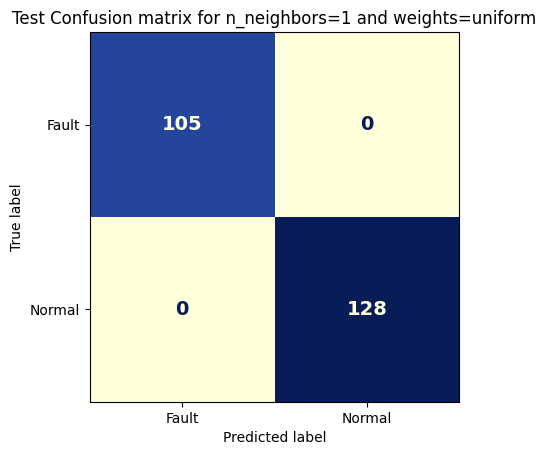

<Figure size 600x400 with 0 Axes>

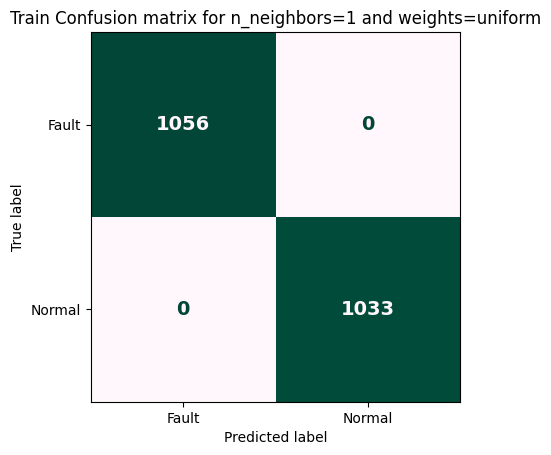

<Figure size 600x400 with 0 Axes>

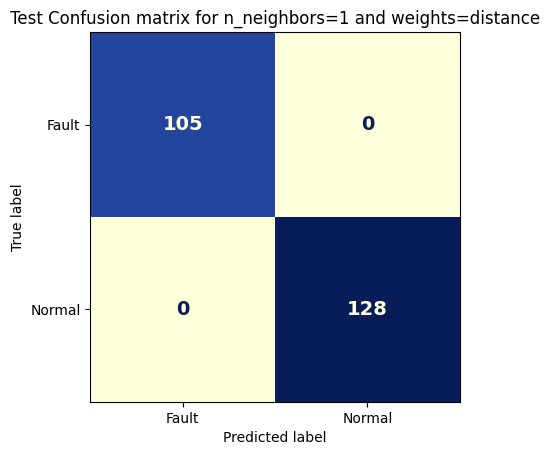

<Figure size 600x400 with 0 Axes>

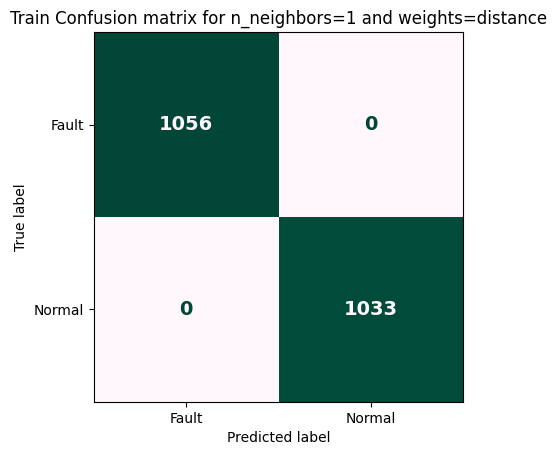

<Figure size 600x400 with 0 Axes>

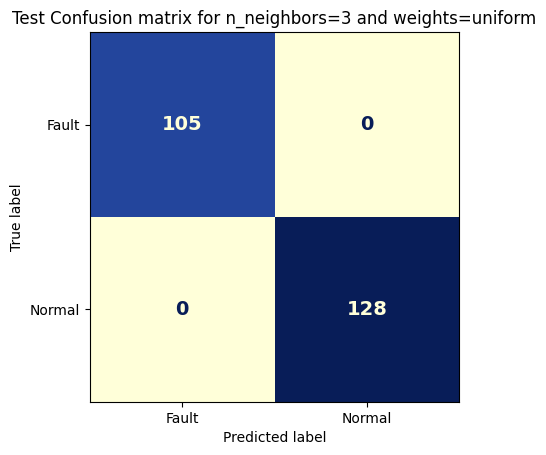

<Figure size 600x400 with 0 Axes>

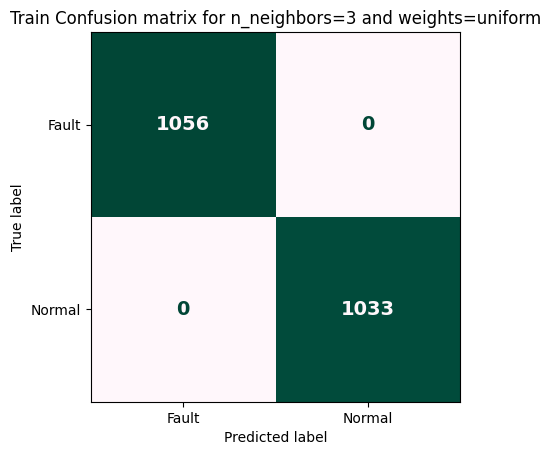

<Figure size 600x400 with 0 Axes>

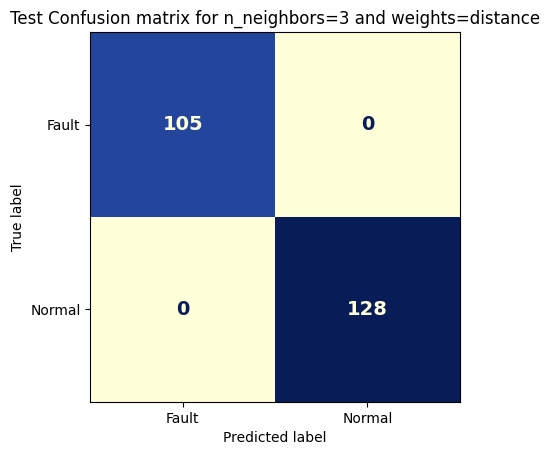

<Figure size 600x400 with 0 Axes>

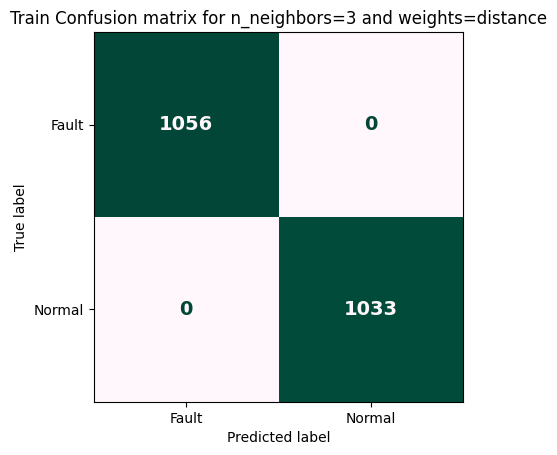

<Figure size 600x400 with 0 Axes>

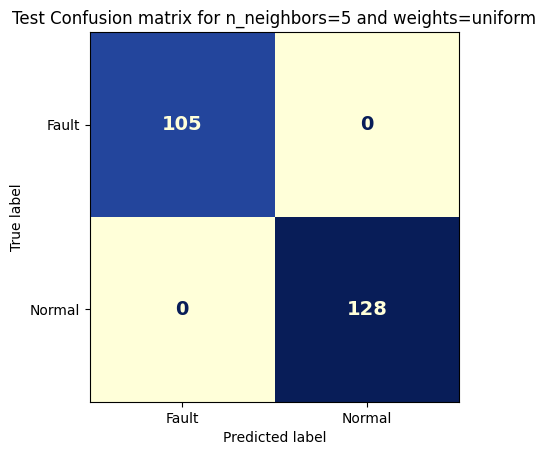

<Figure size 600x400 with 0 Axes>

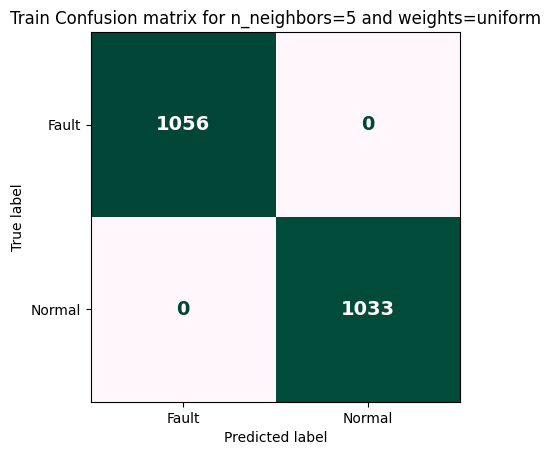

<Figure size 600x400 with 0 Axes>

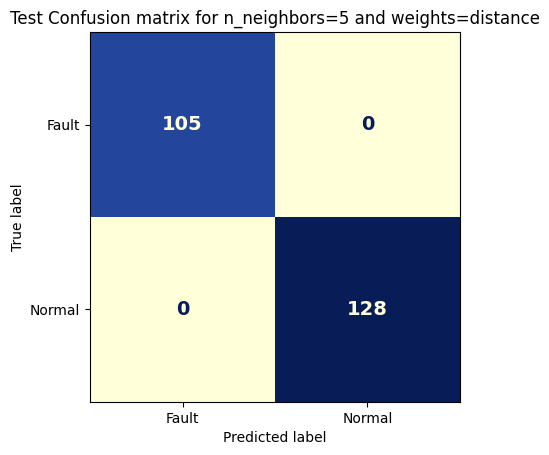

<Figure size 600x400 with 0 Axes>

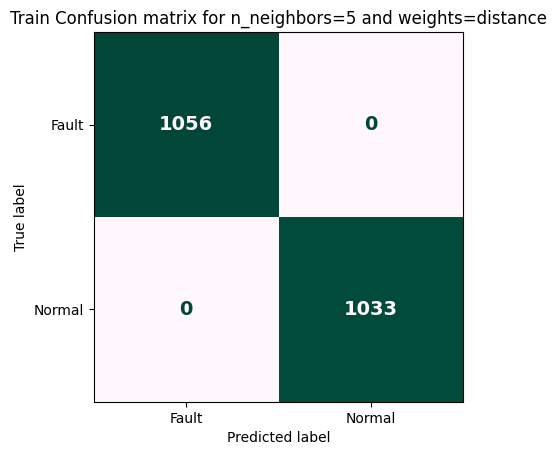

<Figure size 600x400 with 0 Axes>

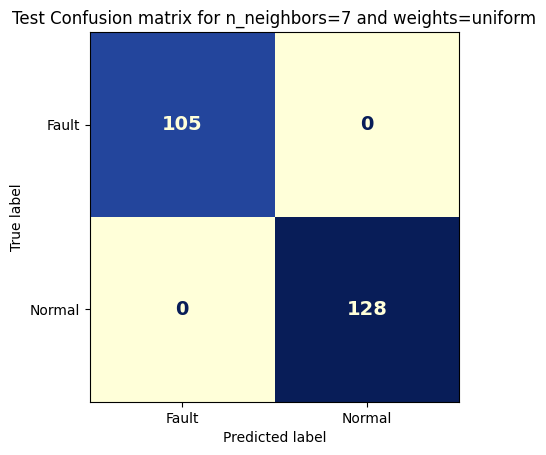

<Figure size 600x400 with 0 Axes>

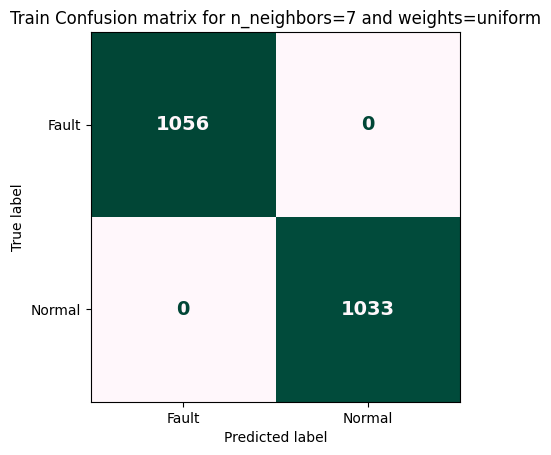

<Figure size 600x400 with 0 Axes>

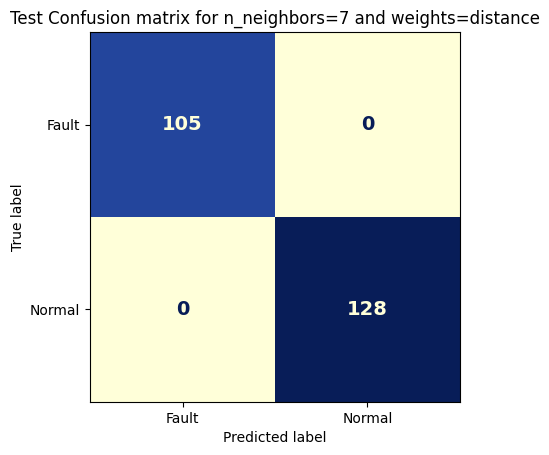

<Figure size 600x400 with 0 Axes>

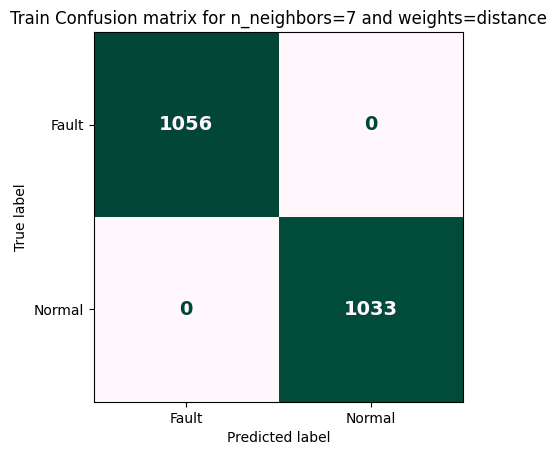

<Figure size 600x400 with 0 Axes>

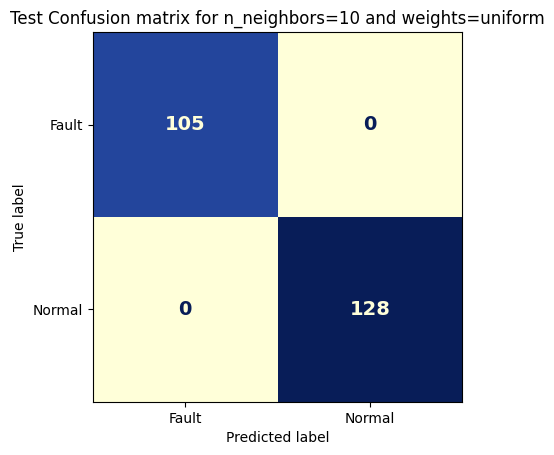

<Figure size 600x400 with 0 Axes>

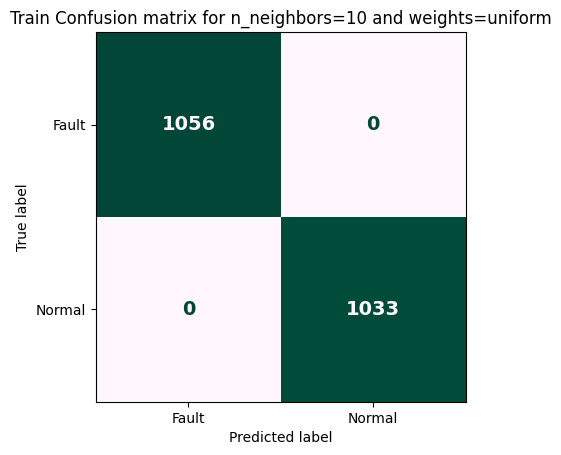

<Figure size 600x400 with 0 Axes>

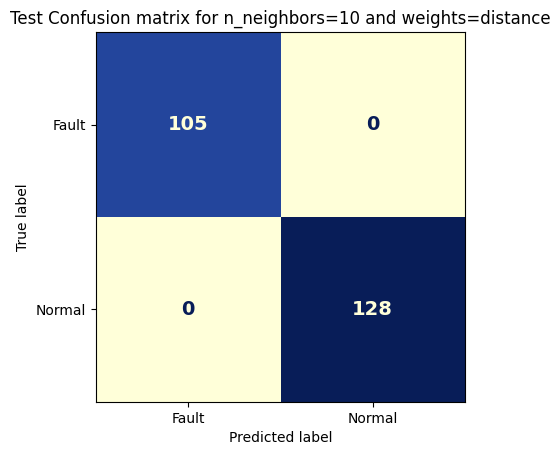

<Figure size 600x400 with 0 Axes>

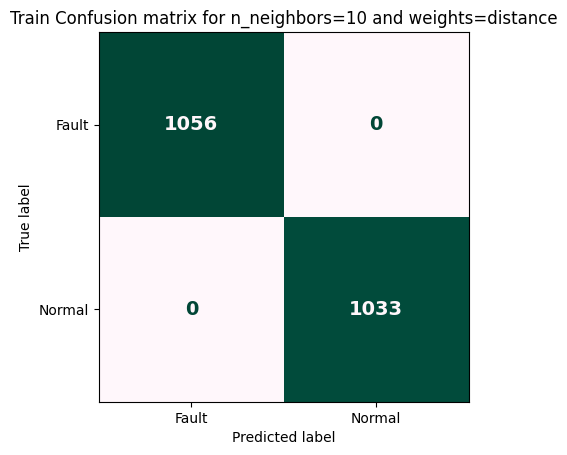

<Figure size 600x400 with 0 Axes>

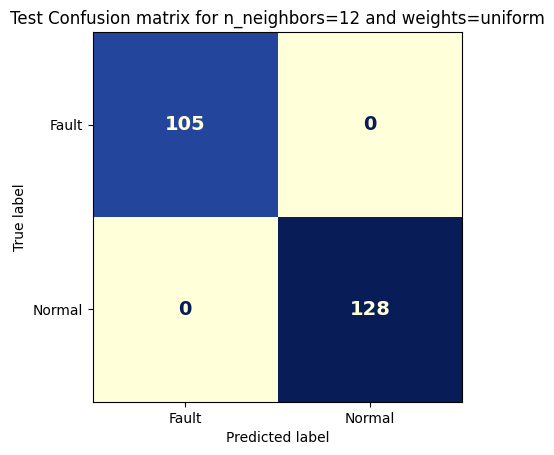

<Figure size 600x400 with 0 Axes>

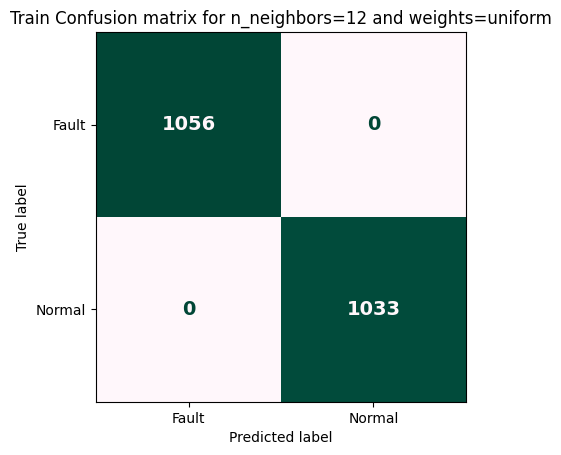

<Figure size 600x400 with 0 Axes>

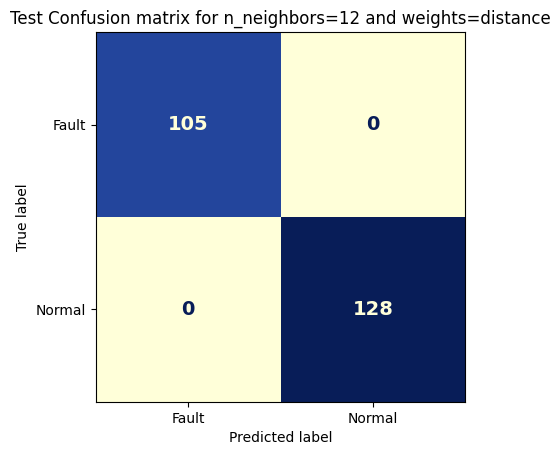

<Figure size 600x400 with 0 Axes>

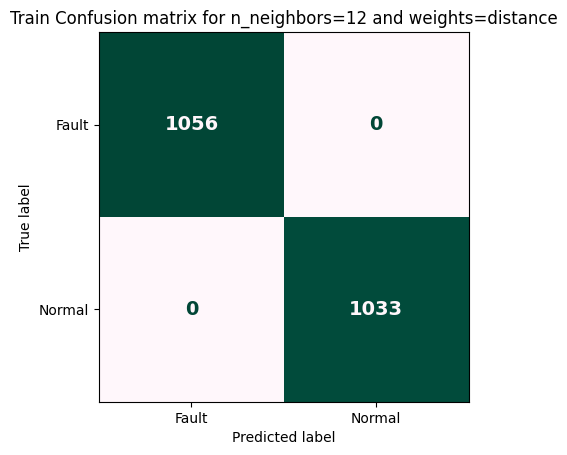

<Figure size 600x400 with 0 Axes>

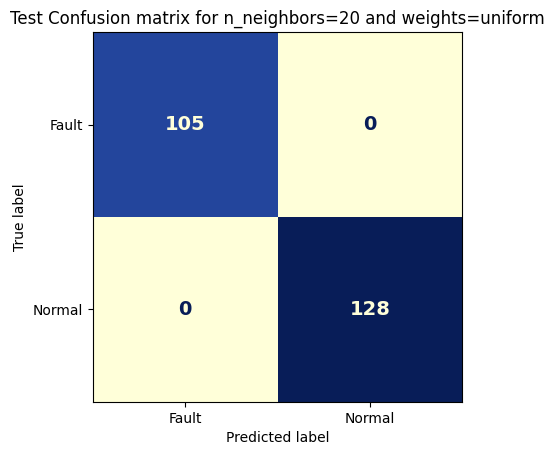

<Figure size 600x400 with 0 Axes>

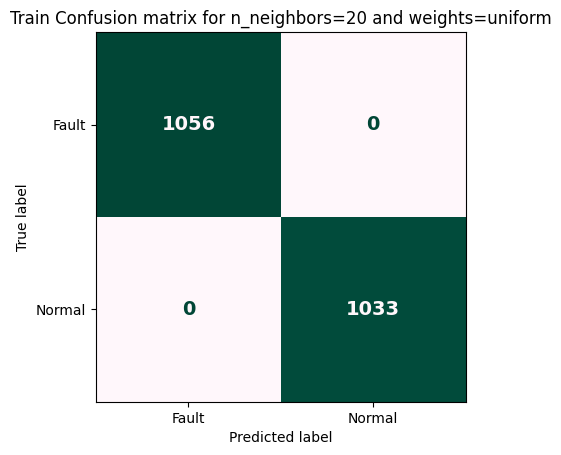

<Figure size 600x400 with 0 Axes>

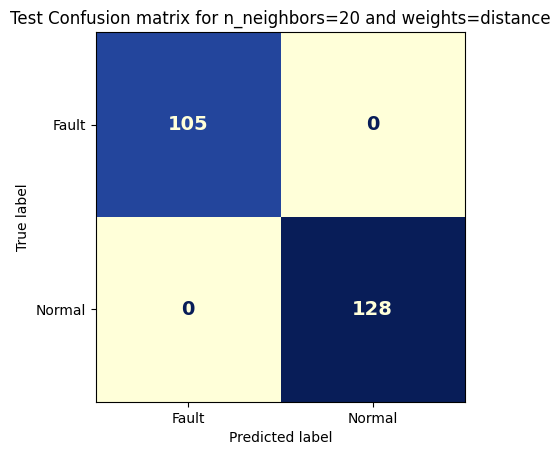

<Figure size 600x400 with 0 Axes>

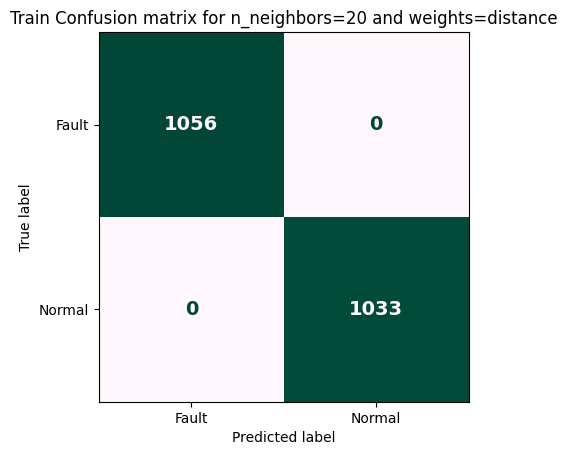

    n_neighbors   weights  model_fit_time  train_accuracy  test_accuracy  \
0             1   uniform        0.272290             1.0            1.0   
1             1  distance        0.047379             1.0            1.0   
2             3   uniform        0.149860             1.0            1.0   
3             3  distance        0.050098             1.0            1.0   
4             5   uniform        0.170487             1.0            1.0   
5             5  distance        0.060464             1.0            1.0   
6             7   uniform        0.161814             1.0            1.0   
7             7  distance        0.061944             1.0            1.0   
8            10   uniform        0.196189             1.0            1.0   
9            10  distance        0.061699             1.0            1.0   
10           12   uniform        0.172805             1.0            1.0   
11           12  distance        0.063710             1.0            1.0   
12          

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
import time
import pandas as pd

# Assuming X_train, X_test, y_train, y_test are already defined

# Convert the data to C-contiguous order
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different values of n_neighbors and weights
for n_neighbors in [1, 3, 5, 7, 10, 12, 20]:
    for weights in ['uniform', 'distance']:
        # Initialize the KNeighborsClassifier
        knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights)
        # Start the timer
        start = time.time()
        # Fit the model to the training data
        knn.fit(X_train, y_train)
        # Make predictions on the training data
        y_train_pred = knn.predict(X_train)
        # Make predictions on the test data
        y_test_pred = knn.predict(X_test)
        # Stop the timer
        end = time.time()
        # Compute the confusion matrix for train and test sets
        confusion_train = confusion_matrix(y_train, y_train_pred)
        confusion_test = confusion_matrix(y_test, y_test_pred)
        # Calculate classification metrics for train and test sets
        train_report = classification_report(y_train, y_train_pred, output_dict=True)
        test_report = classification_report(y_test, y_test_pred, output_dict=True)

        # Extract TP, TN, FP, FN for test set
        TN = confusion_test[0, 0]
        FP = confusion_test[0, 1]
        FN = confusion_test[1, 0]
        TP = confusion_test[1, 1]

        # Append metrics to the results list
        results.append({
            'n_neighbors': n_neighbors,
            'weights': weights,
            'model_fit_time': end - start,
            'train_accuracy': train_report['accuracy'],
            'test_accuracy': test_report['accuracy'],
            'train_precision': train_report['macro avg']['precision'],
            'test_precision': test_report['macro avg']['precision'],
            'train_recall': train_report['macro avg']['recall'],
            'test_recall': test_report['macro avg']['recall'],
            'train_f1': train_report['macro avg']['f1-score'],
            'test_f1': test_report['macro avg']['f1-score'],
            'test_tp': TP,
            'test_tn': TN,
            'test_fp': FP,
            'test_fn': FN,
        })

        # Draw the confusion matrix for test data (without colorbar)
        plt.figure(figsize=(6, 4))
        disp_test = ConfusionMatrixDisplay(confusion_matrix=confusion_test, display_labels=np.unique(y_test))
        disp_test.plot(cmap='YlGnBu', values_format='d', colorbar=False)  # Remove colorbar
        plt.title(f'Test Confusion matrix for n_neighbors={n_neighbors} and weights={weights}')
        # Customize the text properties inside the ConfusionMatrixDisplay
        for text in disp_test.text_.ravel():
            text.set_fontsize(14)
            text.set_fontweight('bold')
        plt.show()

        # Draw the confusion matrix for training data (without colorbar)
        plt.figure(figsize=(6, 4))
        disp_train = ConfusionMatrixDisplay(confusion_matrix=confusion_train, display_labels=np.unique(y_train))
        disp_train.plot(cmap='PuBuGn', values_format='d', colorbar=False)  # Remove colorbar
        plt.title(f'Train Confusion matrix for n_neighbors={n_neighbors} and weights={weights}')
        # Customize the text properties inside the ConfusionMatrixDisplay
        for text in disp_train.text_.ravel():
            text.set_fontsize(14)
            text.set_fontweight('bold')
        plt.show()

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save the DataFrame to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/knn_landmine_binary.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Read the CSV file into a DataFrame
results_df = comparison_df

# Print the total number of models trained
total_models_trained = len(results_df)
print(f"Total models trained: {total_models_trained}")

# Rank models based on test metrics
results_df['ranking'] = results_df['test_f1'] + results_df['test_recall'] + results_df['test_precision'] + results_df['test_accuracy']
results_df = results_df.sort_values(by='ranking', ascending=False)

# Print the ranked models in equation form
print("\nRanked Models:")
for index, row in results_df.iterrows():
    model_equation = f"Model {index + 1} ({row['test_accuracy'] * 100:.2f}%) >"
    print(model_equation)

# Optionally, you can also print specific metrics for each model
print("\nRanked Models Details:")
for index, row in results_df.iterrows():
    print(f"Model {index + 1}: Test TP={row['test_tp']}, Test TN={row['test_tn']}, Test FP={row['test_fp']}, "
          f"Test FN={row['test_fn']}, Test Accuracy={row['test_accuracy'] * 100:.2f}%, "
          f"Test Precision={row['test_precision']:.2f}, Test Recall={row['test_recall']:.2f}, Test F1={row['test_f1']:.2f}")


# **3. DecisionTreeClassifier 4. RandomForestClassifier**

Decision Tree Results:


<Figure size 600x400 with 0 Axes>

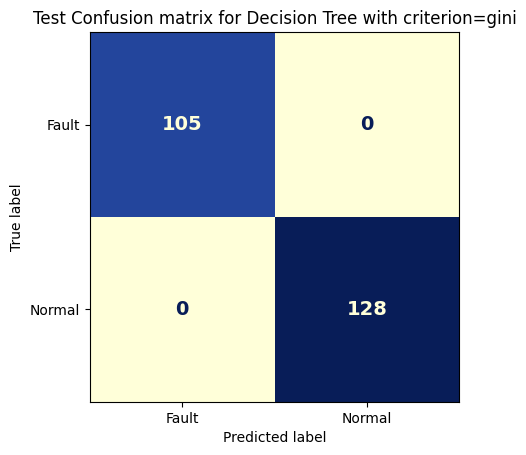

<Figure size 600x400 with 0 Axes>

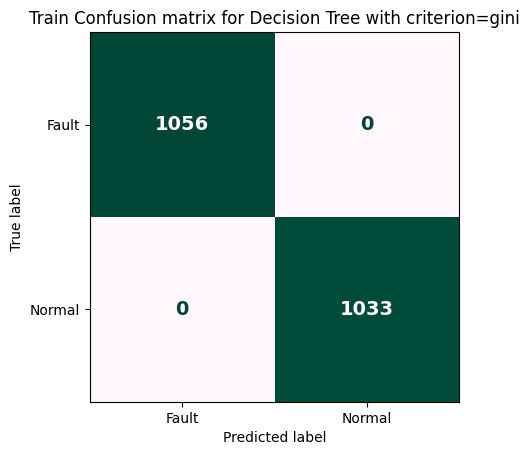

<Figure size 600x400 with 0 Axes>

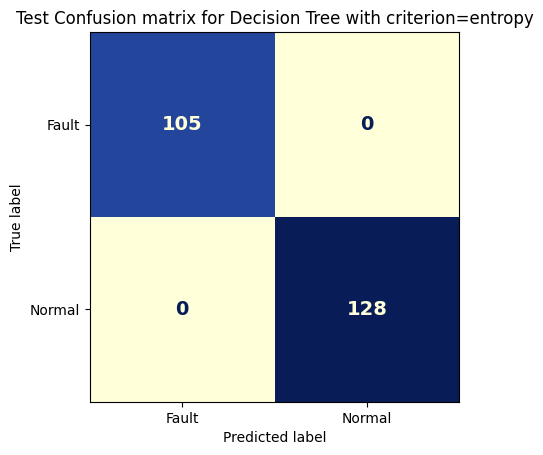

<Figure size 600x400 with 0 Axes>

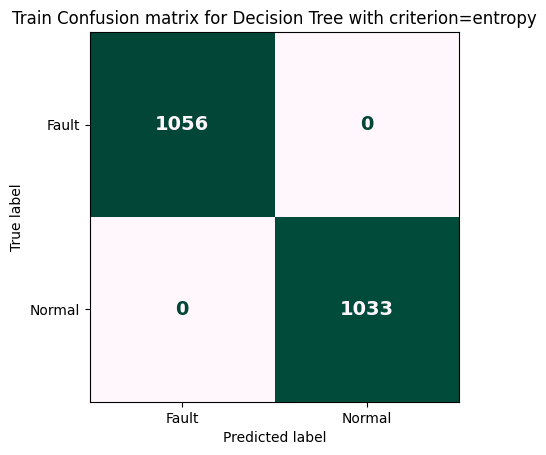

Random Forest Results:


<Figure size 600x400 with 0 Axes>

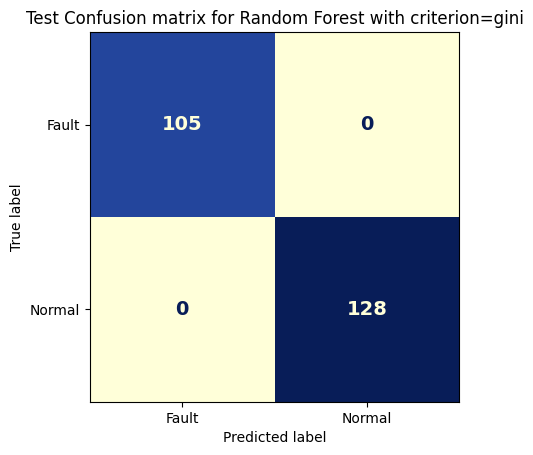

<Figure size 600x400 with 0 Axes>

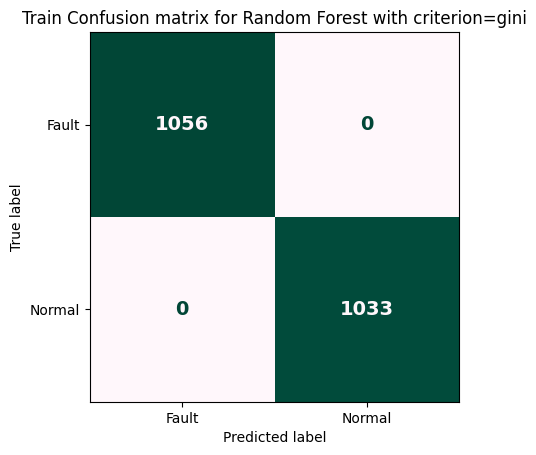

<Figure size 600x400 with 0 Axes>

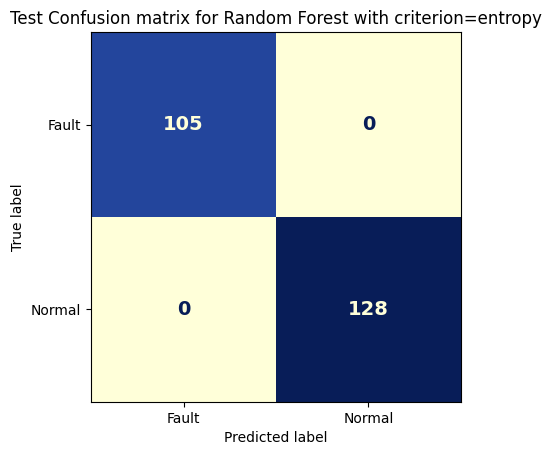

<Figure size 600x400 with 0 Axes>

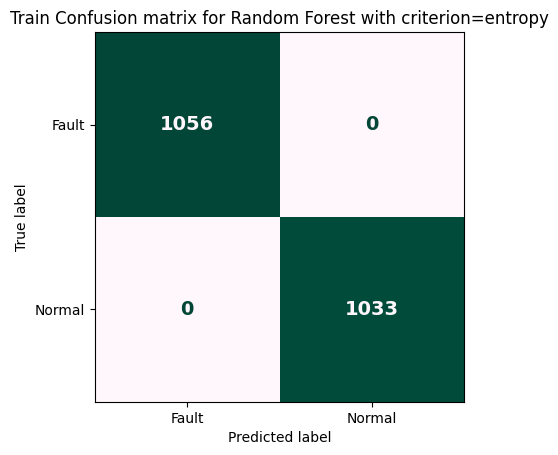

      classifier criterion  model_fit_time  train_TP  train_TN  train_FP  \
0  Decision Tree      gini        0.368321      1033      1056         0   
1  Decision Tree   entropy        0.324425      1033      1056         0   
2  Random Forest      gini        1.090467      1033      1056         0   
3  Random Forest   entropy        1.182490      1033      1056         0   

   train_FN  train_accuracy  train_precision  train_recall  ...  \
0         0           100.0            100.0         100.0  ...   
1         0           100.0            100.0         100.0  ...   
2         0           100.0            100.0         100.0  ...   
3         0           100.0            100.0         100.0  ...   

   train_prediction_time  test_TP  test_TN  test_FP  test_FN  test_accuracy  \
0               0.368321      128      105        0        0          100.0   
1               0.324425      128      105        0        0          100.0   
2               1.090467      128      105    

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Define the classifier types
classifiers = [
    ("Decision Tree", DecisionTreeClassifier()),
    ("Random Forest", RandomForestClassifier())
]

# Define the different criterion for Decision Tree and Random Forest
criterion = {
    "Decision Tree": ["gini", "entropy"],
    "Random Forest": ["gini", "entropy"]
}

# Initialize lists to store the metrics for train and test sets
results = []

for classifier_name, clf in classifiers:
    print(f"{classifier_name} Results:")

    for c in criterion[classifier_name]:
        # Start the timer
        start = time.time()
        clf.set_params(criterion=c)
        clf.fit(X_train, y_train)

        train_score = clf.score(X_train, y_train)
        test_score = clf.score(X_test, y_test)

        y_pred_train = clf.predict(X_train)
        confusion_train = confusion_matrix(y_train, y_pred_train)
        train_report = classification_report(y_train, y_pred_train, output_dict=True)

        y_pred_test = clf.predict(X_test)
        confusion_test = confusion_matrix(y_test, y_pred_test)
        test_report = classification_report(y_test, y_pred_test, output_dict=True)

        # Stop the timer
        end = time.time()

        # Append metrics to the results list
        results.append({
            'classifier': classifier_name,
            'criterion': c,
            'model_fit_time': end - start,
            'train_TP': confusion_train[1, 1],
            'train_TN': confusion_train[0, 0],
            'train_FP': confusion_train[0, 1],
            'train_FN': confusion_train[1, 0],
            'train_accuracy': train_report['accuracy'] * 100,
            'train_precision': train_report['macro avg']['precision'] * 100,
            'train_recall': train_report['macro avg']['recall'] * 100,
            'train_f1': train_report['macro avg']['f1-score'] * 100,
            'train_prediction_time': end - start,
            'test_TP': confusion_test[1, 1],
            'test_TN': confusion_test[0, 0],
            'test_FP': confusion_test[0, 1],
            'test_FN': confusion_test[1, 0],
            'test_accuracy': test_report['accuracy'] * 100,
            'test_precision': test_report['macro avg']['precision'] * 100,
            'test_recall': test_report['macro avg']['recall'] * 100,
            'test_f1': test_report['macro avg']['f1-score'] * 100,
            'test_prediction_time': end - start
        })

        # Draw the confusion matrix for test data
        plt.figure(figsize=(6, 4))
        disp_test = ConfusionMatrixDisplay(confusion_matrix=confusion_test, display_labels=np.unique(y_test))
        disp_test.plot(cmap='YlGnBu', values_format='d', colorbar=False)  # Remove colorbar
        plt.title(f'Test Confusion matrix for {classifier_name} with criterion={c}')
        for text in disp_test.text_.ravel():
            text.set_fontsize(14)
            text.set_fontweight('bold')
        plt.show()

        # Draw the confusion matrix for training data
        plt.figure(figsize=(6, 4))
        disp_train = ConfusionMatrixDisplay(confusion_matrix=confusion_train, display_labels=np.unique(y_train))
        disp_train.plot(cmap='PuBuGn', values_format='d', colorbar=False)  # Remove colorbar
        plt.title(f'Train Confusion matrix for {classifier_name} with criterion={c}')
        for text in disp_train.text_.ravel():
            text.set_fontsize(14)
            text.set_fontweight('bold')
        plt.show()

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save the results for Decision Tree to an Excel file
decision_tree_results = comparison_df[comparison_df['classifier'] == 'Decision Tree']
decision_tree_excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/DT.xlsx'
decision_tree_results.to_excel(decision_tree_excel_filename, index=False)
print(f'Decision Tree results saved to {decision_tree_excel_filename}')

# Save the results for Random Forest to an Excel file
random_forest_results = comparison_df[comparison_df['classifier'] == 'Random Forest']
random_forest_excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/RF.xlsx'
random_forest_results.to_excel(random_forest_excel_filename, index=False)
print(f'Random Forest results saved to {random_forest_excel_filename}')

# Rank models based on test metrics (F1, Recall, Precision, Accuracy)
ranking_criteria = ['test_f1', 'test_recall', 'test_precision', 'test_accuracy']
comparison_df['rank'] = comparison_df[ranking_criteria].mean(axis=1)

# Sort the DataFrame based on the ranking
sorted_comparison_df = comparison_df.sort_values(by='rank', ascending=False)

# Print ranking equations
print("\nModel Rankings:")
for index, row in sorted_comparison_df.iterrows():
    print(f"Model {index + 1} ({row['test_accuracy']:.2f}%) > ", end="")
    if index + 1 < len(sorted_comparison_df):
        next_row = sorted_comparison_df.iloc[index + 1]
        print(f"Model {index + 2} ({next_row['test_accuracy']:.2f}%)")
    else:
        print("None")

# Save the ranked models to Excel
ranked_models_filename = '/content/drive/MyDrive/crwu-qauntum/ranked_models_DT-RF.xlsx'
sorted_comparison_df.to_excel(ranked_models_filename, index=False)
print(f'Ranked models saved to {ranked_models_filename}')

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")


# **5. SVM**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.svm import SVC
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different kernels for SVM
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
model_no = 1  # Initialize model number

for kernel in kernels:
    # Initialize the SVM classifier with the specified kernel
    svm = SVC(kernel=kernel, C=10000)

    # Start the timer
    start = time.time()

    # Fit the model to the training data
    svm.fit(X_train, y_train)

    # Make predictions on the training data and test data
    y_pred_train = svm.predict(X_train)
    y_pred_test = svm.predict(X_test)

    # Calculate confusion matrices
    conf_matrix_train = confusion_matrix(y_train, y_pred_train)
    conf_matrix_test = confusion_matrix(y_test, y_pred_test)

    # Stop the timer
    end = time.time()

    # Append metrics to the results list
    results.append({
        'Model No': model_no,
        'Classifier': 'SVC',
        'Criterion': kernel,
        'Model Fit Time': end - start,
        'Train TP': conf_matrix_train[1, 1],
        'Train TN': conf_matrix_train[0, 0],
        'Train FP (Type I Error)': conf_matrix_train[0, 1],
        'Train FN (Type II Error)': conf_matrix_train[1, 0],
        'Train Accuracy': svm.score(X_train, y_train),
        'Train Precision': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['precision'],
        'Train Recall': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['recall'],
        'Train F1': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['f1-score'],
        'Train Prediction Time': end - start,
        'Test TP': conf_matrix_test[1, 1],
        'Test TN': conf_matrix_test[0, 0],
        'Test FP (Type I Error)': conf_matrix_test[0, 1],
        'Test FN (Type II Error)': conf_matrix_test[1, 0],
        'Test Accuracy': svm.score(X_test, y_test),
        'Test Precision': classification_report(y_test, y_pred_test, output_dict=True)['macro avg']['precision'],
        'Test Recall': classification_report(y_test, y_pred_test, output_dict=True)['macro avg']['recall'],
        'Test F1': classification_report(y_test, y_pred_test, output_dict=True)['macro avg']['f1-score'],
        'Test Prediction Time': end - start
    })

    # Increment model number
    model_no += 1

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save the results to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/SVM_results.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Ranking models based on test F1, Recall, Precision, and Accuracy
comparison_df['Rank'] = comparison_df['Test F1'].rank(ascending=False, method='dense')

# Print and rank models
ranked_models = comparison_df.sort_values(by=['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy'], ascending=False)
ranked_model_str = ' > '.join([f'Model {int(row["Model No"])} ({row["Test F1"]:.2f})' for _, row in ranked_models.iterrows()])
print(ranked_model_str)

# Save ranked models to another Excel file
ranked_model_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/ranked_SVM_models.xlsx'
ranked_models.to_excel(ranked_model_filename, index=False)
print(f'Ranked models saved to {ranked_model_filename}')

# Find the row with the best test accuracy
best_model_row = comparison_df.loc[comparison_df['Test Accuracy'].idxmax()]

# Print information about the best model
print("Best Model Results:")
print(f"Kernel: {best_model_row['Criterion']}")
print(f"Train Accuracy: {best_model_row['Train Accuracy']:.2f}")
print(f"Test Accuracy: {best_model_row['Test Accuracy']:.2f}")
print(f"Train Precision: {best_model_row['Train Precision']:.2f}")
print(f"Test Precision: {best_model_row['Test Precision']:.2f}")
print(f"Train Recall: {best_model_row['Train Recall']:.2f}")
print(f"Test Recall: {best_model_row['Test Recall']:.2f}")

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")


   Model No Classifier Criterion  Model Fit Time  Train TP  Train TN  \
0         1        SVC    linear        0.041111      1033      1056   
1         2        SVC      poly        0.026211      1033      1056   
2         3        SVC       rbf        0.031484      1033      1056   
3         4        SVC   sigmoid        0.090399       965       988   

   Train FP (Type I Error)  Train FN (Type II Error)  Train Accuracy  \
0                        0                         0        1.000000   
1                        0                         0        1.000000   
2                        0                         0        1.000000   
3                       68                        68        0.934897   

   Train Precision  ...  Train Prediction Time  Test TP  Test TN  \
0         1.000000  ...               0.041111      128      105   
1         1.000000  ...               0.026211      128      105   
2         1.000000  ...               0.031484      128      105   
3     

# ** 6. MLPClassifier**

Hidden Layer Sizes: (25,)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

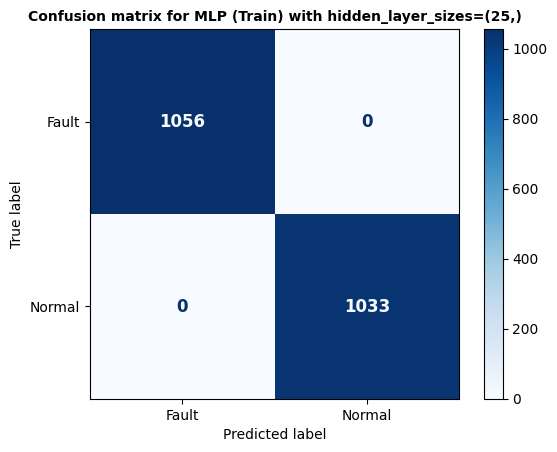

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

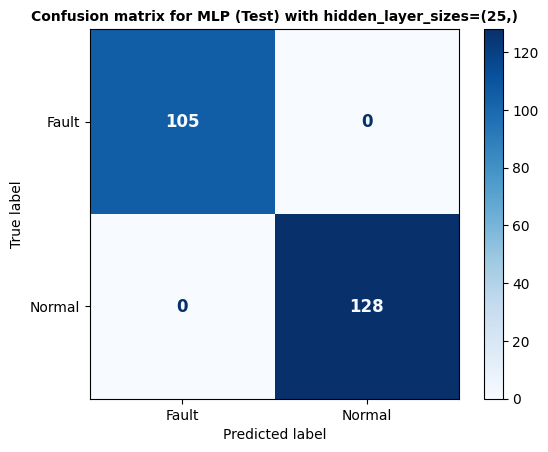

Hidden Layer Sizes: (50,)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

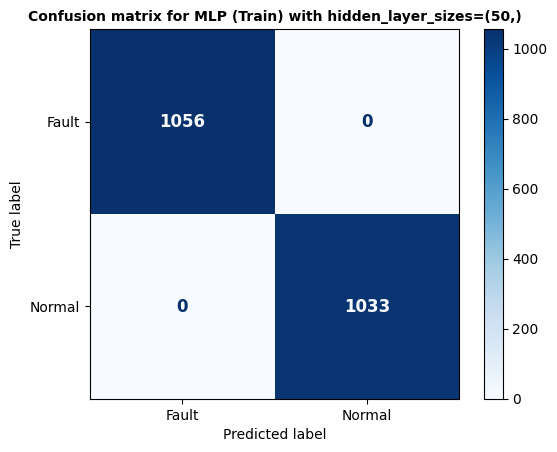

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

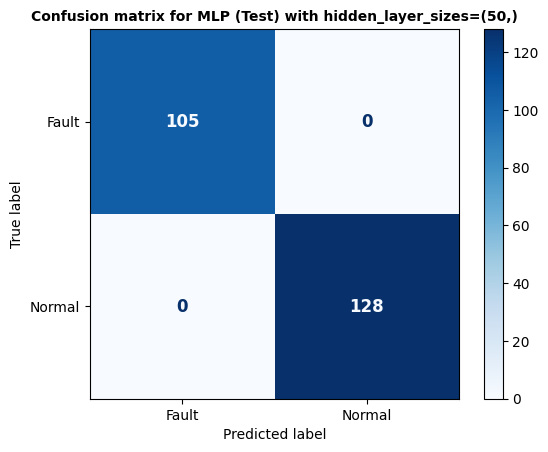

Hidden Layer Sizes: (100,)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

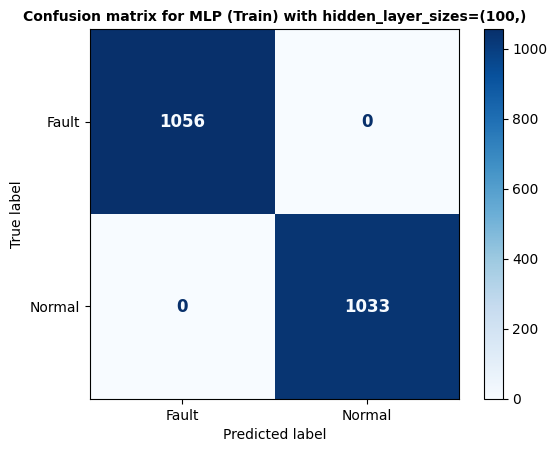

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

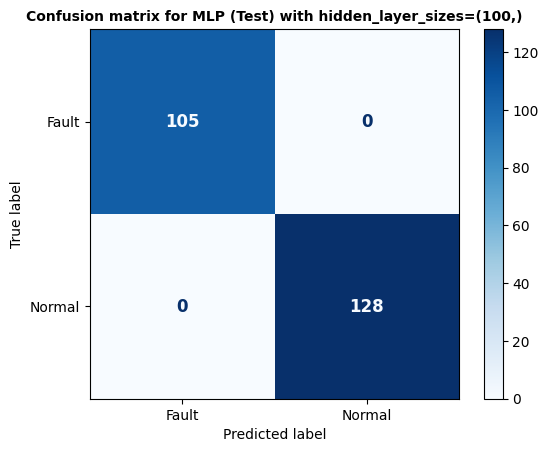

Hidden Layer Sizes: (25, 25)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

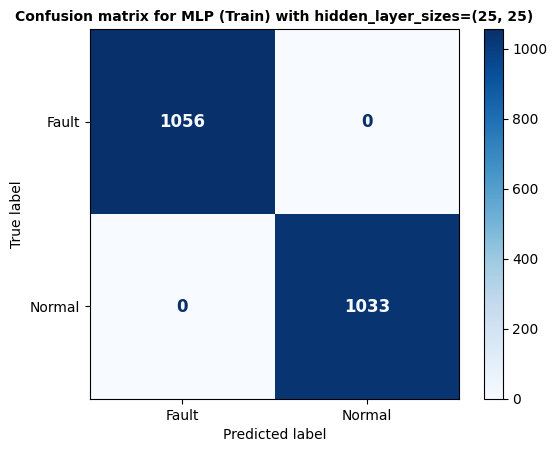

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

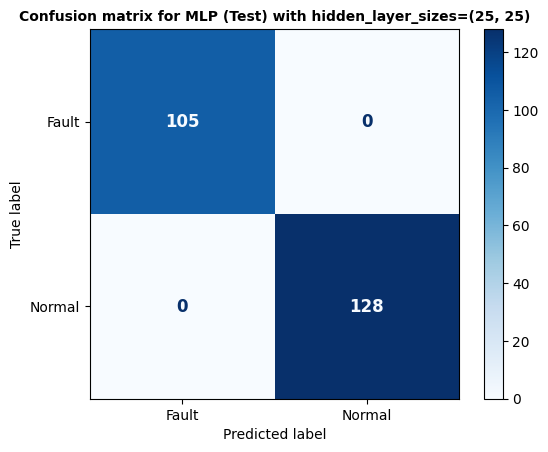

Hidden Layer Sizes: (50, 50)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

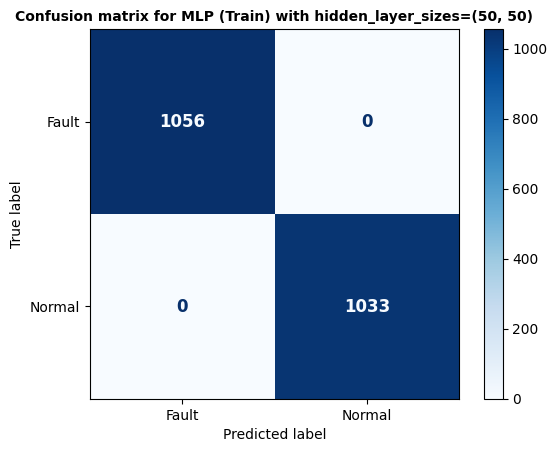

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

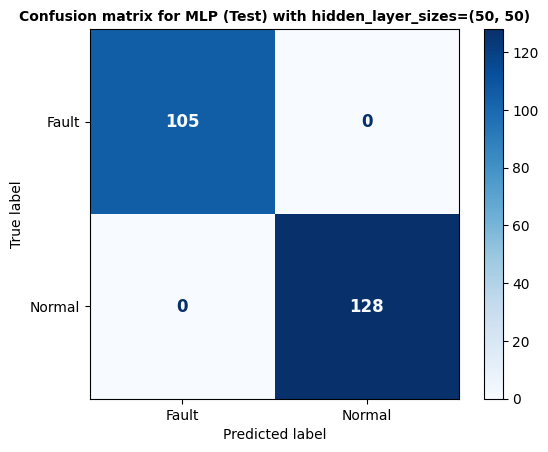

Hidden Layer Sizes: (75, 75)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

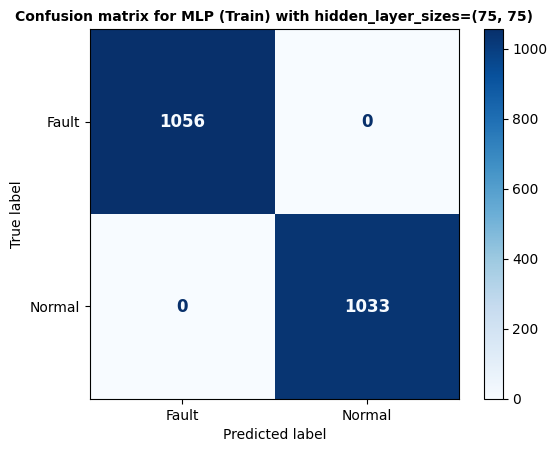

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

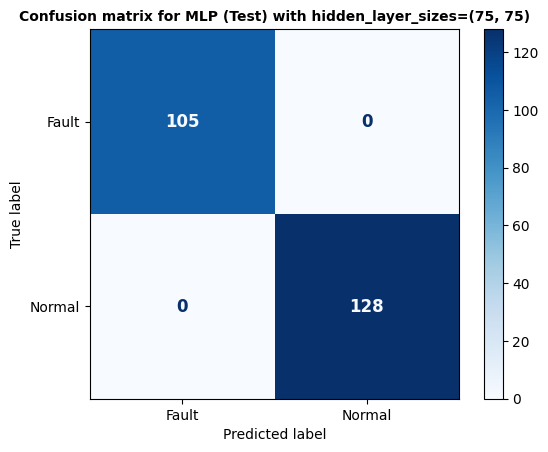

Hidden Layer Sizes: (100, 50)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

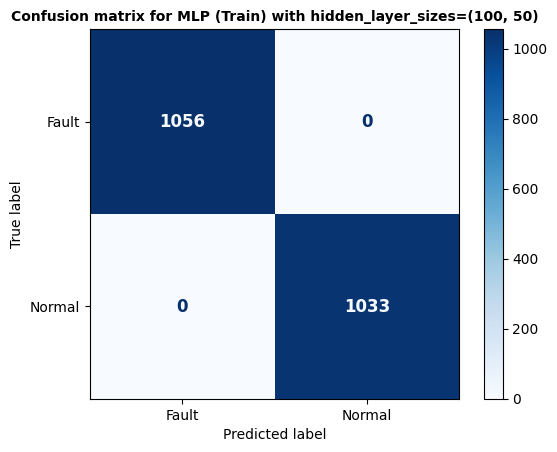

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

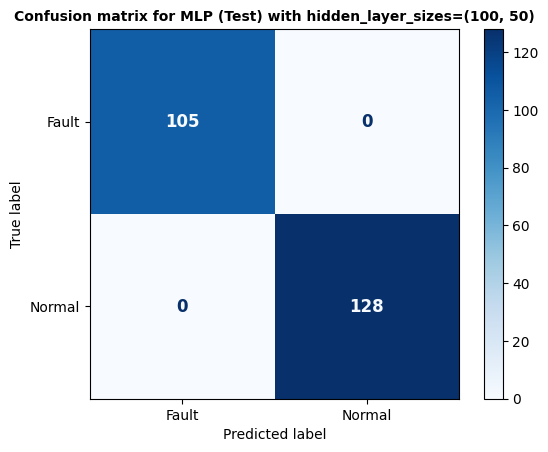

Hidden Layer Sizes: (50, 100)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

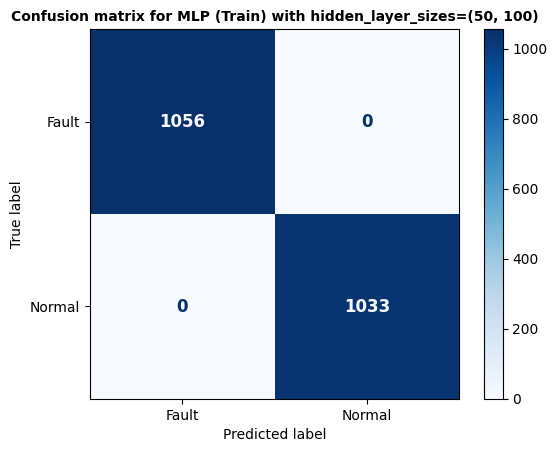

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

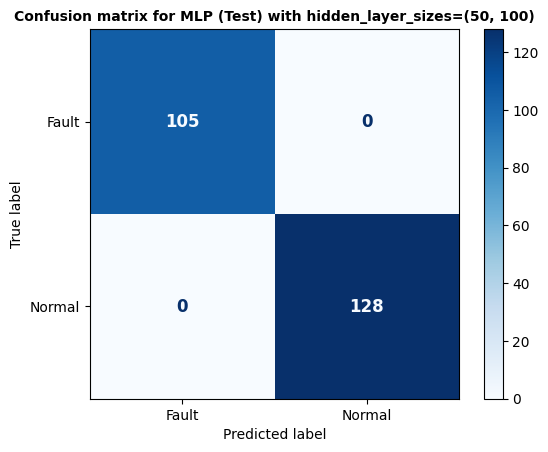

Hidden Layer Sizes: (100, 100)
Train Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1056.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 1033.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 2089.0}}


<Figure size 600x400 with 0 Axes>

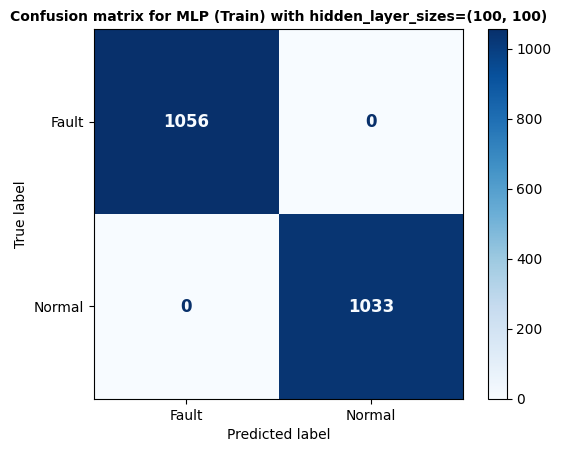

Test Classification Report:
{'Fault': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 105.0}, 'Normal': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 128.0}, 'accuracy': 1.0, 'macro avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}, 'weighted avg': {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 233.0}}


<Figure size 600x400 with 0 Axes>

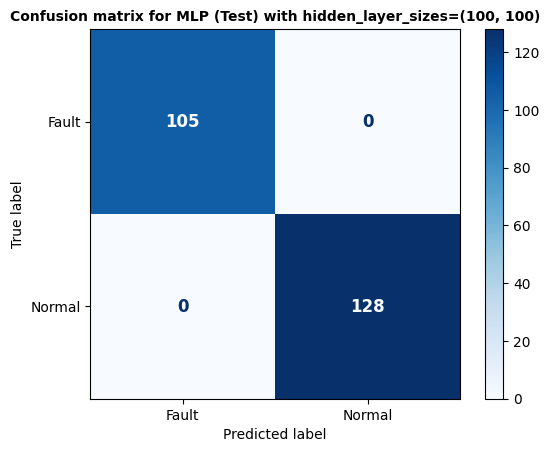

Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/MPL.xlsx
Model 1 (1.00) > Model 2 (1.00) > Model 3 (1.00) > Model 4 (1.00) > Model 5 (1.00) > Model 6 (1.00) > Model 7 (1.00) > Model 8 (1.00) > Model 9 (1.00)
Ranked models saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/ranked_MLP.xlsx
Best Model Results:
Hidden Layer Sizes: (25,)
Train Accuracy: 1.00
Test Accuracy: 1.00
Train Precision: 1.00
Test Precision: 1.00
Train Recall: 1.00
Test Recall: 1.00
Total models trained: 9


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.neural_network import MLPClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize an empty list to store the accuracy scores and other metrics for MLPClassifier
mlp_results = []

# Test different parameters for MLPClassifier
hidden_layer_sizes_list = [(25,), (50,), (100,), (25, 25), (50, 50), (75, 75), (100, 50), (50, 100), (100, 100)]
for hidden_layer_sizes in hidden_layer_sizes_list:
    # Initialize the MLPClassifier with the specified hidden layer sizes
    mlp = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes)
    # Start the timer
    start = time.time()
    # Fit the model to the training data
    mlp.fit(X_train, y_train)
    # Make predictions on the train and test data
    y_train_pred = mlp.predict(X_train)
    y_test_pred = mlp.predict(X_test)
    # Stop the timer
    end = time.time()
    # Compute metrics
    # Compute metrics from classification report
    train_report = classification_report(y_train, y_train_pred, output_dict=True)
    test_report = classification_report(y_test, y_test_pred, output_dict=True)

    # Print confusion matrices and plots
    print(f"Hidden Layer Sizes: {hidden_layer_sizes}")
    print("Train Classification Report:")
    print(train_report)
    plt.figure(figsize=(6, 4))
    disp_train = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_train, y_train_pred), display_labels=np.unique(y_train))
    disp_train.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion matrix for MLP (Train) with hidden_layer_sizes={hidden_layer_sizes}', fontsize=10, fontweight='bold')
    for text in disp_train.text_.ravel():
        text.set_fontsize(12)
        text.set_fontweight('bold')
    plt.show()

    print("Test Classification Report:")
    print(test_report)
    plt.figure(figsize=(6, 4))
    disp_test = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_test_pred), display_labels=np.unique(y_test))
    disp_test.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion matrix for MLP (Test) with hidden_layer_sizes={hidden_layer_sizes}', fontsize=10, fontweight='bold')
    for text in disp_test.text_.ravel():
        text.set_fontsize(12)
        text.set_fontweight('bold')
    plt.show()

    # Add results to the list
    mlp_results.append({
        'Model No': len(mlp_results) + 1,
        'Hidden Layer Sizes': hidden_layer_sizes,
        'Model Fit Time': end - start,
        'Train TP': confusion_matrix(y_train, y_train_pred)[1, 1],
        'Train TN': confusion_matrix(y_train, y_train_pred)[0, 0],
        'Train FP (Type I Error)': confusion_matrix(y_train, y_train_pred)[0, 1],
        'Train FN (Type II Error)': confusion_matrix(y_train, y_train_pred)[1, 0],
        'Train Accuracy': mlp.score(X_train, y_train),
        'Train Precision': train_report['macro avg']['precision'],
        'Train Recall': train_report['macro avg']['recall'],
        'Train F1': train_report['macro avg']['f1-score'],
        'Train Prediction Time': end - start,
        'Test TP': confusion_matrix(y_test, y_test_pred)[1, 1],
        'Test TN': confusion_matrix(y_test, y_test_pred)[0, 0],
        'Test FP (Type I Error)': confusion_matrix(y_test, y_test_pred)[0, 1],
        'Test FN (Type II Error)': confusion_matrix(y_test, y_test_pred)[1, 0],
        'Test Accuracy': mlp.score(X_test, y_test),
        'Test Precision': test_report['macro avg']['precision'],
        'Test Recall': test_report['macro avg']['recall'],
        'Test F1': test_report['macro avg']['f1-score'],
        'Test Prediction Time': end - start
    })

# Create a DataFrame from the results
mlp_results_df = pd.DataFrame(mlp_results)

# Save results to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/MPL.xlsx'
mlp_results_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank models based on test F1, Recall, Precision, and Accuracy
ranked_models = mlp_results_df.sort_values(by=['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy'], ascending=False)

# Print and rank models
ranked_model_str = ' > '.join([f'Model {int(row["Model No"])} ({row["Test F1"]:.2f})' for _, row in ranked_models.iterrows()])
print(ranked_model_str)

# Save ranked models to another Excel file
ranked_model_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/ranked_MLP.xlsx'
ranked_models.to_excel(ranked_model_filename, index=False)
print(f'Ranked models saved to {ranked_model_filename}')

# Find the row with the best test accuracy
best_model_row = mlp_results_df.loc[mlp_results_df['Test Accuracy'].idxmax()]

# Print information about the best model
print("Best Model Results:")
print(f"Hidden Layer Sizes: {best_model_row['Hidden Layer Sizes']}")
print(f"Train Accuracy: {best_model_row['Train Accuracy']:.2f}")
print(f"Test Accuracy: {best_model_row['Test Accuracy']:.2f}")
print(f"Train Precision: {best_model_row['Train Precision']:.2f}")
print(f"Test Precision: {best_model_row['Test Precision']:.2f}")
print(f"Train Recall: {best_model_row['Train Recall']:.2f}")
print(f"Test Recall: {best_model_row['Test Recall']:.2f}")

# Print the total number of models trained
total_models_trained = len(mlp_results_df)
print(f"Total models trained: {total_models_trained}")


# **7. BaggingClassifier**

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize an empty list to store the results
results = []

# Test different kernels for the base estimator
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
for i, kernel in enumerate(kernels):
    # Initialize the base estimator (SVM classifier) with the specified kernel
    base_estimator = SVC(kernel=kernel, C=10000)
    # Initialize the BaggingClassifier with the base estimator
    bagging_classifier = BaggingClassifier(estimator=base_estimator, n_estimators=10)

    # Start the timer for model fit time
    start_fit_time = time.time()

    # Fit the model to the training data
    bagging_classifier.fit(X_train, y_train)

    # End the fit time
    end_fit_time = time.time()
    model_fit_time = end_fit_time - start_fit_time

    # Make predictions on the train and test data
    start_train_pred_time = time.time()
    y_train_pred = bagging_classifier.predict(X_train)
    end_train_pred_time = time.time()
    train_pred_time = end_train_pred_time - start_train_pred_time

    start_test_pred_time = time.time()
    y_test_pred = bagging_classifier.predict(X_test)
    end_test_pred_time = time.time()
    test_pred_time = end_test_pred_time - start_test_pred_time

    # Confusion matrices
    train_confusion = confusion_matrix(y_train, y_train_pred)
    test_confusion = confusion_matrix(y_test, y_test_pred)

    # Extract TP, TN, FP, FN from confusion matrices
    train_TN, train_FP, train_FN, train_TP = train_confusion.ravel()
    test_TN, test_FP, test_FN, test_TP = test_confusion.ravel()

    # Compute classification report
    train_report = classification_report(y_train, y_train_pred, output_dict=True)
    test_report = classification_report(y_test, y_test_pred, output_dict=True)

    # Add results to the list in the required format
    results.append({
        'Model no': i + 1,
        'Kernel': kernel,
        'Model fit time': model_fit_time,
        'Train TP': train_TP,
        'Train TN': train_TN,
        'Train FP (Type I Error)': train_FP,
        'Train FN (Type II Error)': train_FN,
        'Train Accuracy': bagging_classifier.score(X_train, y_train),
        'Train Precision': train_report['macro avg']['precision'],
        'Train Recall': train_report['macro avg']['recall'],
        'Train F1': train_report['macro avg']['f1-score'],
        'Train Prediction time': train_pred_time,
        'Test TP': test_TP,
        'Test TN': test_TN,
        'Test FP (Type I Error)': test_FP,
        'Test FN (Type II Error)': test_FN,
        'Test Accuracy': bagging_classifier.score(X_test, y_test),
        'Test Precision': test_report['macro avg']['precision'],
        'Test Recall': test_report['macro avg']['recall'],
        'Test F1': test_report['macro avg']['f1-score'],
        'Test Prediction time': test_pred_time
    })

# Convert the results list to a DataFrame
results_df = pd.DataFrame(results)

# Save results to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/Bagging_Classifier_Results.xlsx'
results_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank models by test metrics (F1, Recall, Precision, Accuracy, FN, FP)
ranking_columns = ['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy',
                   'Test FN (Type II Error)', 'Test FP (Type I Error)', 'Test TN', 'Test TP']
ranked_results = results_df.sort_values(by=ranking_columns, ascending=[False, False, False, False, True, True, False, False])

# Generate ranking equation
ranking_equation = " > ".join([f"Model {row['Model no']} ({round(row['Test Accuracy'] * 100, 2)}%)"
                               for _, row in ranked_results.iterrows()])
print("Ranking equation based on test results (F1, Recall, Precision, Accuracy):")
print(ranking_equation)

# Save ranked models to Excel
ranked_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/Bagging_Classifier_Ranked_Results.xlsx'
ranked_results.to_excel(ranked_filename, index=False)
print(f'Ranked results saved to {ranked_filename}')


Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/Bagging_Classifier_Results.xlsx
Ranking equation based on test results (F1, Recall, Precision, Accuracy):
Model 1 (100.0%) > Model 2 (100.0%) > Model 3 (100.0%) > Model 4 (96.14%)
Ranked results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/Bagging_Classifier_Ranked_Results.xlsx


# 8. AdaBoostClassifier

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/Adaboost_Results.xlsx
Ranking equation based on test results (F1, Recall, Precision, Accuracy):
Model 1.0 (100.0%)
Ranked results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/Adaboost_Ranked_Results.xlsx
Train Confusion Matrix:


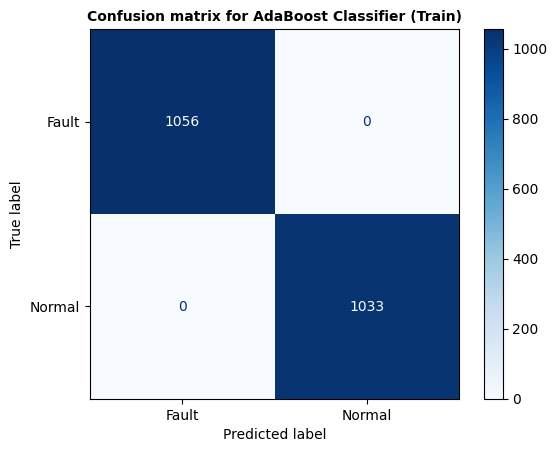

Test Confusion Matrix:


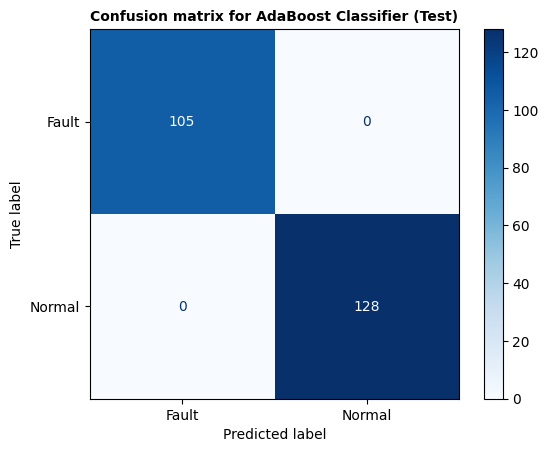

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize an empty list to store the results
results = []

# Initialize the base estimator (SVM classifier)
base_estimator = SVC(kernel='linear', C=10000, probability=True)  # Enable probability estimates

# Initialize the AdaBoostClassifier with the base estimator
adaboost_classifier = AdaBoostClassifier(estimator=base_estimator, n_estimators=50, learning_rate=1.0, algorithm='SAMME.R')


# Start the timer for model fit time
start_fit_time = time.time()

# Fit the model to the training data
adaboost_classifier.fit(X_train, y_train)

# End the timer
end_fit_time = time.time()
model_fit_time = end_fit_time - start_fit_time

# Make predictions on the train and test data
start_train_pred_time = time.time()
y_train_pred = adaboost_classifier.predict(X_train)
end_train_pred_time = time.time()
train_pred_time = end_train_pred_time - start_train_pred_time

start_test_pred_time = time.time()
y_test_pred = adaboost_classifier.predict(X_test)
end_test_pred_time = time.time()
test_pred_time = end_test_pred_time - start_test_pred_time

# Confusion matrices
train_confusion = confusion_matrix(y_train, y_train_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)

# Extract TP, TN, FP, FN from confusion matrices
train_TN, train_FP, train_FN, train_TP = train_confusion.ravel()
test_TN, test_FP, test_FN, test_TP = test_confusion.ravel()

# Compute classification report
train_report = classification_report(y_train, y_train_pred, output_dict=True)
test_report = classification_report(y_test, y_test_pred, output_dict=True)

# Add results to the list
results.append({
    'Model no': 1,
    'Model fit time': model_fit_time,
    'Train TP': train_TP,
    'Train TN': train_TN,
    'Train FP (Type I Error)': train_FP,
    'Train FN (Type II Error)': train_FN,
    'Train Accuracy': adaboost_classifier.score(X_train, y_train),
    'Train Precision': train_report['macro avg']['precision'],
    'Train Recall': train_report['macro avg']['recall'],
    'Train F1': train_report['macro avg']['f1-score'],
    'Train Prediction time': train_pred_time,
    'Test TP': test_TP,
    'Test TN': test_TN,
    'Test FP (Type I Error)': test_FP,
    'Test FN (Type II Error)': test_FN,
    'Test Accuracy': adaboost_classifier.score(X_test, y_test),
    'Test Precision': test_report['macro avg']['precision'],
    'Test Recall': test_report['macro avg']['recall'],
    'Test F1': test_report['macro avg']['f1-score'],
    'Test Prediction time': test_pred_time
})

# Convert the results list to a DataFrame
results_df = pd.DataFrame(results)

# Save results to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/Adaboost_Results.xlsx'
results_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank models by test metrics (F1, Recall, Precision, Accuracy, FN, FP)
ranking_columns = ['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy',
                   'Test FN (Type II Error)', 'Test FP (Type I Error)', 'Test TN', 'Test TP']
ranked_results = results_df.sort_values(by=ranking_columns, ascending=[False, False, False, False, True, True, False, False])

# Generate ranking equation
ranking_equation = " > ".join([f"Model {row['Model no']} ({round(row['Test Accuracy'] * 100, 2)}%)"
                               for _, row in ranked_results.iterrows()])
print("Ranking equation based on test results (F1, Recall, Precision, Accuracy):")
print(ranking_equation)

# Save ranked models to Excel
ranked_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/Adaboost_Ranked_Results.xlsx'
ranked_results.to_excel(ranked_filename, index=False)
print(f'Ranked results saved to {ranked_filename}')

# Visualize confusion matrices
print("Train Confusion Matrix:")
ConfusionMatrixDisplay(confusion_matrix=train_confusion, display_labels=np.unique(y_train)).plot(cmap='Blues', values_format='d')
plt.title('Confusion matrix for AdaBoost Classifier (Train)', fontsize=10, fontweight='bold')
plt.show()

print("Test Confusion Matrix:")
ConfusionMatrixDisplay(confusion_matrix=test_confusion, display_labels=np.unique(y_test)).plot(cmap='Blues', values_format='d')
plt.title('Confusion matrix for AdaBoost Classifier (Test)', fontsize=10, fontweight='bold')
plt.show()


# **9. naive_bayes**

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []
model_no = 1

# List of classifiers (SVM included for comparison)
classifiers = [
    ('Gaussian Naive Bayes', GaussianNB()),
    ('Bernoulli Naive Bayes', BernoulliNB()),
    ('Support Vector Classifier', SVC(kernel='linear', probability=True))
]

for name, clf in classifiers:
    # Start the timer
    fit_start = time.time()

    # Fit the model
    clf.fit(X_train, y_train)

    # Stop the timer after fitting
    fit_end = time.time()

    # Make predictions on train and test data
    train_pred = clf.predict(X_train)
    test_pred = clf.predict(X_test)

    # Calculate prediction time
    pred_start = time.time()
    test_pred = clf.predict(X_test)
    pred_end = time.time()

    # Compute confusion matrices
    train_confusion = confusion_matrix(y_train, train_pred)
    test_confusion = confusion_matrix(y_test, test_pred)

    # Compute classification reports
    train_report = classification_report(y_train, train_pred, output_dict=True)
    test_report = classification_report(y_test, test_pred, output_dict=True)

    # Append metrics to results list
    results.append({
        'Model No': model_no,
        'Classifier': name,
        'Model fit time': fit_end - fit_start,
        'Train TP': train_confusion[1, 1],
        'Train TN': train_confusion[0, 0],
        'Train FP (Type I Error)': train_confusion[0, 1],
        'Train FN (Type II Error)': train_confusion[1, 0],
        'Train Accuracy': train_report['accuracy'],
        'Train Precision': train_report['macro avg']['precision'],
        'Train Recall': train_report['macro avg']['recall'],
        'Train F1': train_report['macro avg']['f1-score'],
        'Train Prediction time': pred_end - pred_start,
        'Test TP': test_confusion[1, 1],
        'Test TN': test_confusion[0, 0],
        'Test FP (Type I Error)': test_confusion[0, 1],
        'Test FN (Type II Error)': test_confusion[1, 0],
        'Test Accuracy': test_report['accuracy'],
        'Test Precision': test_report['macro avg']['precision'],
        'Test Recall': test_report['macro avg']['recall'],
        'Test F1': test_report['macro avg']['f1-score'],
        'Test Prediction time': pred_end - pred_start
    })

    # Increment the model number
    model_no += 1

# Create a DataFrame from results
results_df = pd.DataFrame(results)

# Save the results to Excel
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/naive_bayes_results.xlsx'
results_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Ranking models based on test metrics
ranking_cols = ['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy', 'Test FN (Type II Error)', 'Test FP (Type I Error)', 'Test TN', 'Test TP']
sorted_results = results_df.sort_values(by=ranking_cols, ascending=[False, False, False, False, True, True, False, False])

# Print models ranked by performance
ranked_models = " > ".join([f"Model {int(row['Model No'])} ({row['Test Accuracy']:.2%})" for _, row in sorted_results.iterrows()])
print(f"Ranked Models by Test Results: {ranked_models}")

# Save the ranked models to Excel
ranked_excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/naive_bayes_ranked_models.xlsx'
sorted_results.to_excel(ranked_excel_filename, index=False)
print(f'Ranked models saved to {ranked_excel_filename}')


Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/naive_bayes_results.xlsx
Ranked Models by Test Results: Model 1 (100.00%) > Model 3 (100.00%) > Model 2 (49.79%)
Ranked models saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/ naive_bayes_ranked_models.xlsx


# ***11. BernoulliRBM***

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.neural_network import BernoulliRBM, MLPClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize an empty list to store the results
rbm_results = []

# Test different parameters for BernoulliRBM
n_components_list = [25, 50, 100]
learning_rate_list = [0.01, 0.1, 0.5]
batch_size_list = [5, 10]

for n_components in n_components_list:
    for learning_rate in learning_rate_list:
        for batch_size in batch_size_list:
            # Initialize the BernoulliRBM with the specified parameters
            rbm = BernoulliRBM(n_components=n_components, learning_rate=learning_rate, batch_size=batch_size, n_iter=10, verbose=0)

            # Start the timer
            start = time.time()

            # Fit the model to the training data
            rbm.fit(X_train)

            # Transform the training and test data
            X_train_transformed = rbm.transform(X_train)
            X_test_transformed = rbm.transform(X_test)

            # Stop the timer
            end = time.time()

            # Initialize an MLPClassifier on top of the RBM features
            mlp = MLPClassifier(hidden_layer_sizes=(25,), max_iter=100)

            # Start the timer for MLP training
            mlp_start = time.time()

            # Fit the MLPClassifier on RBM-transformed data
            mlp.fit(X_train_transformed, y_train)

            # Make predictions on the test data
            y_test_pred = mlp.predict(X_test_transformed)

            # Stop the timer for MLP training
            mlp_end = time.time()

            # Compute metrics for train and test sets
            train_confusion = confusion_matrix(y_train, mlp.predict(X_train_transformed))
            test_confusion = confusion_matrix(y_test, y_test_pred)

            # Calculate recall, precision, and F1 score for train and test
            train_report = classification_report(y_train, mlp.predict(X_train_transformed), output_dict=True)
            test_report = classification_report(y_test, y_test_pred, output_dict=True)

            # Add results to the list
            rbm_results.append({
                'n_components': n_components,
                'learning_rate': learning_rate,
                'batch_size': batch_size,
                'train_confusion': train_confusion,
                'test_confusion': test_confusion,
                'accuracy_train': mlp.score(X_train_transformed, y_train),
                'accuracy_test': mlp.score(X_test_transformed, y_test),
                'recall_train': train_report['macro avg']['recall'],
                'precision_train': train_report['macro avg']['precision'],
                'f1score_train': train_report['macro avg']['f1-score'],
                'recall_test': test_report['macro avg']['recall'],
                'precision_test': test_report['macro avg']['precision'],
                'f1score_test': test_report['macro avg']['f1-score'],
                'time_rbm': end - start,
                'time_mlp': mlp_end - mlp_start
            })

# Convert the results list to a DataFrame
rbm_results_df = pd.DataFrame(rbm_results)

# Save results in the specified format in Excel
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/BernoulliRBM.xlsx'
rbm_results_df['Model'] = rbm_results_df.apply(
    lambda row: f"Model non_components={row['n_components']}, learning_rate={row['learning_rate']}, batch_size={row['batch_size']}", axis=1
)
rbm_results_df[['Model', 'time_rbm', 'train_confusion', 'accuracy_train', 'precision_train', 'recall_train', 'f1score_train',
                'test_confusion', 'accuracy_test', 'precision_test', 'recall_test', 'f1score_test']].to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Find the row with the best test accuracy
best_model_row = rbm_results_df.loc[rbm_results_df['accuracy_test'].idxmax()]

# Print the best model
print("\nBest Model Results:")
print(f"Best Parameters: n_components={best_model_row['n_components']}, learning_rate={best_model_row['learning_rate']}, batch_size={best_model_row['batch_size']}")
print(f"Train Accuracy: {best_model_row['accuracy_train']}")
print(f"Test Accuracy: {best_model_row['accuracy_test']}")
print(f"Train Recall: {best_model_row['recall_train']}")
print(f"Test Recall: {best_model_row['recall_test']}")
print(f"Train Precision: {best_model_row['precision_train']}")
print(f"Test Precision: {best_model_row['precision_test']}")
print(f"Train F1 Score: {best_model_row['f1score_train']}")
print(f"Test F1 Score: {best_model_row['f1score_test']}")

# Rank models by test metrics
# Rank models by test metrics (excluding 'test_confusion' for sorting)
ranking_columns = ['f1score_test', 'recall_test', 'precision_test', 'accuracy_test']
ranked_results = rbm_results_df.sort_values(by=ranking_columns, ascending=[False, False, False, False])

# Process 'test_confusion' separately as needed

# Generate ranking equation
ranking_equation = " > ".join([f"Model {i + 1} ({round(row['accuracy_test'] * 100, 2)}%)"
                               for i, row in ranked_results.iterrows()])
print("\nRanking equation based on test results (F1, Recall, Precision, Accuracy):")
print(ranking_equation)

# Save ranked results to Excel
ranked_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/BernoulliRBM_ranked_results.xlsx'
ranked_results.to_excel(ranked_filename, index=False)
print(f'Ranked results saved to {ranked_filename}')


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptro

Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/BernoulliRBM.xlsx

Best Model Results:
Best Parameters: n_components=25, learning_rate=0.01, batch_size=5
Train Accuracy: 1.0
Test Accuracy: 1.0
Train Recall: 1.0
Test Recall: 1.0
Train Precision: 1.0
Test Precision: 1.0
Train F1 Score: 1.0
Test F1 Score: 1.0

Ranking equation based on test results (F1, Recall, Precision, Accuracy):
Model 1 (100.0%) > Model 2 (100.0%) > Model 3 (100.0%) > Model 4 (100.0%) > Model 5 (100.0%) > Model 6 (100.0%) > Model 7 (100.0%) > Model 8 (100.0%) > Model 9 (100.0%) > Model 10 (100.0%) > Model 11 (100.0%) > Model 12 (100.0%) > Model 13 (100.0%) > Model 14 (100.0%) > Model 15 (100.0%) > Model 16 (100.0%) > Model 18 (100.0%) > Model 17 (99.57%)
Ranked results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/BernoulliRBM_ranked_results.xlsx


# **12. RadiusNeighborsClassifier**

<Figure size 600x400 with 0 Axes>

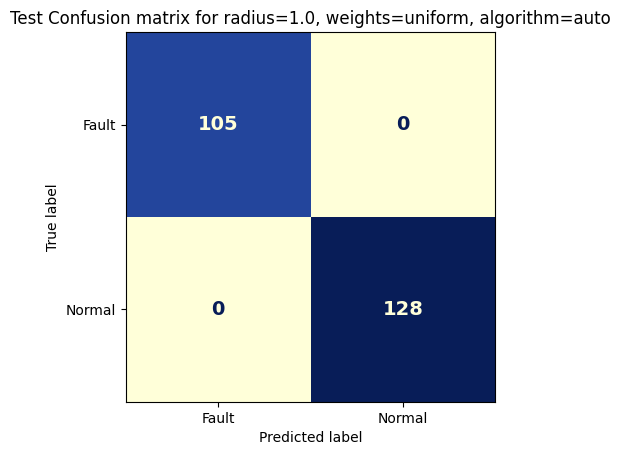

<Figure size 600x400 with 0 Axes>

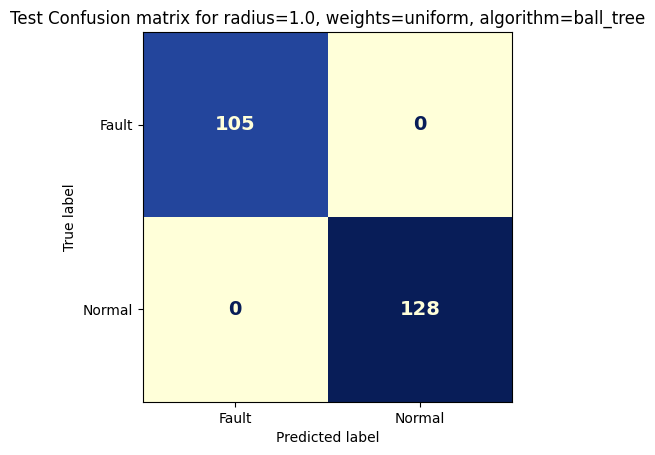

<Figure size 600x400 with 0 Axes>

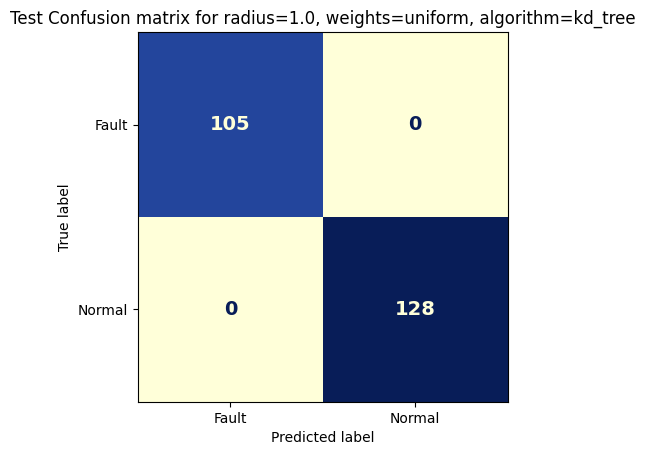

<Figure size 600x400 with 0 Axes>

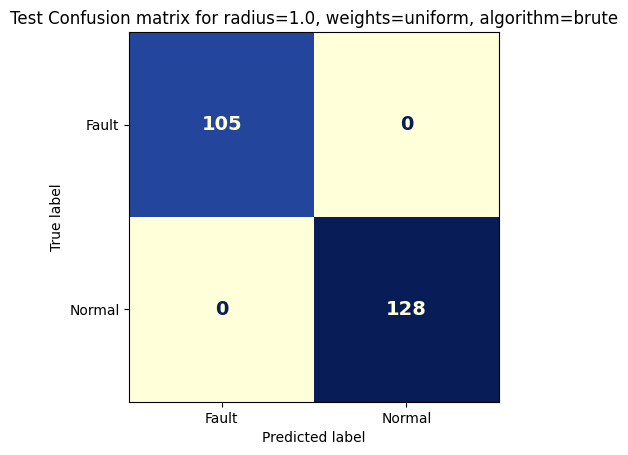

<Figure size 600x400 with 0 Axes>

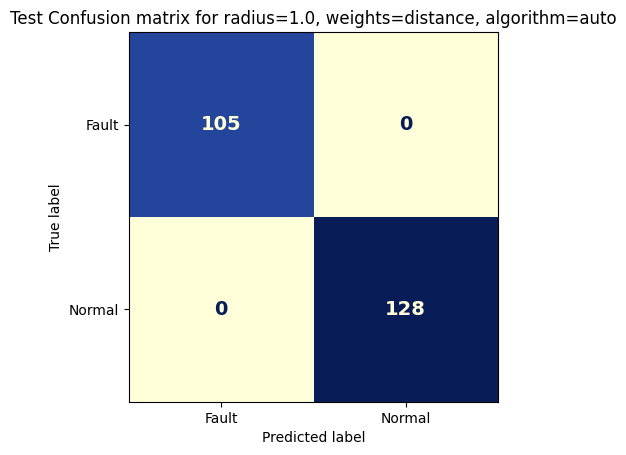

<Figure size 600x400 with 0 Axes>

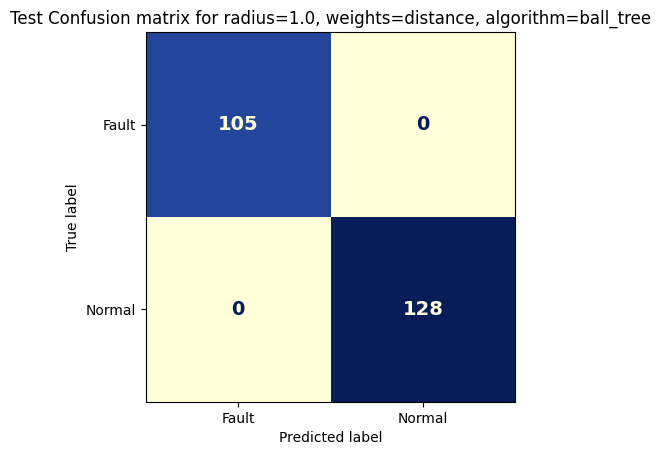

<Figure size 600x400 with 0 Axes>

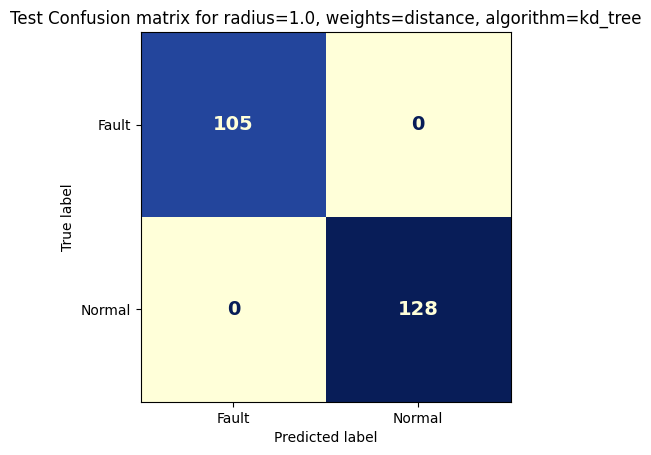

<Figure size 600x400 with 0 Axes>

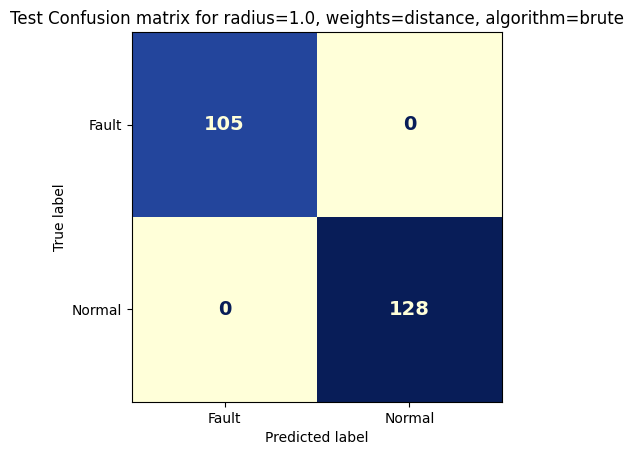

<Figure size 600x400 with 0 Axes>

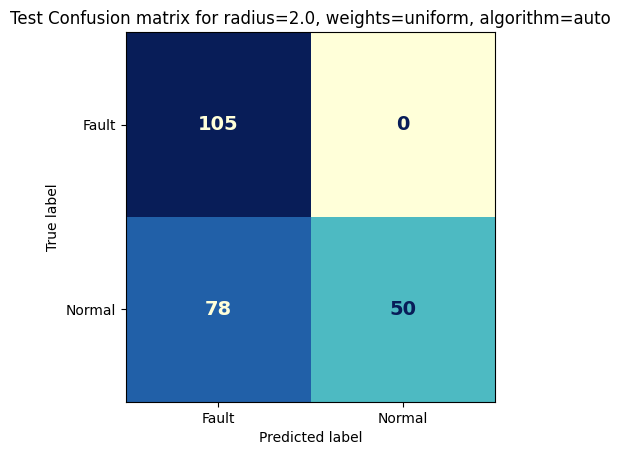

<Figure size 600x400 with 0 Axes>

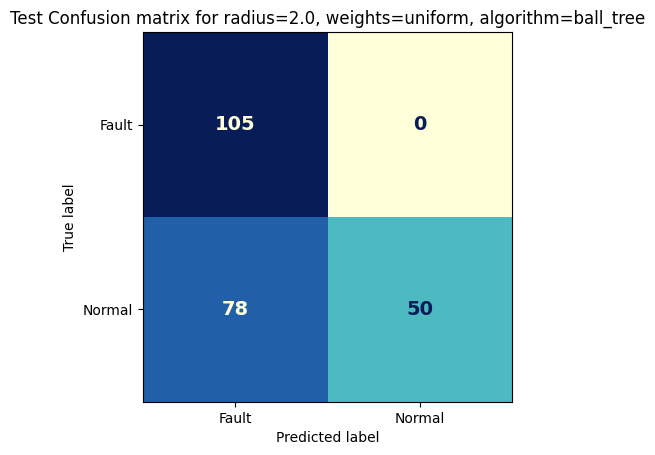

<Figure size 600x400 with 0 Axes>

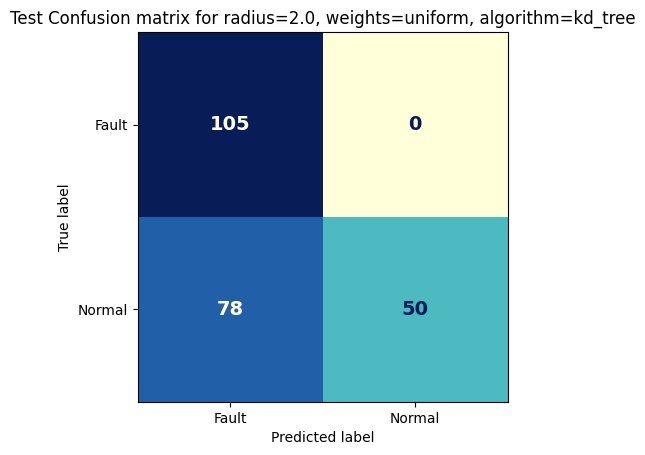

<Figure size 600x400 with 0 Axes>

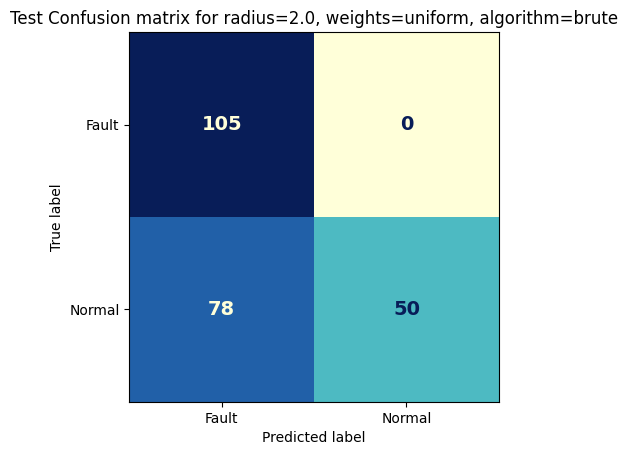

<Figure size 600x400 with 0 Axes>

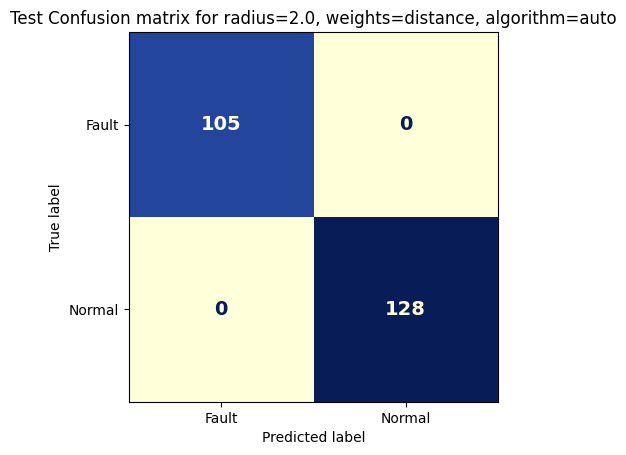

<Figure size 600x400 with 0 Axes>

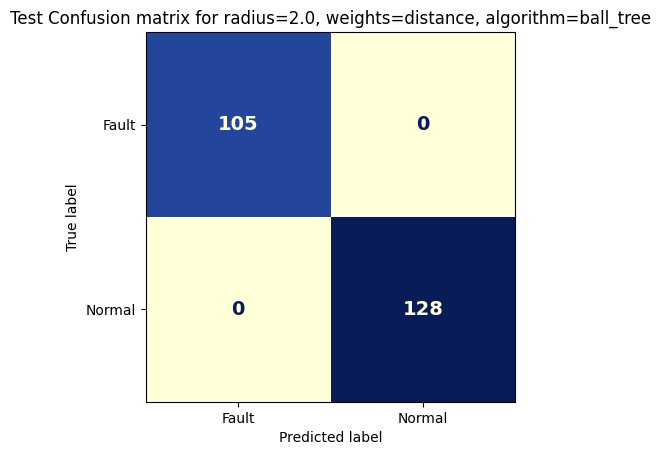

<Figure size 600x400 with 0 Axes>

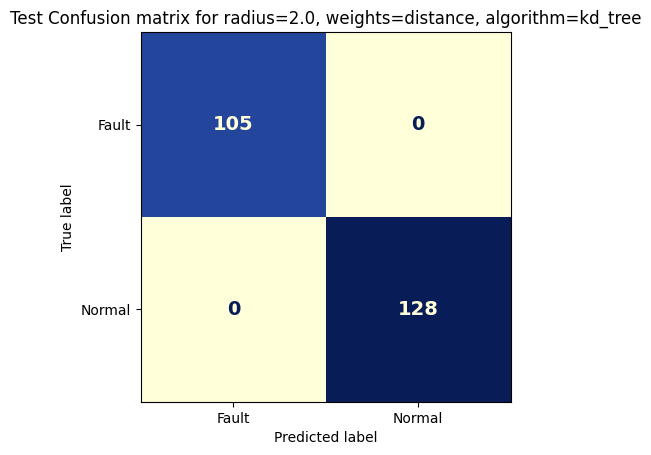

<Figure size 600x400 with 0 Axes>

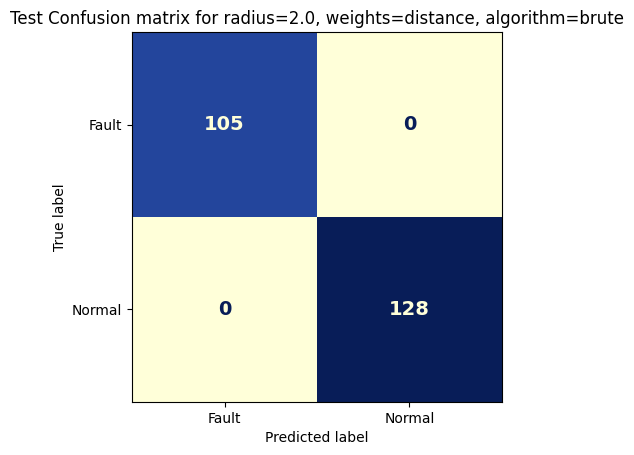

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

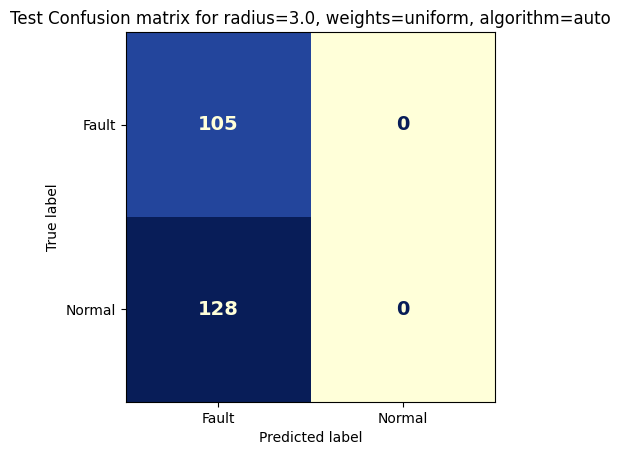

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

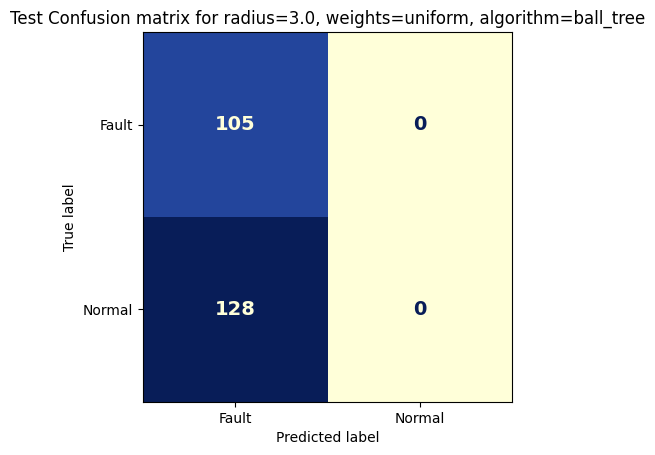

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

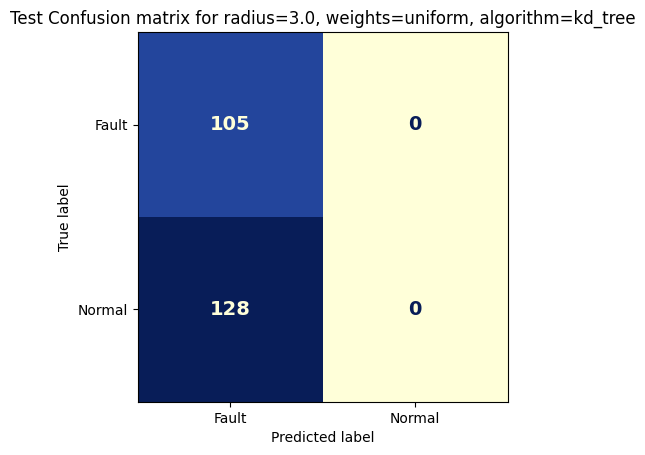

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

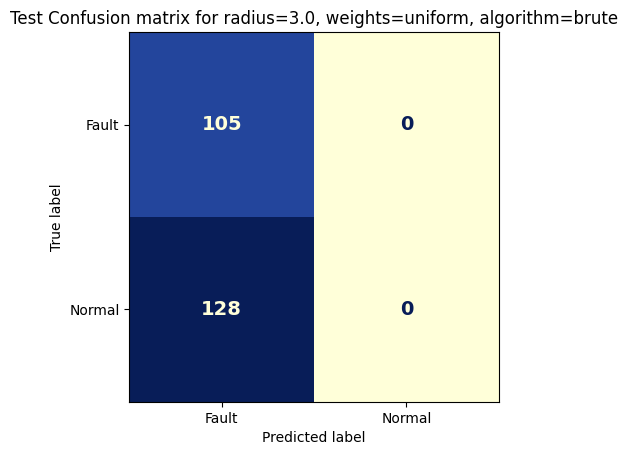

<Figure size 600x400 with 0 Axes>

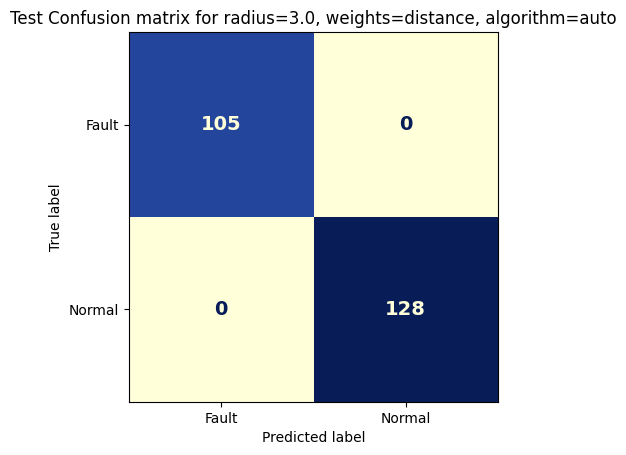

<Figure size 600x400 with 0 Axes>

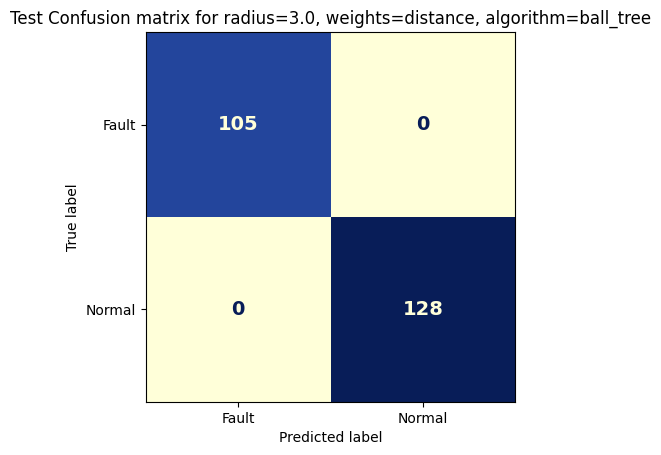

<Figure size 600x400 with 0 Axes>

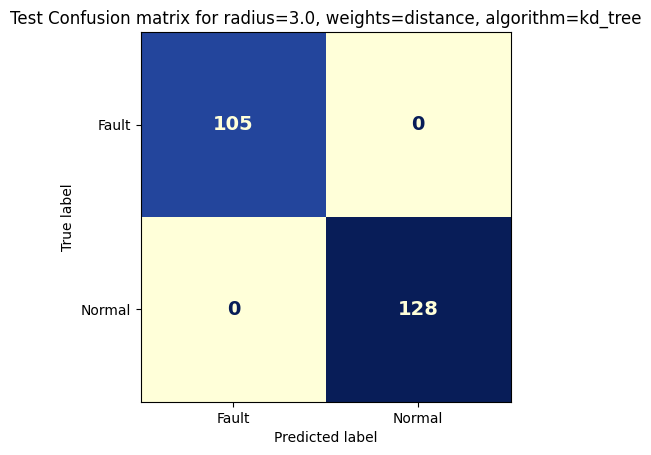

<Figure size 600x400 with 0 Axes>

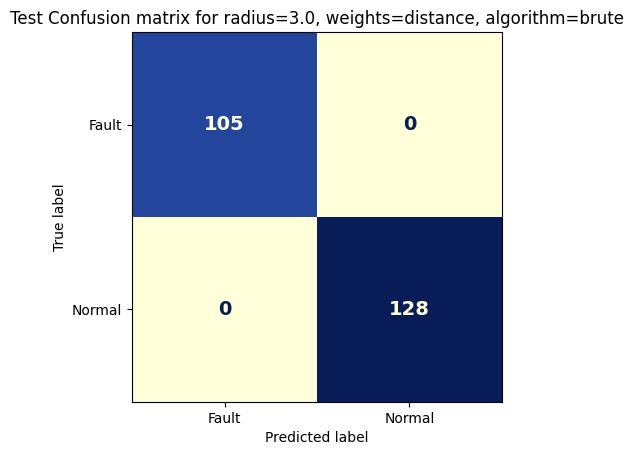

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

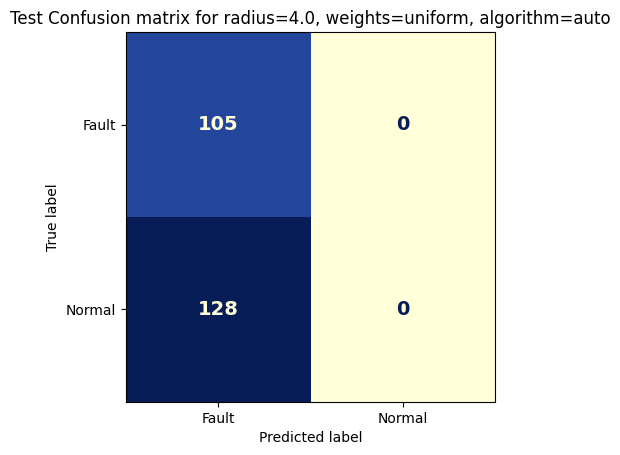

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

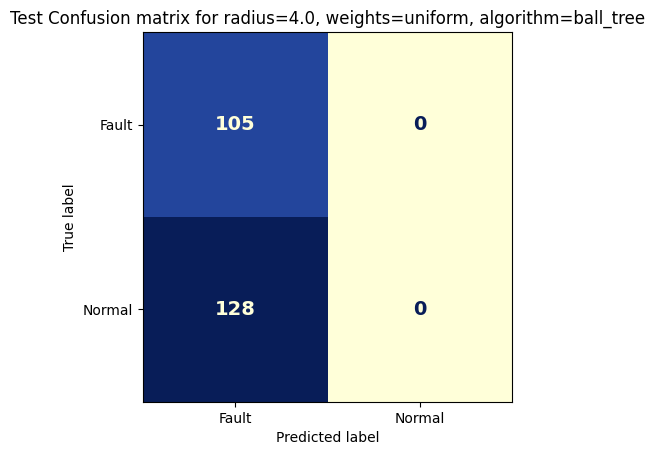

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

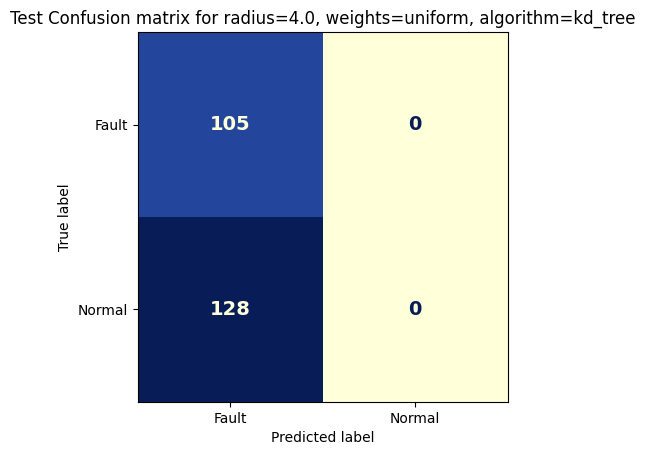

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

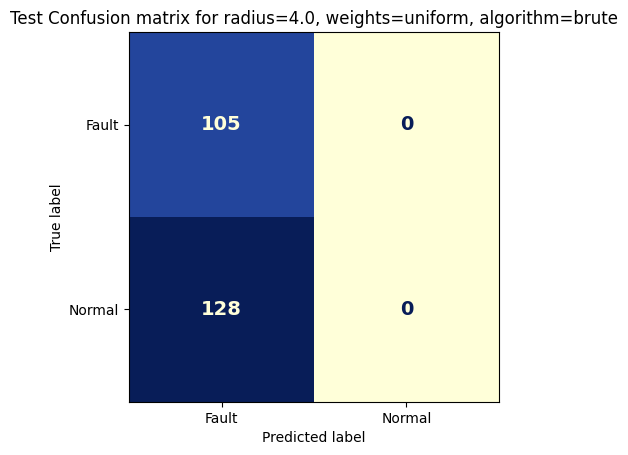

<Figure size 600x400 with 0 Axes>

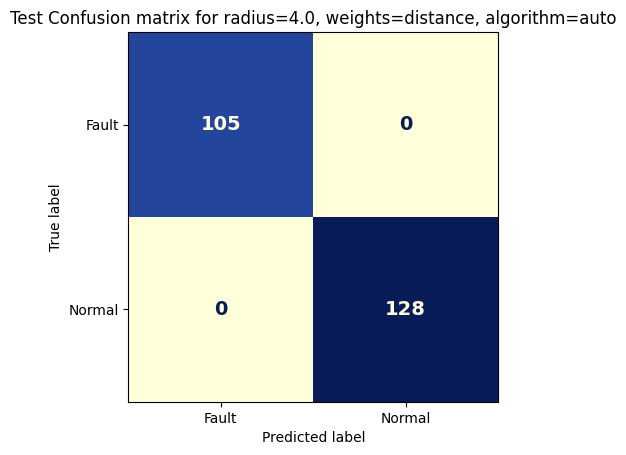

<Figure size 600x400 with 0 Axes>

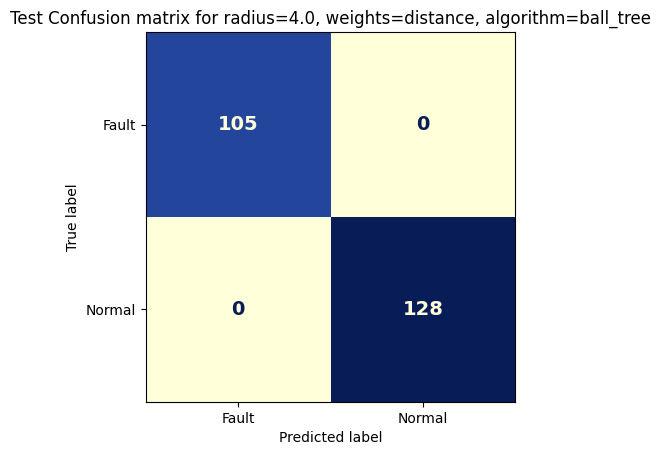

<Figure size 600x400 with 0 Axes>

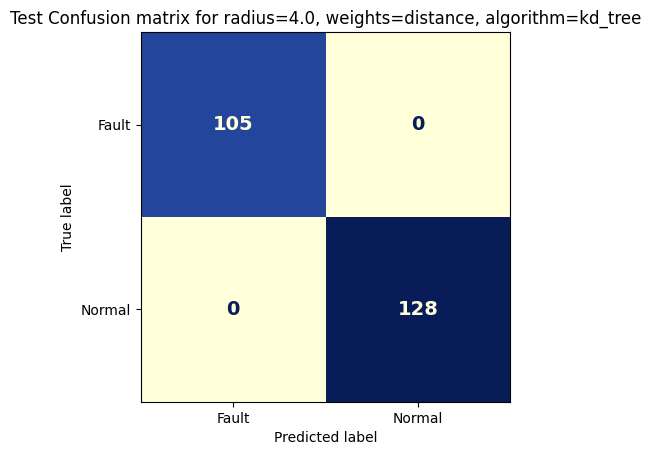

<Figure size 600x400 with 0 Axes>

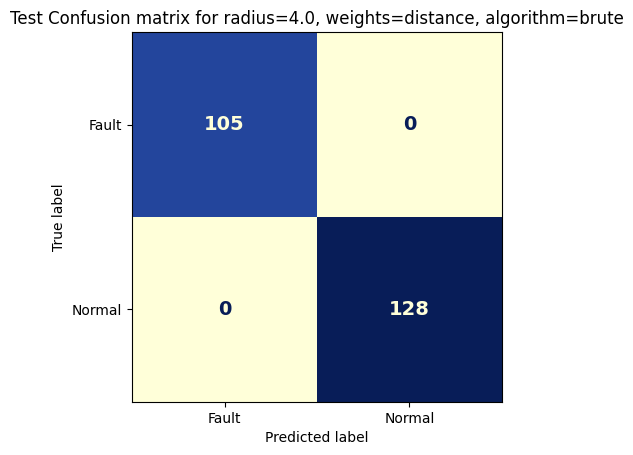

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

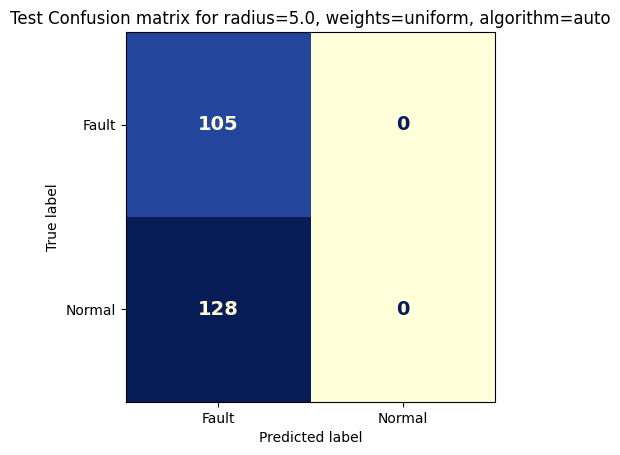

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

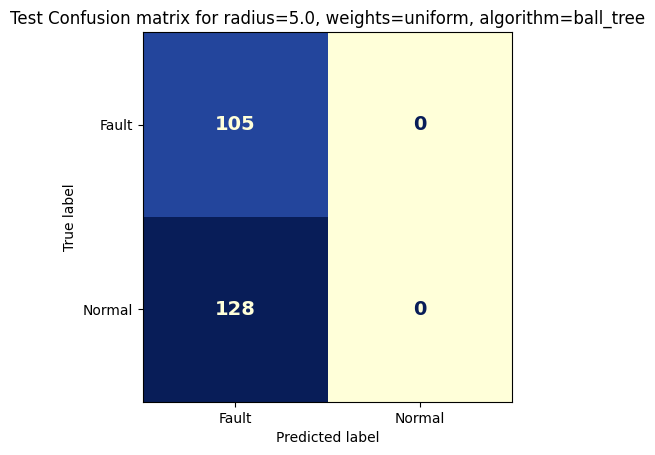

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

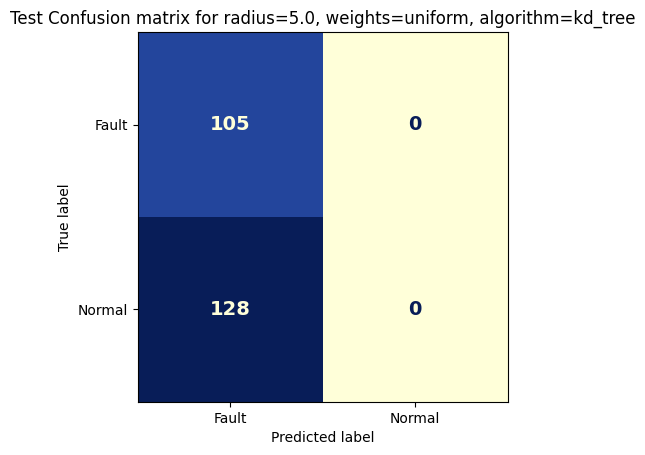

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/m

<Figure size 600x400 with 0 Axes>

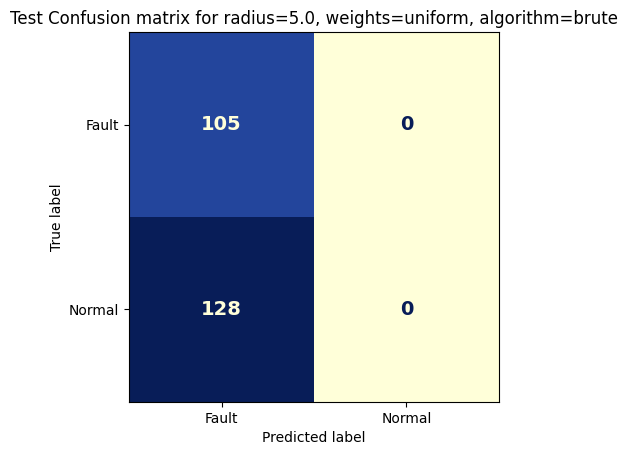

<Figure size 600x400 with 0 Axes>

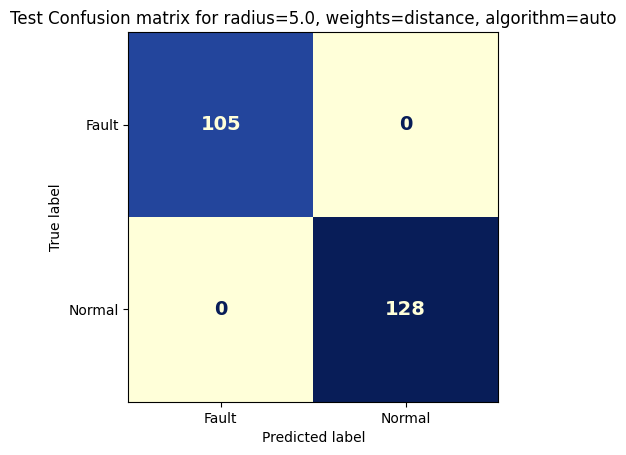

<Figure size 600x400 with 0 Axes>

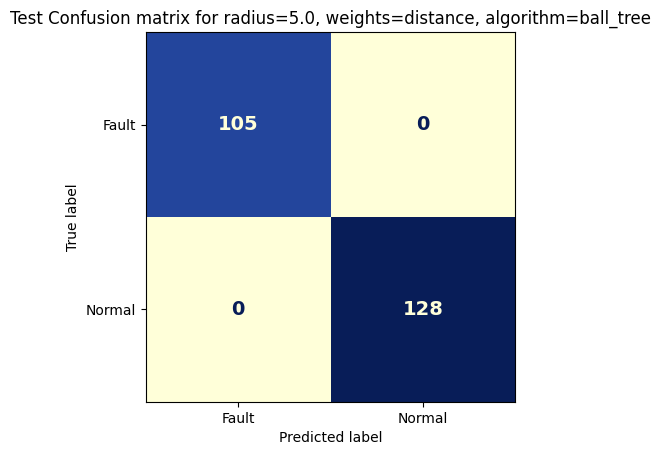

<Figure size 600x400 with 0 Axes>

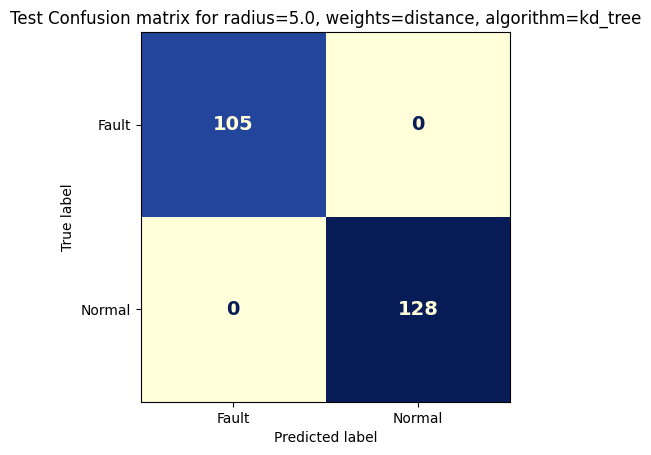

<Figure size 600x400 with 0 Axes>

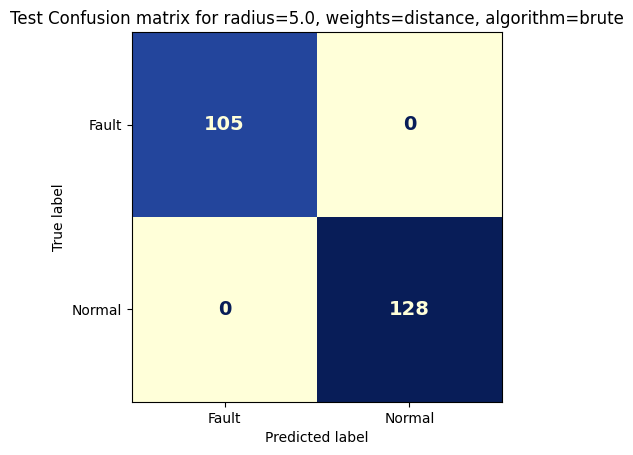

    Model No  Radius   Weights  Algorithm  Model fit time  Train TP  Train TN  \
0          1     1.0   uniform       auto        0.260222      1033      1056   
1          2     1.0   uniform  ball_tree        0.309150      1033      1056   
2          3     1.0   uniform    kd_tree        0.420035      1033      1056   
3          4     1.0   uniform      brute        0.374517      1033      1056   
4          5     1.0  distance       auto        0.508010      1033      1056   
5          6     1.0  distance  ball_tree        0.432946      1033      1056   
6          7     1.0  distance    kd_tree        0.329933      1033      1056   
7          8     1.0  distance      brute        0.220797      1033      1056   
8          9     2.0   uniform       auto        0.322793       430      1056   
9         10     2.0   uniform  ball_tree        0.212915       430      1056   
10        11     2.0   uniform    kd_tree        0.218104       430      1056   
11        12     2.0   unifo

AttributeError: 'Pandas' object has no attribute 'Model_No'

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.neighbors import RadiusNeighborsClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different values of radius, weights, and algorithms
model_number = 1
for radius in [1.0, 2.0, 3.0, 4.0, 5.0]:
    for weights in ['uniform', 'distance']:
        for algorithm in ['auto', 'ball_tree', 'kd_tree', 'brute']:
            # Initialize the RadiusNeighborsClassifier
            rnc = RadiusNeighborsClassifier(radius=radius, weights=weights, algorithm=algorithm)

            # Start the timer
            start = time.time()

            # Fit the model to the training data
            rnc.fit(X_train, y_train)

            # Make predictions on the training data
            y_train_pred = rnc.predict(X_train)
            # Make predictions on the test data
            y_test_pred = rnc.predict(X_test)

            # Stop the timer
            end = time.time()

            # Compute the confusion matrix for train and test sets
            confusion_train = confusion_matrix(y_train, y_train_pred)
            confusion_test = confusion_matrix(y_test, y_test_pred)

            # Extract individual values for train and test confusion matrices
            tn_train, fp_train, fn_train, tp_train = confusion_train.ravel()
            tn_test, fp_test, fn_test, tp_test = confusion_test.ravel()

            # Calculate classification metrics for train and test sets
            train_report = classification_report(y_train, y_train_pred, output_dict=True)
            test_report = classification_report(y_test, y_test_pred, output_dict=True)

            # Append metrics to the results list
            results.append({
                'Model No': model_number,
                'Radius': radius,
                'Weights': weights,
                'Algorithm': algorithm,
                'Model fit time': end - start,
                'Train TP': tp_train,
                'Train TN': tn_train,
                'Train FP (Type I Error)': fp_train,
                'Train FN (Type II Error)': fn_train,
                'Train Accuracy': train_report['accuracy'],
                'Train Precision': train_report['macro avg']['precision'],
                'Train Recall': train_report['macro avg']['recall'],
                'Train F1': train_report['macro avg']['f1-score'],
                'Test TP': tp_test,
                'Test TN': tn_test,
                'Test FP (Type I Error)': fp_test,
                'Test FN (Type II Error)': fn_test,
                'Test Accuracy': test_report['accuracy'],
                'Test Precision': test_report['macro avg']['precision'],
                'Test Recall': test_report['macro avg']['recall'],
                'Test F1': test_report['macro avg']['f1-score'],
                'Test Prediction time': end - start
            })

            # Increment model number
            model_number += 1

            # Draw confusion matrix for test data
            plt.figure(figsize=(6, 4))
            disp_test = ConfusionMatrixDisplay(confusion_matrix=confusion_test, display_labels=np.unique(y_test))
            disp_test.plot(cmap='YlGnBu', values_format='d', colorbar=False)
            plt.title(f'Test Confusion matrix for radius={radius}, weights={weights}, algorithm={algorithm}')
            for text in disp_test.text_.ravel():
                text.set_fontsize(14)
                text.set_fontweight('bold')
            plt.show()

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save the DataFrame to an Excel file
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/radius_neighbors_classifier_results.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank the models by Test F1, Recall, Precision, and Accuracy
ranked_models = comparison_df.sort_values(by=['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy'], ascending=False)

# Save the ranking of models in equation form
ranked_models_list = []
for i, row in enumerate(ranked_models.itertuples(), 1):
    ranked_models_list.append(f"Model {row.Model_No} ({row.Test_F1:.2f})")

# Save the ranked models as a string
ranking_equation = " > ".join(ranked_models_list)
print(f"Ranking: {ranking_equation}")

# Save the ranking to the Excel file
with pd.ExcelWriter(excel_filename, mode='a', engine='openpyxl') as writer:
    pd.DataFrame([{'Ranking': ranking_equation}]).to_excel(writer, sheet_name='Ranking', index=False)

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")

# Find the row with the best test accuracy
best_model_row = comparison_df.loc[comparison_df['Test Accuracy'].idxmax()]

# Print the information about the best model
print("\nBest Model Results:")
print(f"Model No: {best_model_row['Model No']}")
print(f"Radius: {best_model_row['Radius']}")
print(f"Weights: {best_model_row['Weights']}")
print(f"Algorithm: {best_model_row['Algorithm']}")
print(f"Train Accuracy: {best_model_row['Train Accuracy']}")
print(f"Test Accuracy: {best_model_row['Test Accuracy']}")
print(f"Train Precision: {best_model_row['Train Precision']}")
print(f"Test Precision: {best_model_row['Test Precision']}")
print(f"Train Recall: {best_model_row['Train Recall']}")
print(f"Test Recall: {best_model_row['Test Recall']}")
print(f"Train F1 Score: {best_model_row['Train F1']}")
print(f"Test F1 Score: {best_model_row['Test F1']}")


# **13. NearestCentroid**

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.neighbors import NearestCentroid
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize an empty list to store the results
results = []

# Test different values of metric and shrink_threshold
for metric in ['euclidean', 'manhattan']:
    for shrink_threshold in [None, 0.1, 0.5]:
        # Initialize the NearestCentroid classifier
        nc = NearestCentroid(metric=metric, shrink_threshold=shrink_threshold)

        # Start the timer
        start = time.time()

        # Fit the model to the training data
        nc.fit(X_train, y_train)

        # Stop the timer for model fit time
        fit_time = time.time() - start

        # Make predictions on the training and test data
        y_train_pred = nc.predict(X_train)
        y_test_pred = nc.predict(X_test)

        # Stop the timer for prediction
        pred_time = time.time() - start

        # Compute the confusion matrix for train and test sets
        train_confusion = confusion_matrix(y_train, y_train_pred)
        test_confusion = confusion_matrix(y_test, y_test_pred)

        # Extract TP, TN, FP, FN from the confusion matrices for train and test
        train_TN, train_FP, train_FN, train_TP = train_confusion.ravel()
        test_TN, test_FP, test_FN, test_TP = test_confusion.ravel()

        # Calculate classification metrics for train and test sets
        train_report = classification_report(y_train, y_train_pred, output_dict=True)
        test_report = classification_report(y_test, y_test_pred, output_dict=True)

        # Append metrics to the results list
        results.append({
            'Model No': f'Metric={metric}, Shrink Threshold={shrink_threshold}',
            'Train TP': train_TP,
            'Train TN': train_TN,
            'Train FP (Type I Error)': train_FP,
            'Train FN (Type II Error)': train_FN,
            'Train Accuracy': train_report['accuracy'],
            'Train Precision': train_report['macro avg']['precision'],
            'Train Recall': train_report['macro avg']['recall'],
            'Train F1': train_report['macro avg']['f1-score'],
            'Train Prediction Time': pred_time,
            'Test TP': test_TP,
            'Test TN': test_TN,
            'Test FP (Type I Error)': test_FP,
            'Test FN (Type II Error)': test_FN,
            'Test Accuracy': test_report['accuracy'],
            'Test Precision': test_report['macro avg']['precision'],
            'Test Recall': test_report['macro avg']['recall'],
            'Test F1': test_report['macro avg']['f1-score'],
            'Test Prediction Time': pred_time,
            'Model Fit Time': fit_time
        })

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Save the DataFrame to an Excel file in the specified format
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/NearestCentroid_landmine.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Ranking the models based on F1 score, recall, precision, accuracy, FN, FP, TN, and TP in descending order
ranking_columns = ['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy', 'Test FN (Type II Error)', 'Test FP (Type I Error)', 'Test TN', 'Test TP']
ranked_results = comparison_df.sort_values(by=ranking_columns, ascending=[False, False, False, False, True, True, False, False])

# Generate the ranking equation in model > format
ranking_equation = " > ".join([f"Model {i + 1} ({round(row['Test Accuracy'] * 100, 2)}%)"
                               for i, row in ranked_results.iterrows()])

print("\nRanking equation based on test results (F1, Recall, Precision, Accuracy, FN, FP, TN, TP):")
print(ranking_equation)

# Save ranked results and ranking equation to another Excel file
ranked_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/NearestCentroid_ranked_results.xlsx'
ranked_results.to_excel(ranked_filename, index=False)
print(f'Ranked results saved to {ranked_filename}')


Results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/NearestCentroid_landmine.xlsx

Ranking equation based on test results (F1, Recall, Precision, Accuracy, FN, FP, TN, TP):
Model 1 (100.0%) > Model 2 (100.0%) > Model 3 (100.0%) > Model 4 (100.0%) > Model 5 (100.0%) > Model 6 (100.0%)
Ranked results saved to /content/drive/MyDrive/crwu-qauntum/Results_classical/NearestCentroid_ranked_results.xlsx


# **14. NuSVC**

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from sklearn.svm import NuSVC
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different kernels and gammas for NuSVC
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
gammas = ['scale', 'auto', 0.001, 0.01, 0.1, 1.0]

for kernel in kernels:
    for gamma in gammas:
        # Initialize the NuSVC classifier with the specified kernel and gamma
        svc = NuSVC(kernel=kernel, gamma=gamma)

        # Start the timer
        start = time.time()

        # Fit the model to the training data
        svc.fit(X_train, y_train)

        # Make predictions on the test data
        y_pred = svc.predict(X_test)

        # Calculate and print train metrics
        y_pred_train = svc.predict(X_train)

        # Draw the confusion matrix for train data
        conf_matrix_train = confusion_matrix(y_train, y_pred_train)
        # Draw the confusion matrix for test data
        conf_matrix_test = confusion_matrix(y_test, y_pred)

        # Stop the timer
        end = time.time()

        # Append metrics to the results list
        results.append({
            'Kernel': kernel,
            'Gamma': gamma,
            'Model fit time': end - start,
            'Train TP': conf_matrix_train[1, 1],
            'Train TN': conf_matrix_train[0, 0],
            'Train FP (Type I Error)': conf_matrix_train[0, 1],
            'Train FN (Type II Error)': conf_matrix_train[1, 0],
            'Train Accuracy': svc.score(X_train, y_train),
            'Train Precision': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['precision'],
            'Train Recall': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['recall'],
            'Train F1': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['f1-score'],
            'Train Prediction time': end - start,
            'Test TP': conf_matrix_test[1, 1],
            'Test TN': conf_matrix_test[0, 0],
            'Test FP (Type I Error)': conf_matrix_test[0, 1],
            'Test FN (Type II Error)': conf_matrix_test[1, 0],
            'Test Accuracy': svc.score(X_test, y_test),
            'Test Precision': classification_report(y_test, y_pred, output_dict=True)['macro avg']['precision'],
            'Test Recall': classification_report(y_test, y_pred, output_dict=True)['macro avg']['recall'],
            'Test F1': classification_report(y_test, y_pred, output_dict=True)['macro avg']['f1-score'],
            'Test Prediction time': end - start
        })

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save results to Excel
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/NuSVC.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank the models based on Test F1, Recall, Precision, and Accuracy
ranking_columns = ['Test F1', 'Test Recall', 'Test Precision', 'Test Accuracy']
ranked_models = comparison_df.sort_values(by=ranking_columns, ascending=False)

# Save ranking in equation form
ranked_models_list = []
for i, row in enumerate(ranked_models.itertuples(), 1):
    ranked_models_list.append(f"Model {i} ({row.Test_F1:.2f})")

# Save the ranked models as a string
ranking_equation = " > ".join(ranked_models_list)
print(f"Ranking: {ranking_equation}")

# Save the ranking to the Excel file
with pd.ExcelWriter(excel_filename, mode='a', engine='openpyxl') as writer:
    pd.DataFrame([{'Ranking': ranking_equation}]).to_excel(writer, sheet_name='Ranking', index=False)

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")

# Find the row with the best test accuracy
best_model_row = comparison_df.loc[comparison_df['Test Accuracy'].idxmax()]

# Print information about the best model
print("Best Model Results:")
print(f"Kernel: {best_model_row['Kernel']}")
print(f"Gamma: {best_model_row['Gamma']}")
print(f"Train Accuracy: {best_model_row['Train Accuracy']}")
print(f"Test Accuracy: {best_model_row['Test Accuracy']}")
print(f"Train Precision: {best_model_row['Train Precision']}")
print(f"Test Precision: {best_model_row['Test Precision']}")
print(f"Train Recall: {best_model_row['Train Recall']}")
print(f"Test Recall: {best_model_row['Test Recall']}")


     Kernel  Gamma  Model fit time  Train TP  Train TN  \
0    linear  scale        0.211868      1033      1056   
1    linear   auto        0.196071      1033      1056   
2    linear  0.001        0.196898      1033      1056   
3    linear   0.01        0.360217      1033      1056   
4    linear    0.1        0.338954      1033      1056   
5    linear    1.0        0.331914      1033      1056   
6      poly  scale        0.387450      1023      1056   
7      poly   auto        0.391840      1023      1056   
8      poly  0.001        0.171243      1023      1056   
9      poly   0.01        0.222590      1023      1056   
10     poly    0.1        0.211846      1023      1056   
11     poly    1.0        0.223758      1023      1056   
12      rbf  scale        0.305845      1033      1056   
13      rbf   auto        0.302738      1033      1056   
14      rbf  0.001        0.324038      1033      1056   
15      rbf   0.01        0.306432      1033      1056   
16      rbf   

AttributeError: 'Pandas' object has no attribute 'Test_F1'

# 15. LGBMClassifier

/usr/local/lib/python3.10/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001039 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

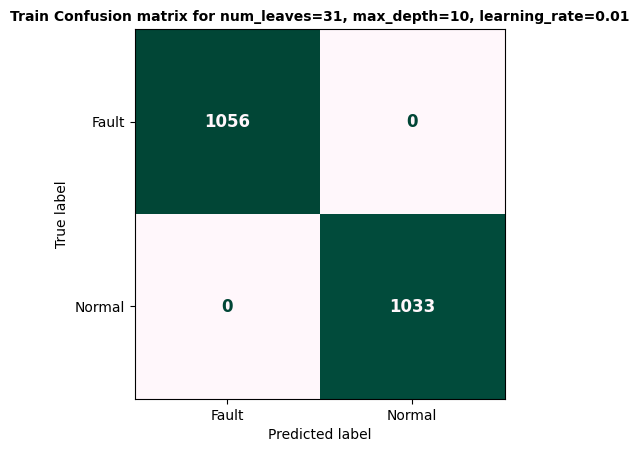

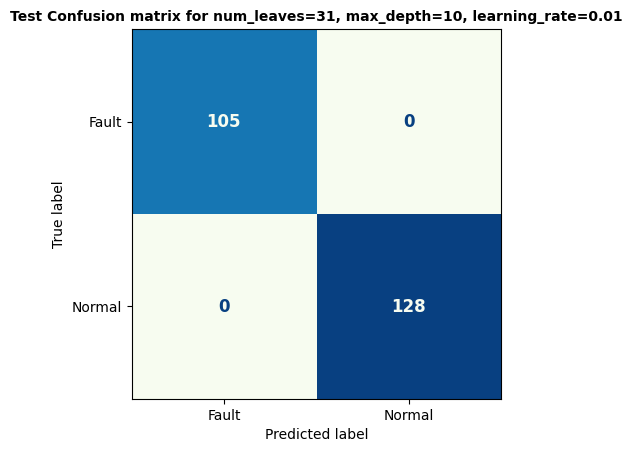

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000535 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

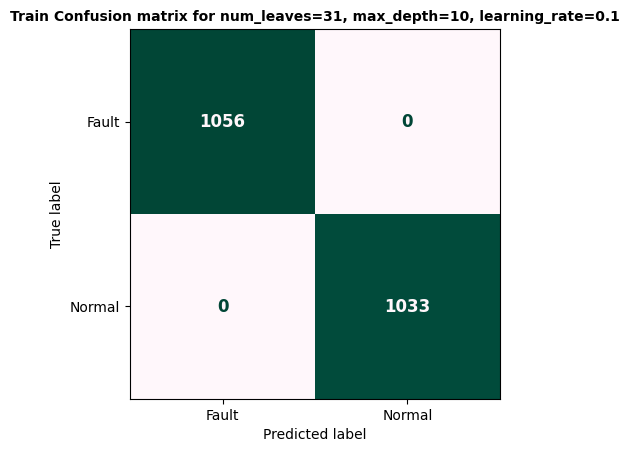

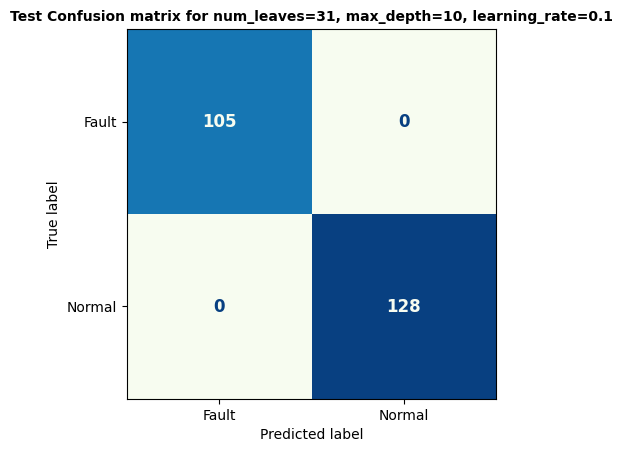

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000555 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

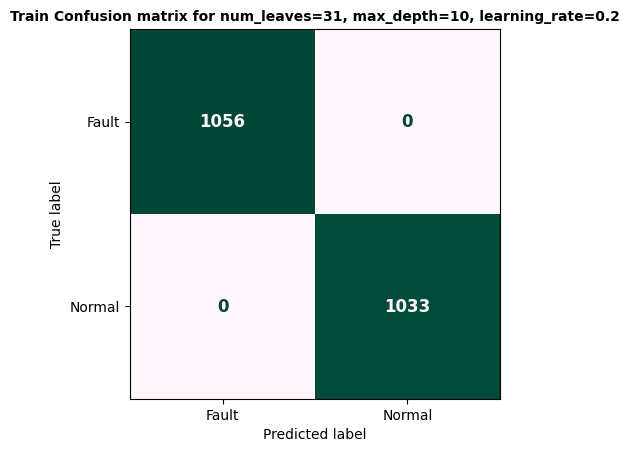

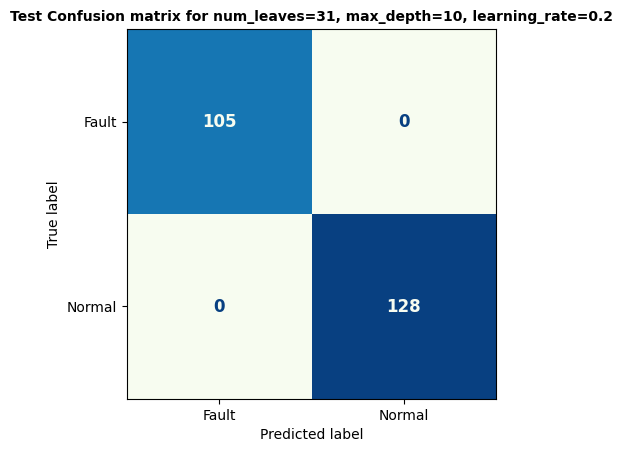

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000534 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

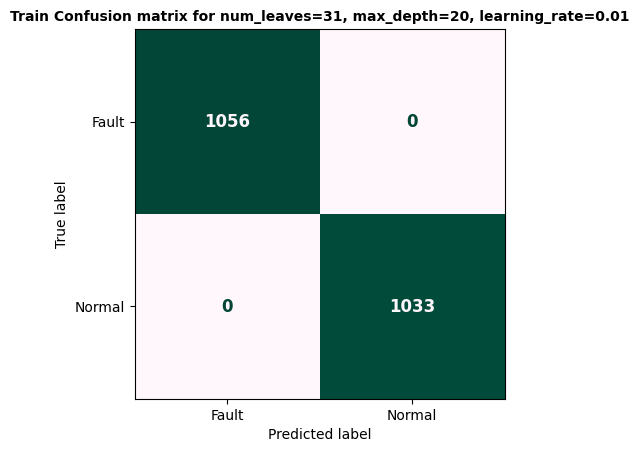

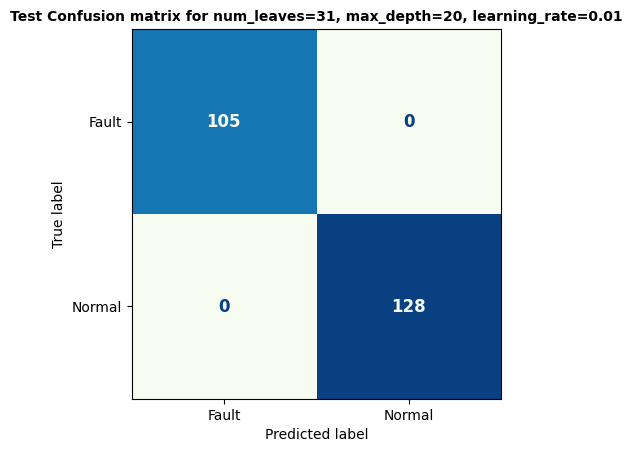

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000543 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

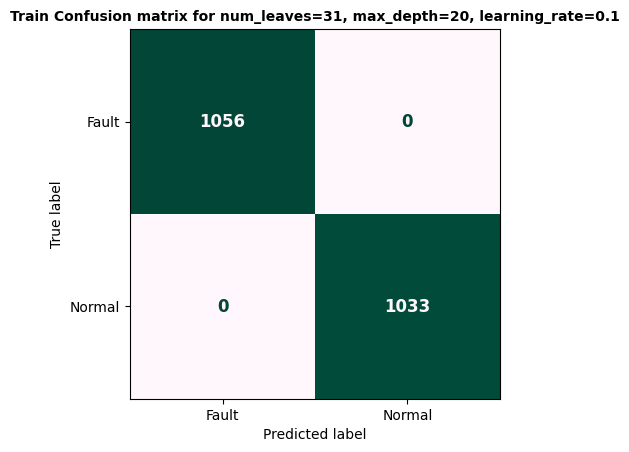

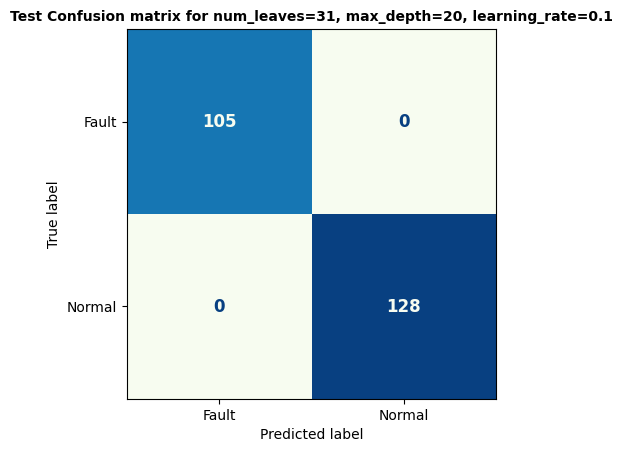

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000513 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

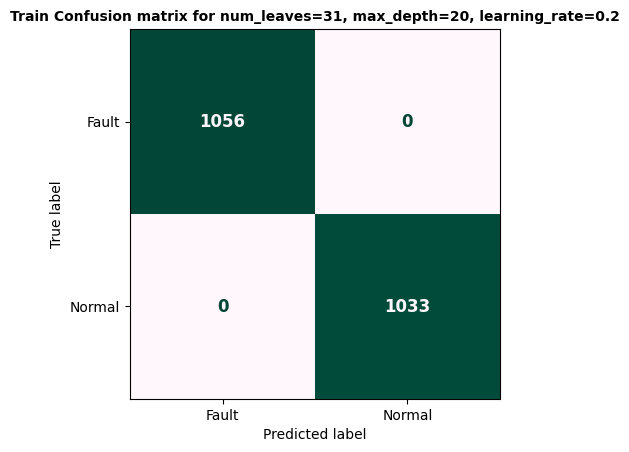

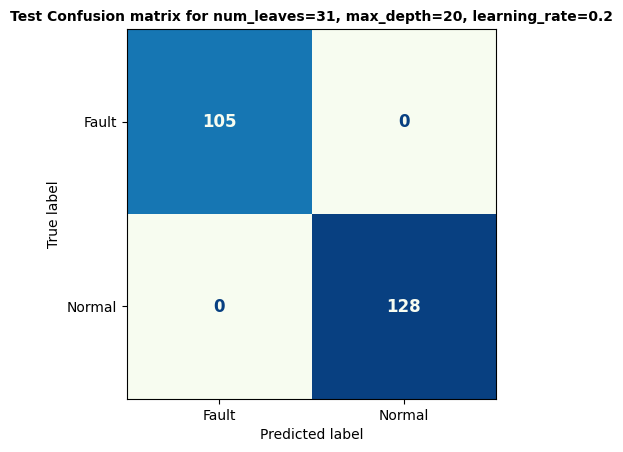

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000572 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

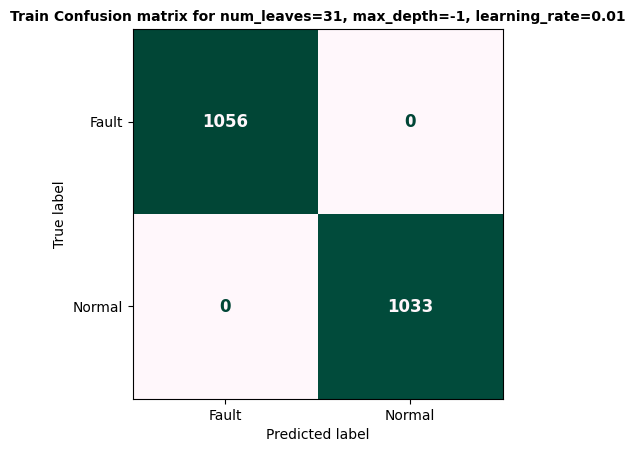

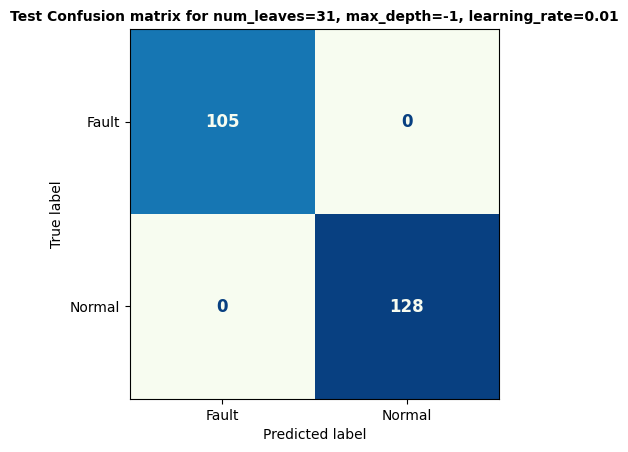

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000517 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

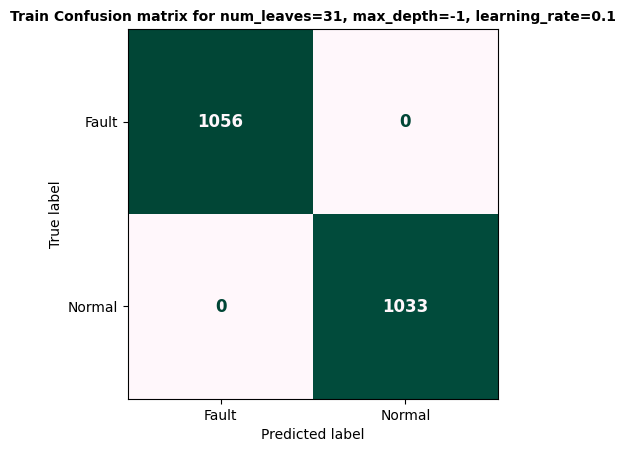

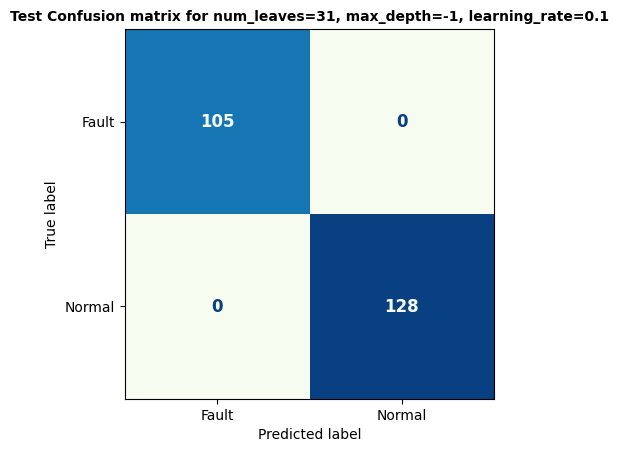

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000701 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

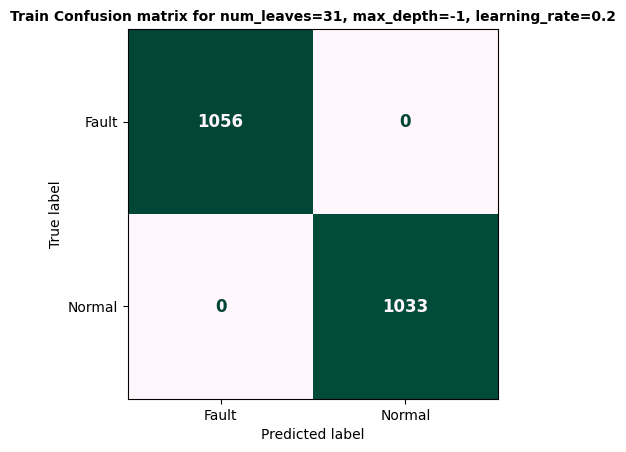

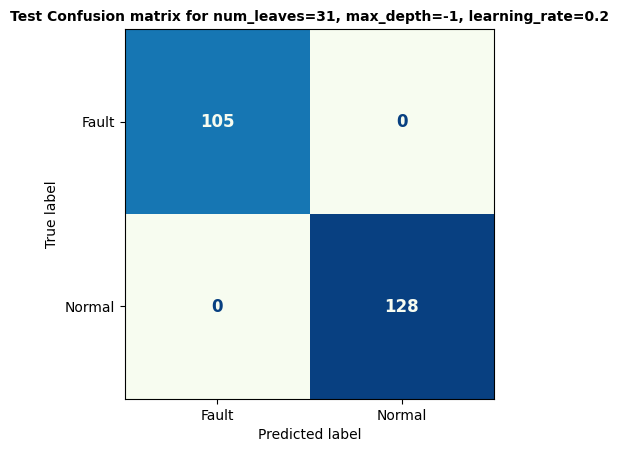

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000566 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

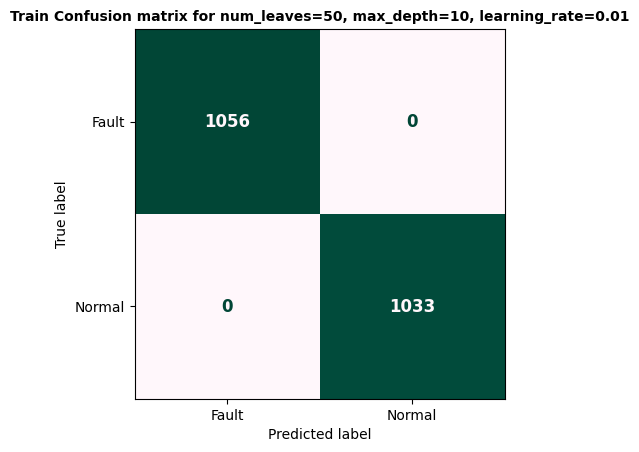

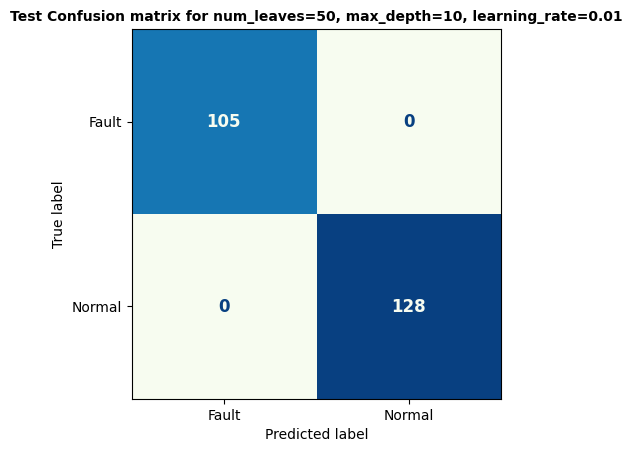

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000520 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

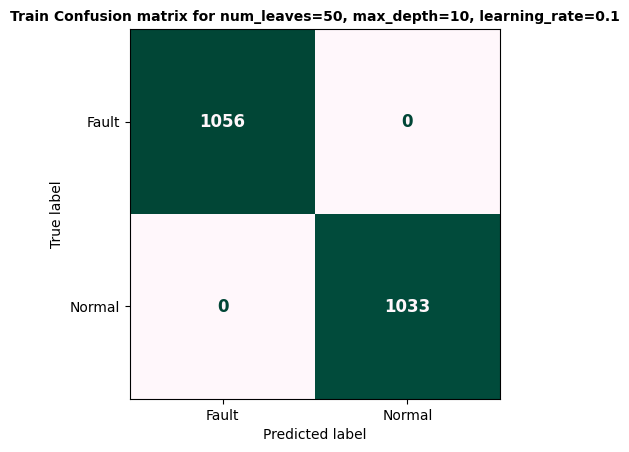

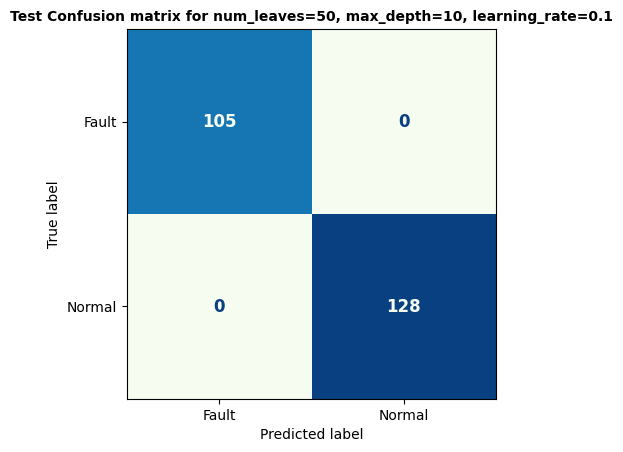

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000508 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

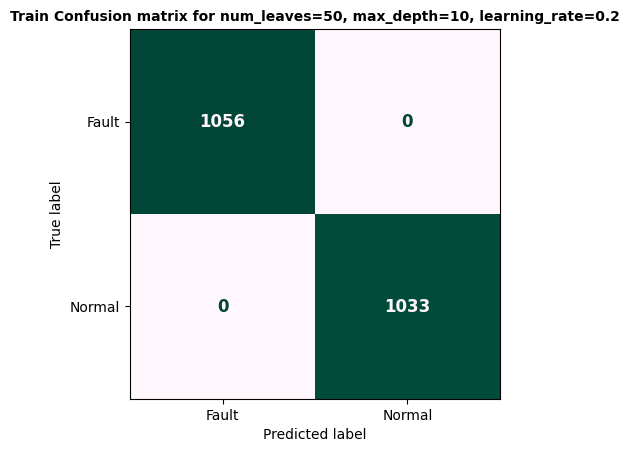

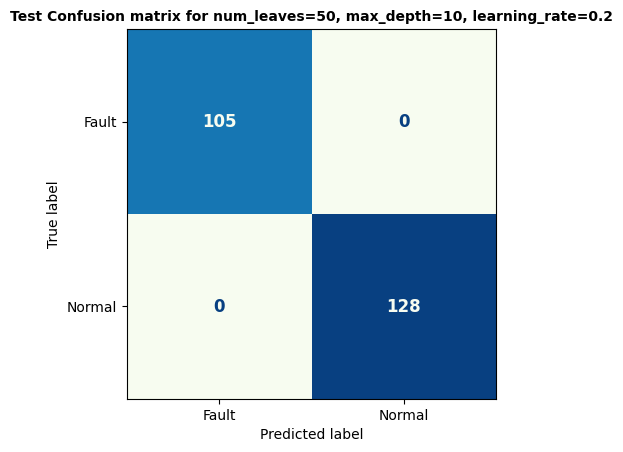

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000533 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

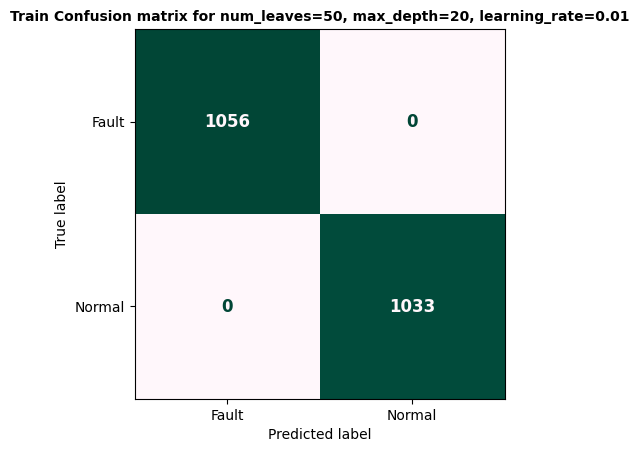

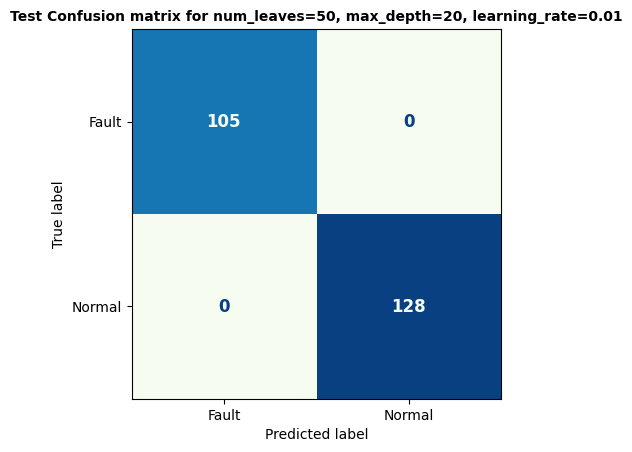

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000540 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

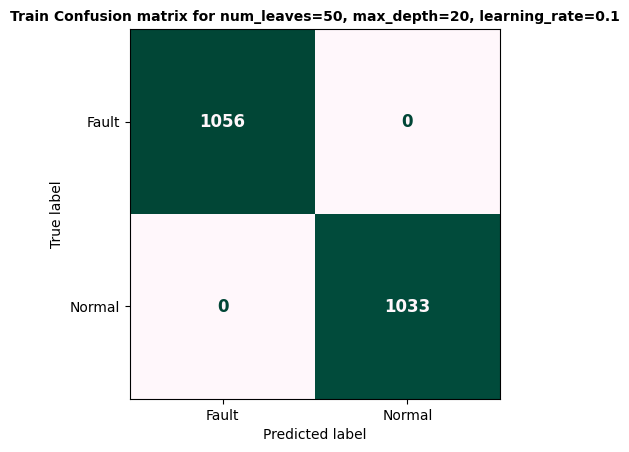

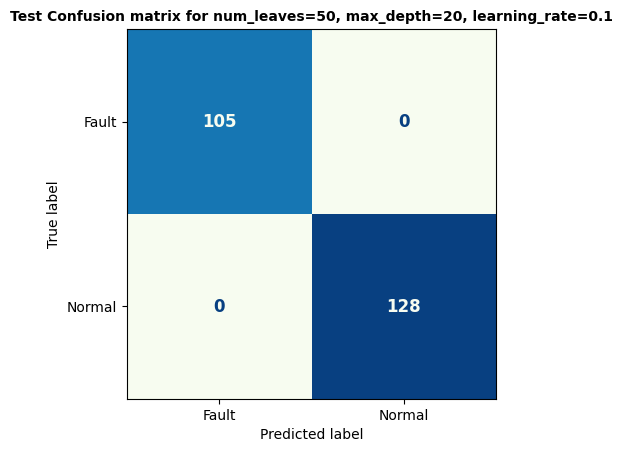

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000490 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

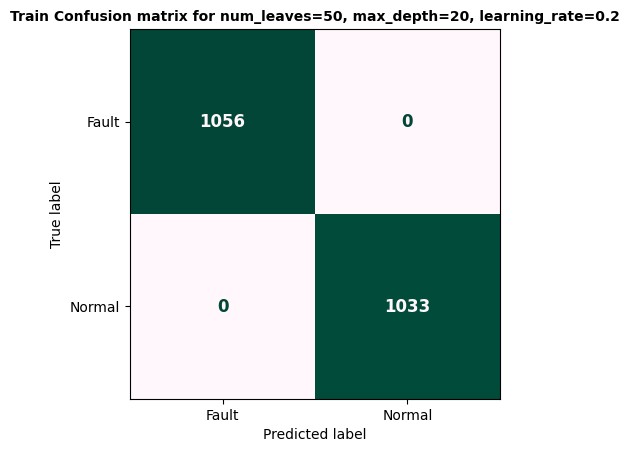

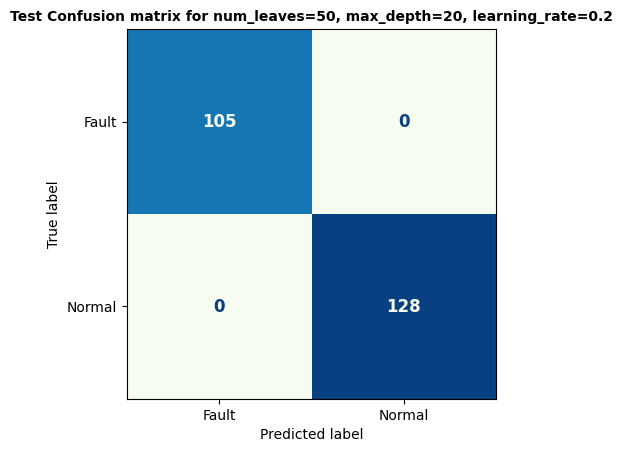

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000517 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

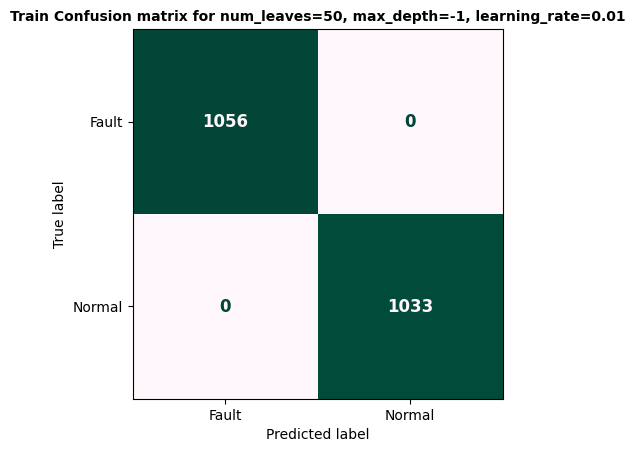

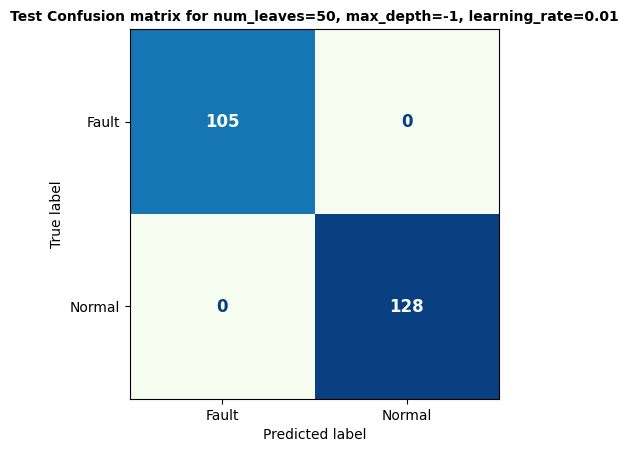

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000522 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

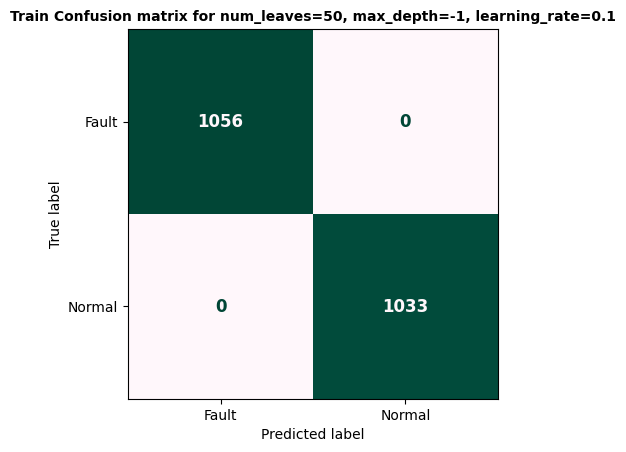

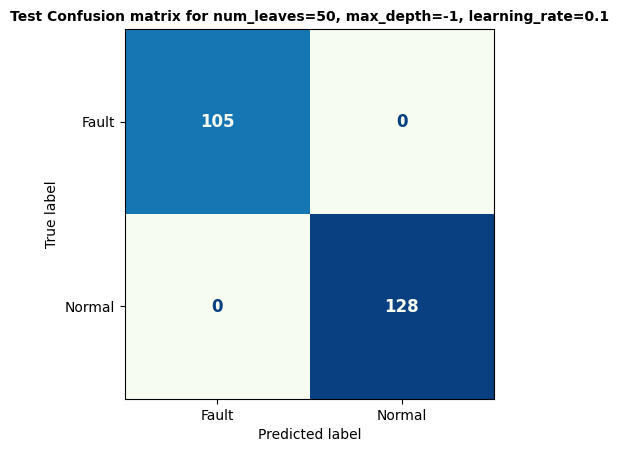

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000491 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

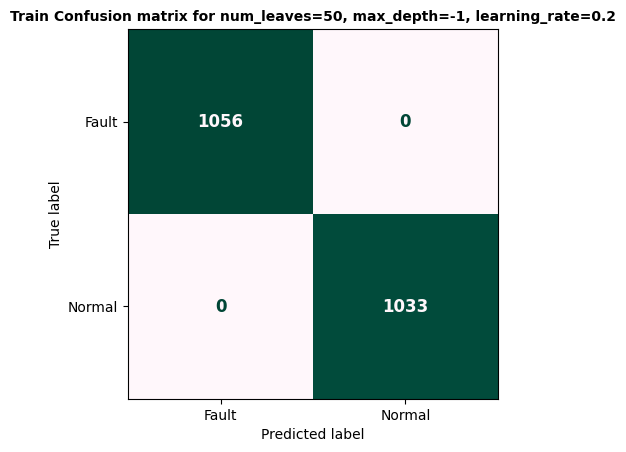

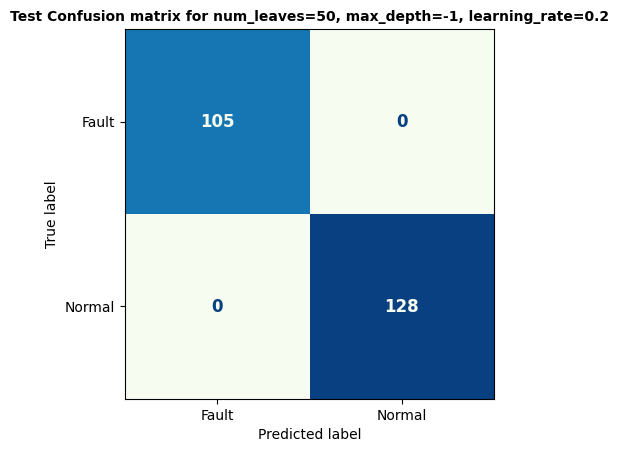

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000495 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

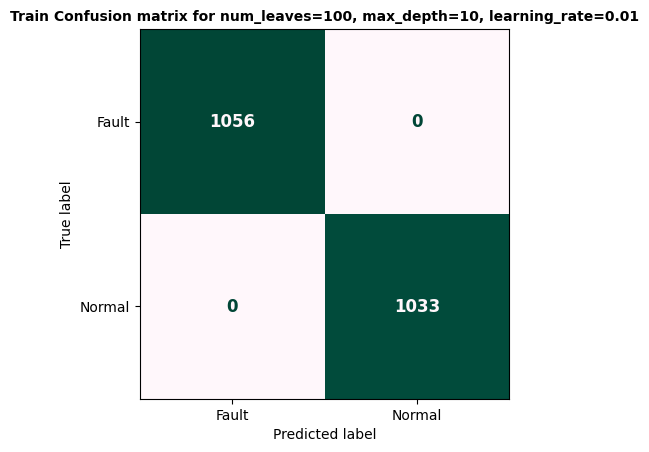

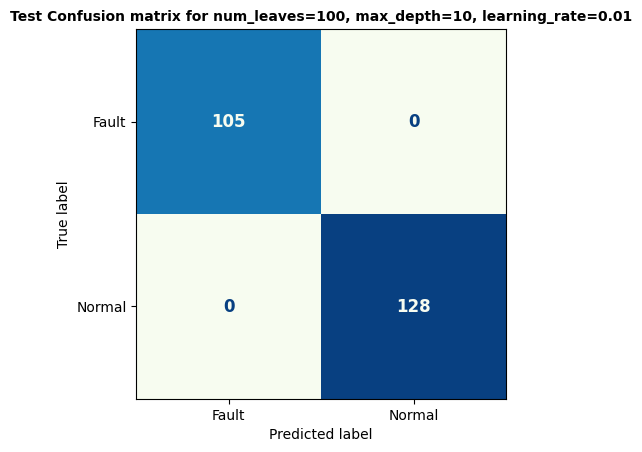

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000490 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

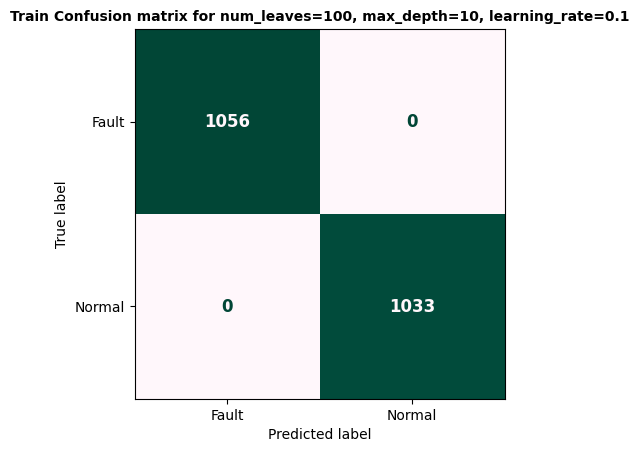

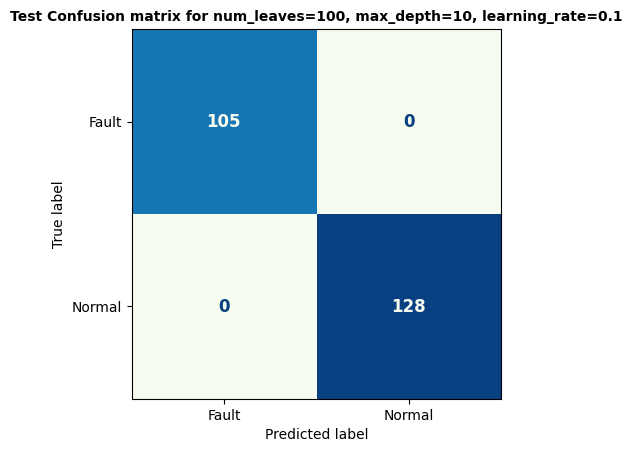

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000493 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

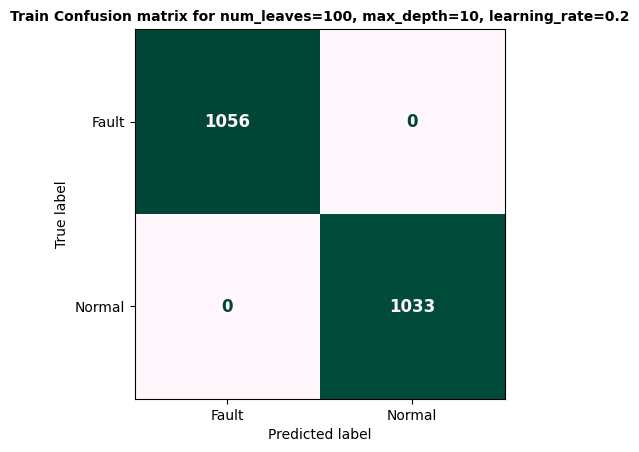

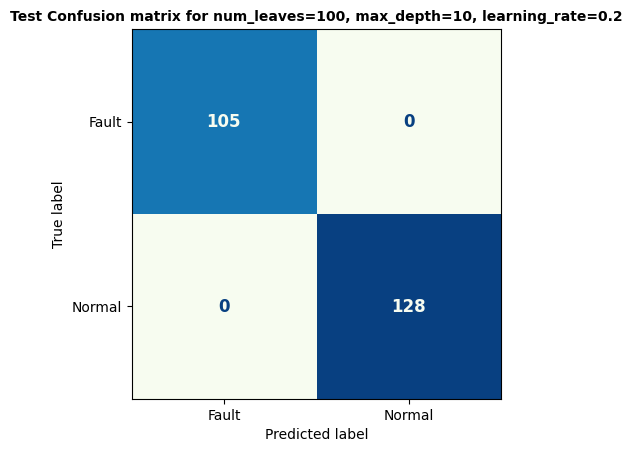

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000498 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

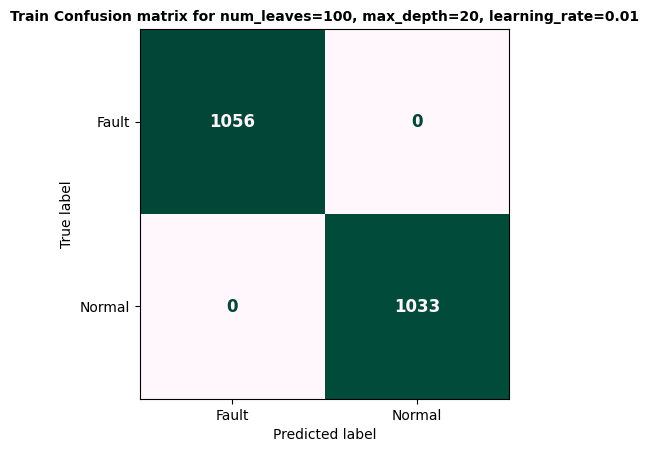

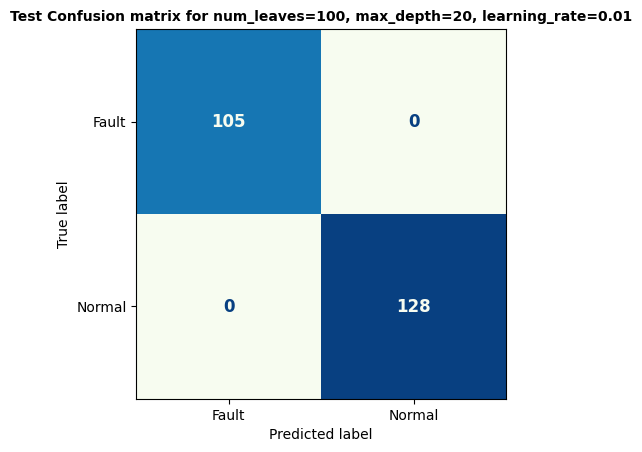

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000485 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

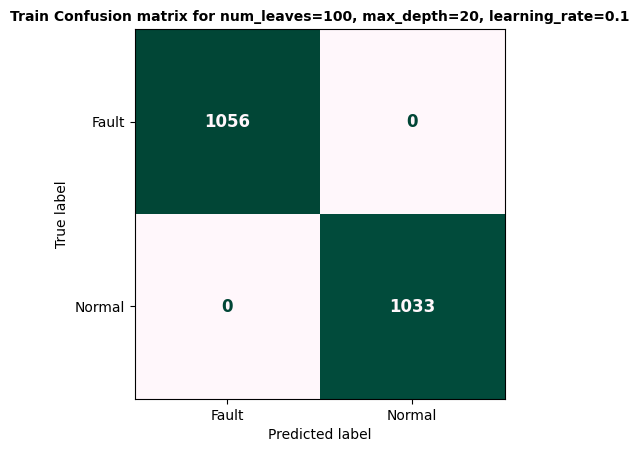

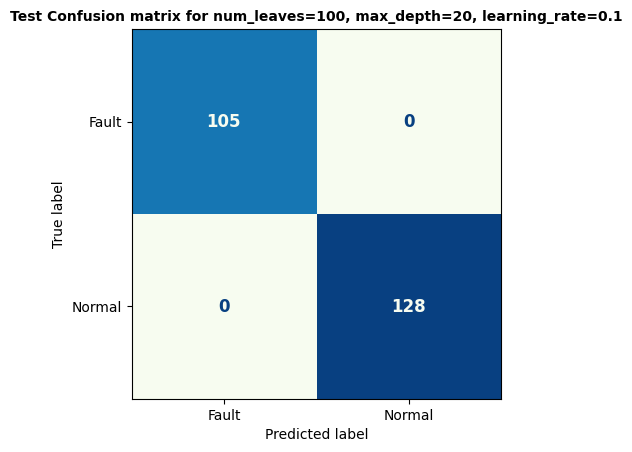

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000510 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

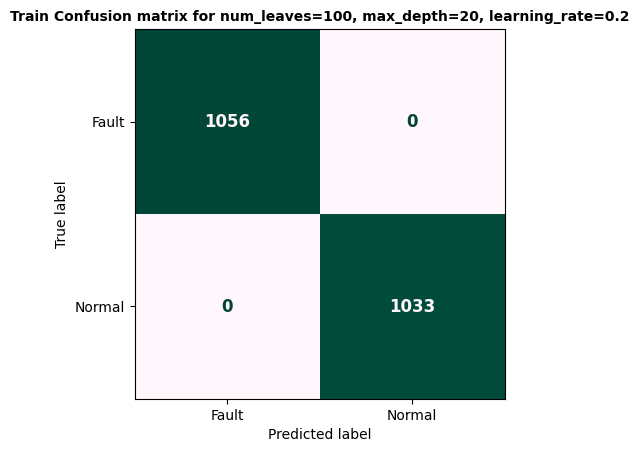

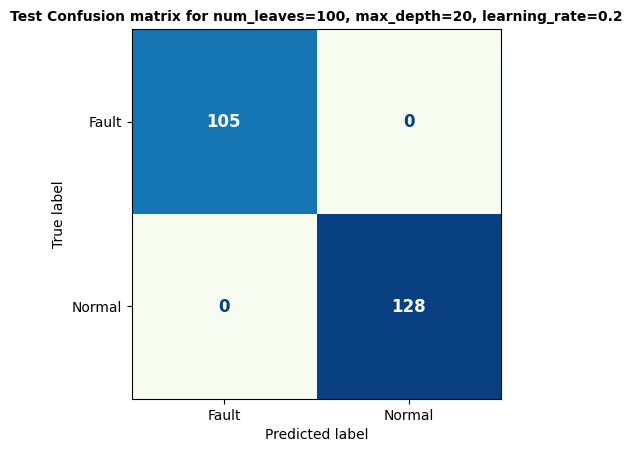

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000557 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

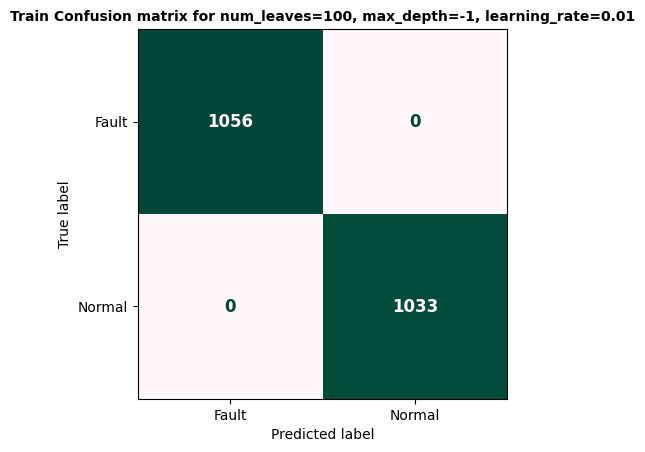

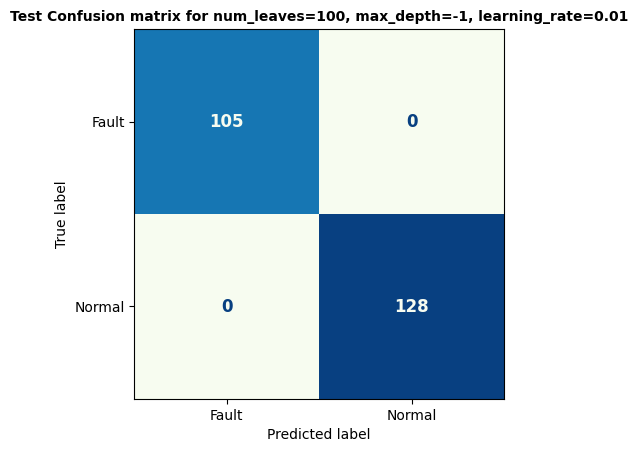

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000522 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

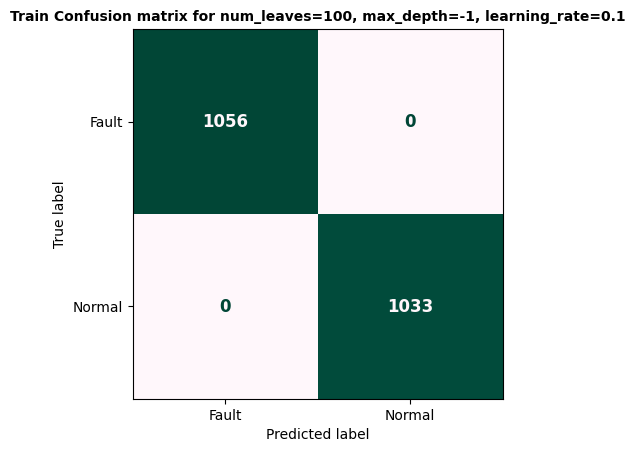

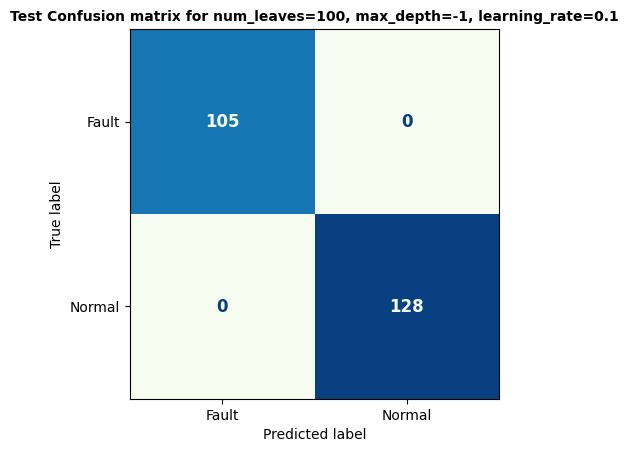

[LightGBM] [Info] Number of positive: 1033, number of negative: 1056
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000508 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3278
[LightGBM] [Info] Number of data points in the train set: 2089, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494495 -> initscore=-0.022021
[LightGBM] [Info] Start training from score -0.022021
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

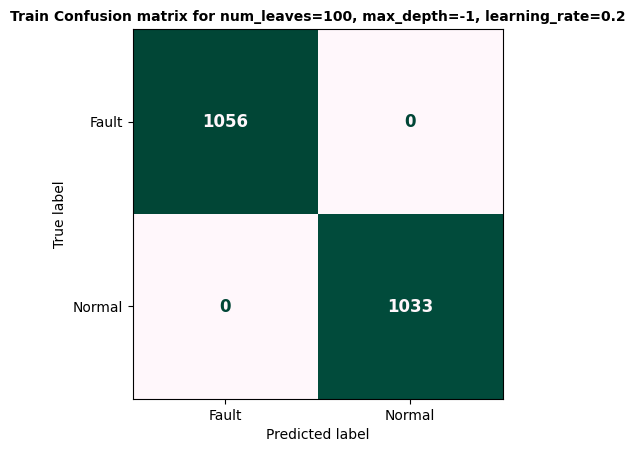

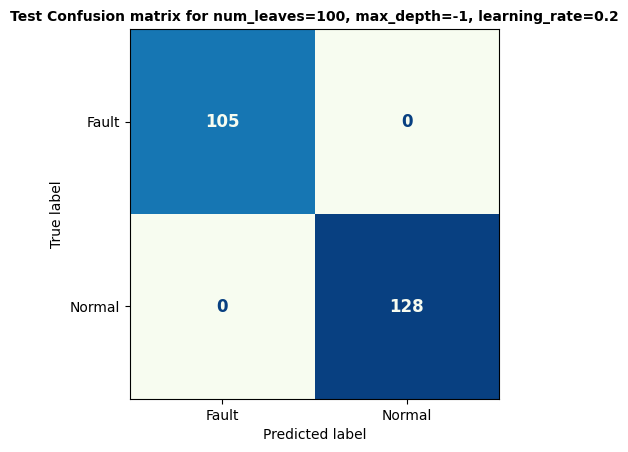

    num_leaves  max_depth  learning_rate  train_accuracy  test_accuracy  \
0           31         10           0.01             1.0            1.0   
1           31         10           0.10             1.0            1.0   
2           31         10           0.20             1.0            1.0   
3           31         20           0.01             1.0            1.0   
4           31         20           0.10             1.0            1.0   
5           31         20           0.20             1.0            1.0   
6           31         -1           0.01             1.0            1.0   
7           31         -1           0.10             1.0            1.0   
8           31         -1           0.20             1.0            1.0   
9           50         10           0.01             1.0            1.0   
10          50         10           0.10             1.0            1.0   
11          50         10           0.20             1.0            1.0   
12          50         20

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from lightgbm import LGBMClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different values of num_leaves, max_depth, and learning_rate
num_leaves_values = [31, 50, 100]
max_depth_values = [10, 20, -1]
learning_rate_values = [0.01, 0.1, 0.2]

for num_leaves in num_leaves_values:
    for max_depth in max_depth_values:
        for learning_rate in learning_rate_values:
            # Initialize the LGBMClassifier
            lgbm = LGBMClassifier(boosting_type='gbdt', num_leaves=num_leaves, max_depth=max_depth, learning_rate=learning_rate)

            # Start the timer
            start = time.time()

            # Fit the model to the training data
            lgbm.fit(X_train, y_train)

            # Make predictions on the test data
            y_pred = lgbm.predict(X_test)

            # Calculate and print test metrics
            print("num_leaves:", num_leaves)
            print("max_depth:", max_depth)
            print("learning_rate:", learning_rate)
            print("Test Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
            print("Test Classification Report:\n", classification_report(y_test, y_pred))

            # Calculate and print train metrics
            y_pred_train = lgbm.predict(X_train)
            print("Train Confusion Matrix:\n", confusion_matrix(y_train, y_pred_train))
            print("Train Classification Report:\n", classification_report(y_train, y_pred_train))

            # Draw the confusion matrix for train data
            conf_matrix_train = confusion_matrix(y_train, y_pred_train)
            disp_train = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_train, display_labels=np.unique(y_train))
            disp_train.plot(cmap='PuBuGn', values_format='d', colorbar=False)  # Remove colorbar
            plt.title(f'Train Confusion matrix for num_leaves={num_leaves}, max_depth={max_depth}, learning_rate={learning_rate}', fontsize=10, fontweight='bold')
            for text in disp_train.text_.ravel():
                text.set_fontsize(12)
                text.set_fontweight('bold')
            plt.show()

            # Draw the confusion matrix for test data
            conf_matrix_test = confusion_matrix(y_test, y_pred)
            disp_test = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_test, display_labels=np.unique(y_test))
            disp_test.plot(cmap='GnBu', values_format='d', colorbar=False)  # Remove colorbar
            plt.title(f'Test Confusion matrix for num_leaves={num_leaves}, max_depth={max_depth}, learning_rate={learning_rate}', fontsize=10, fontweight='bold')
            for text in disp_test.text_.ravel():
                text.set_fontsize(12)
                text.set_fontweight('bold')
            plt.show()

            # Stop the timer
            end = time.time()

            # Append metrics to the results list
            results.append({
                'num_leaves': num_leaves,
                'max_depth': max_depth,
                'learning_rate': learning_rate,
                'train_accuracy': lgbm.score(X_train, y_train),
                'test_accuracy': lgbm.score(X_test, y_test),
                'train_precision': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['precision'],
                'test_precision': classification_report(y_test, y_pred, output_dict=True)['macro avg']['precision'],
                'train_recall': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['recall'],
                'test_recall': classification_report(y_test, y_pred, output_dict=True)['macro avg']['recall'],
                'train_tp': conf_matrix_train[1, 1],
                'test_tp': conf_matrix_test[1, 1],
                'train_tn': conf_matrix_train[0, 0],
                'test_tn': conf_matrix_test[0, 0],
                'train_fp': conf_matrix_train[0, 1],
                'test_fp': conf_matrix_test[0, 1],
                'train_fn': conf_matrix_train[1, 0],
                'test_fn': conf_matrix_test[1, 0],
                'model_fit_time': end - start
            })

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save results to Excel
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/LGBM_landmine_soil.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Rank models based on test metrics
comparison_df['test_f1'] = 2 * (comparison_df['test_precision'] * comparison_df['test_recall']) / (comparison_df['test_precision'] + comparison_df['test_recall'])
ranking = comparison_df[['num_leaves', 'max_depth', 'learning_rate', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_fn', 'test_fp', 'test_tn', 'test_tp']]
ranking = ranking.sort_values(by=['test_f1', 'test_recall', 'test_precision', 'test_accuracy'], ascending=False).reset_index(drop=True)

# Save the ranking to Excel
ranking_excel_filename = 'LGBM_model_ranking.xlsx'
ranking.to_excel(ranking_excel_filename, index=False)
print(f'Model ranking saved to {ranking_excel_filename}')

# Print and rank all models in equation form
print("Model Rankings:")
for idx, row in ranking.iterrows():
    print(f"Model {idx + 1} ({row['test_f1']:.2f}) > ", end="")
print(f"Model {len(ranking)} ({ranking.iloc[-1]['test_f1']:.2f})")


# **16. CatBoostClassifier**

In [16]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 4.5 MB/s eta 0:00:00


0:	learn: 0.6833675	total: 70.4ms	remaining: 633ms
1:	learn: 0.6737802	total: 91.8ms	remaining: 367ms
2:	learn: 0.6643851	total: 109ms	remaining: 254ms
3:	learn: 0.6551575	total: 121ms	remaining: 181ms
4:	learn: 0.6461371	total: 137ms	remaining: 137ms
5:	learn: 0.6372666	total: 150ms	remaining: 99.9ms
6:	learn: 0.6286044	total: 167ms	remaining: 71.5ms
7:	learn: 0.6200497	total: 179ms	remaining: 44.7ms
8:	learn: 0.6116837	total: 194ms	remaining: 21.6ms
9:	learn: 0.6034821	total: 208ms	remaining: 0us
iterations: 10
depth: 4
learning_rate: 0.01
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 1033

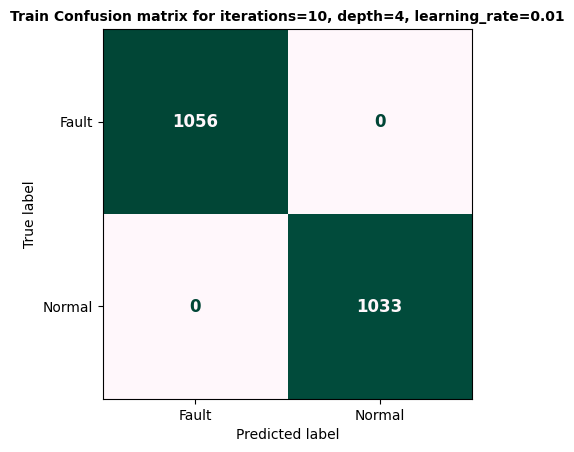

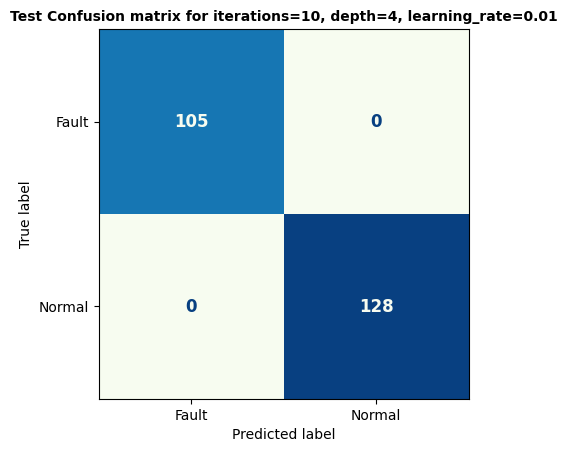

0:	learn: 0.5997107	total: 8.82ms	remaining: 79.4ms
1:	learn: 0.5229339	total: 19.7ms	remaining: 78.7ms
2:	learn: 0.4588045	total: 26.2ms	remaining: 61.1ms
3:	learn: 0.4044132	total: 39ms	remaining: 58.5ms
4:	learn: 0.3580404	total: 45.5ms	remaining: 45.5ms
5:	learn: 0.3179397	total: 52.8ms	remaining: 35.2ms
6:	learn: 0.2832900	total: 60.2ms	remaining: 25.8ms
7:	learn: 0.2527943	total: 77.5ms	remaining: 19.4ms
8:	learn: 0.2261700	total: 89.1ms	remaining: 9.9ms
9:	learn: 0.2027865	total: 95.7ms	remaining: 0us
iterations: 10
depth: 4
learning_rate: 0.1
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [

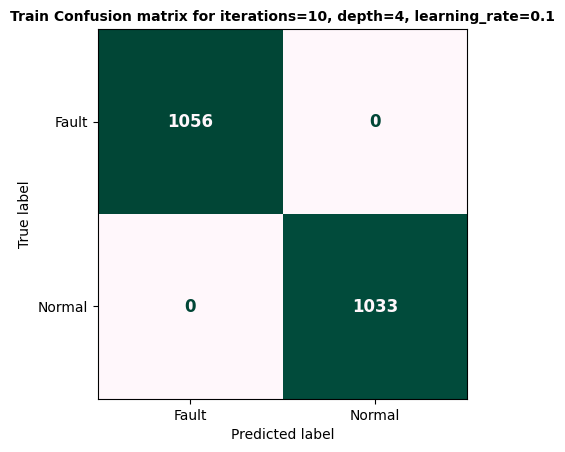

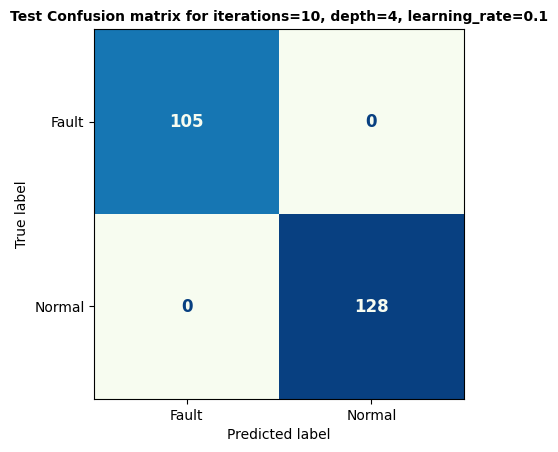

0:	learn: 0.5158718	total: 4.58ms	remaining: 41.2ms
1:	learn: 0.3959905	total: 13.3ms	remaining: 53.3ms
2:	learn: 0.3097967	total: 18ms	remaining: 41.9ms
3:	learn: 0.2453878	total: 28.7ms	remaining: 43.1ms
4:	learn: 0.1963423	total: 34.3ms	remaining: 34.3ms
5:	learn: 0.1581360	total: 47ms	remaining: 31.4ms
6:	learn: 0.1282157	total: 58.9ms	remaining: 25.2ms
7:	learn: 0.1042176	total: 67.6ms	remaining: 16.9ms
8:	learn: 0.0851661	total: 80.2ms	remaining: 8.91ms
9:	learn: 0.0699288	total: 98.1ms	remaining: 0us
iterations: 10
depth: 4
learning_rate: 0.2
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [ 

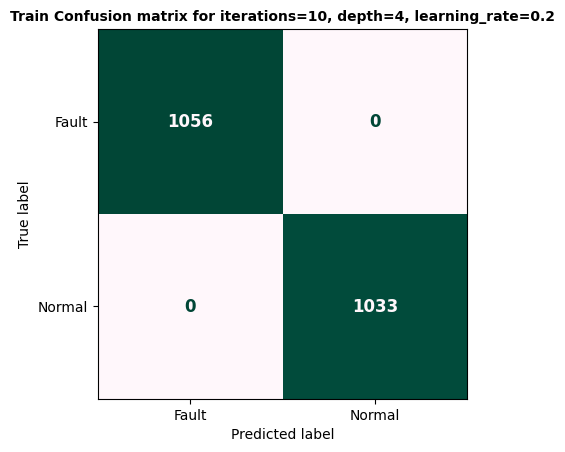

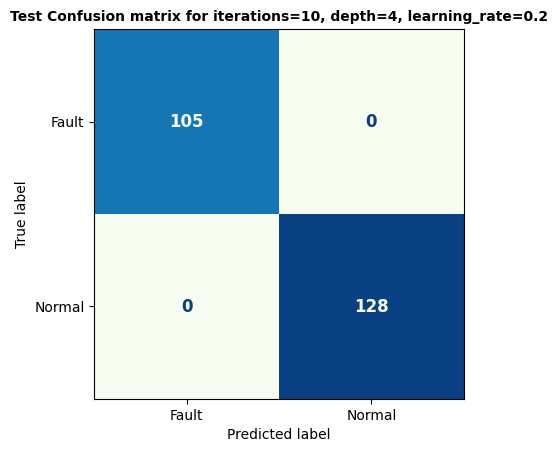

0:	learn: 0.6834208	total: 12.3ms	remaining: 110ms
1:	learn: 0.6738835	total: 18.9ms	remaining: 75.7ms
2:	learn: 0.6645639	total: 29.6ms	remaining: 69ms
3:	learn: 0.6554293	total: 36.8ms	remaining: 55.3ms
4:	learn: 0.6463962	total: 45.7ms	remaining: 45.7ms
5:	learn: 0.6375898	total: 53.8ms	remaining: 35.9ms
6:	learn: 0.6291094	total: 62.3ms	remaining: 26.7ms
7:	learn: 0.6207068	total: 71.1ms	remaining: 17.8ms
8:	learn: 0.6123569	total: 88.9ms	remaining: 9.87ms
9:	learn: 0.6042482	total: 100ms	remaining: 0us
iterations: 10
depth: 6
learning_rate: 0.01
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [

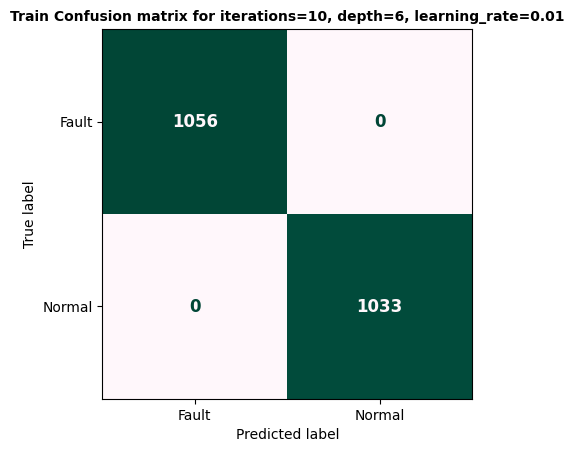

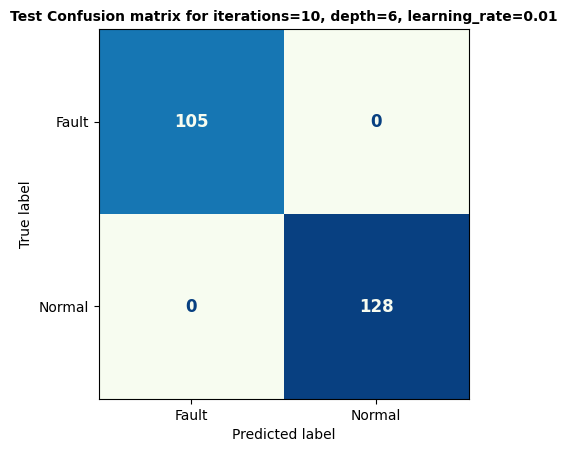

0:	learn: 0.6001971	total: 18ms	remaining: 162ms
1:	learn: 0.5237488	total: 57.7ms	remaining: 231ms
2:	learn: 0.4600111	total: 89.8ms	remaining: 210ms
3:	learn: 0.4060172	total: 104ms	remaining: 156ms
4:	learn: 0.3593982	total: 116ms	remaining: 116ms
5:	learn: 0.3194753	total: 125ms	remaining: 83ms
6:	learn: 0.2855193	total: 135ms	remaining: 57.8ms
7:	learn: 0.2555060	total: 146ms	remaining: 36.5ms
8:	learn: 0.2287183	total: 156ms	remaining: 17.4ms
9:	learn: 0.2054801	total: 166ms	remaining: 0us
iterations: 10
depth: 6
learning_rate: 0.1
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 1033]]
T

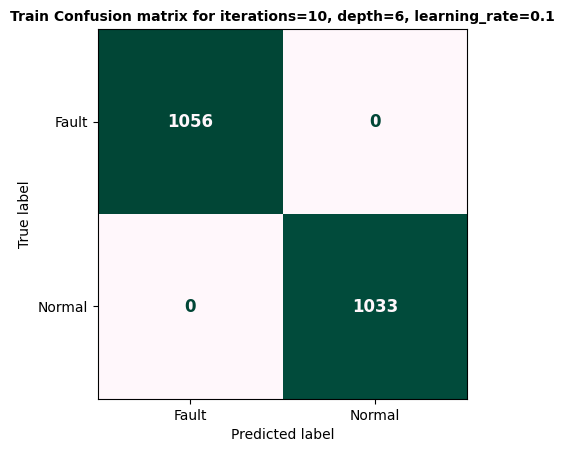

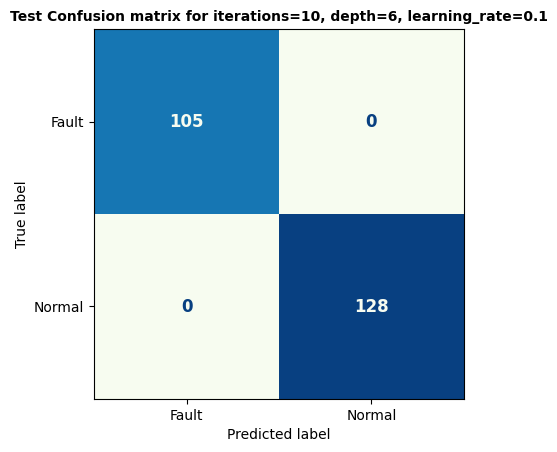

0:	learn: 0.5167424	total: 16.1ms	remaining: 145ms
1:	learn: 0.3972538	total: 38.2ms	remaining: 153ms
2:	learn: 0.3114650	total: 53.2ms	remaining: 124ms
3:	learn: 0.2471410	total: 66.4ms	remaining: 99.6ms
4:	learn: 0.1977021	total: 93.2ms	remaining: 93.2ms
5:	learn: 0.1596567	total: 114ms	remaining: 75.8ms
6:	learn: 0.1305295	total: 123ms	remaining: 52.9ms
7:	learn: 0.1070021	total: 132ms	remaining: 33ms
8:	learn: 0.0877452	total: 145ms	remaining: 16.1ms
9:	learn: 0.0726092	total: 159ms	remaining: 0us
iterations: 10
depth: 6
learning_rate: 0.2
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 10

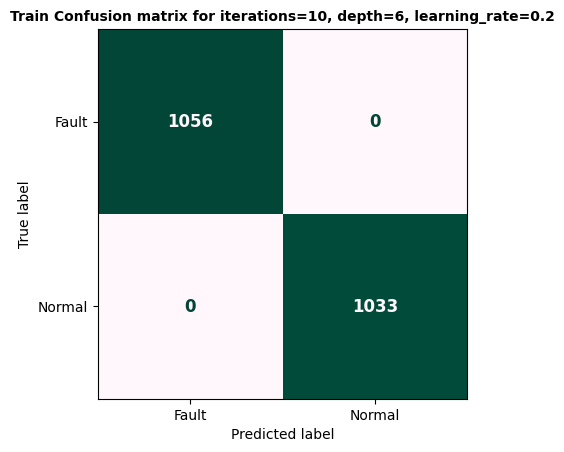

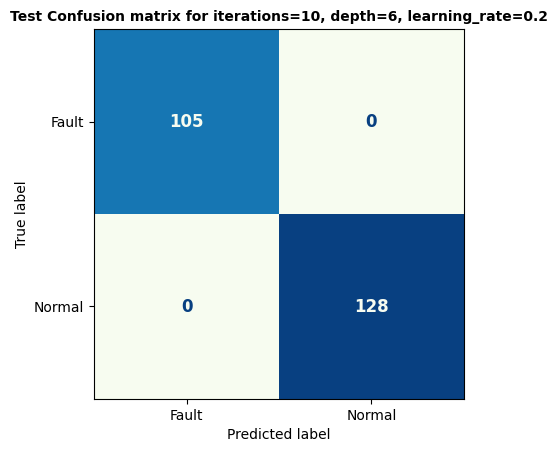

0:	learn: 0.6835262	total: 163ms	remaining: 1.47s
1:	learn: 0.6740960	total: 203ms	remaining: 814ms
2:	learn: 0.6648110	total: 251ms	remaining: 585ms
3:	learn: 0.6556487	total: 299ms	remaining: 449ms
4:	learn: 0.6467223	total: 341ms	remaining: 341ms
5:	learn: 0.6380476	total: 405ms	remaining: 270ms
6:	learn: 0.6295453	total: 456ms	remaining: 195ms
7:	learn: 0.6212320	total: 497ms	remaining: 124ms
8:	learn: 0.6129675	total: 539ms	remaining: 59.9ms
9:	learn: 0.6048220	total: 571ms	remaining: 0us
iterations: 10
depth: 8
learning_rate: 0.01
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 1033]]
Tr

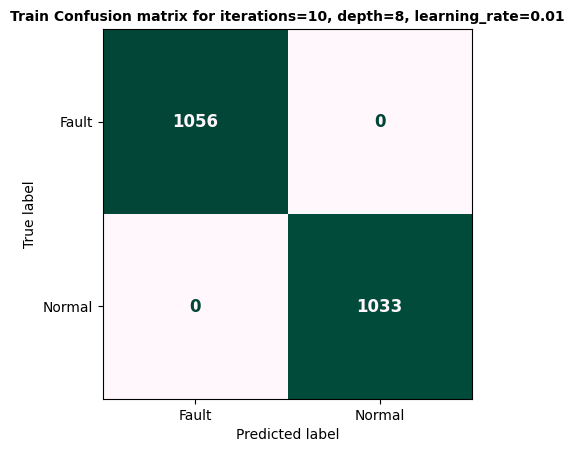

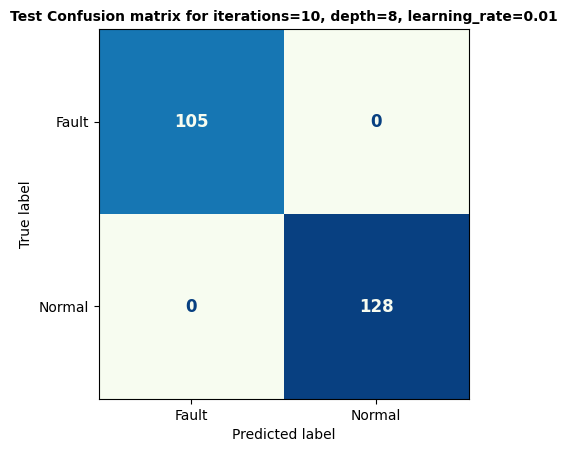

0:	learn: 0.6011575	total: 227ms	remaining: 2.04s
1:	learn: 0.5253825	total: 310ms	remaining: 1.24s
2:	learn: 0.4616617	total: 461ms	remaining: 1.07s
3:	learn: 0.4072892	total: 564ms	remaining: 845ms
4:	learn: 0.3610899	total: 704ms	remaining: 704ms
5:	learn: 0.3216314	total: 837ms	remaining: 558ms
6:	learn: 0.2873703	total: 942ms	remaining: 404ms
7:	learn: 0.2575411	total: 1.02s	remaining: 256ms
8:	learn: 0.2309051	total: 1.16s	remaining: 129ms
9:	learn: 0.2073154	total: 1.23s	remaining: 0us
iterations: 10
depth: 8
learning_rate: 0.1
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 1033]]
Trai

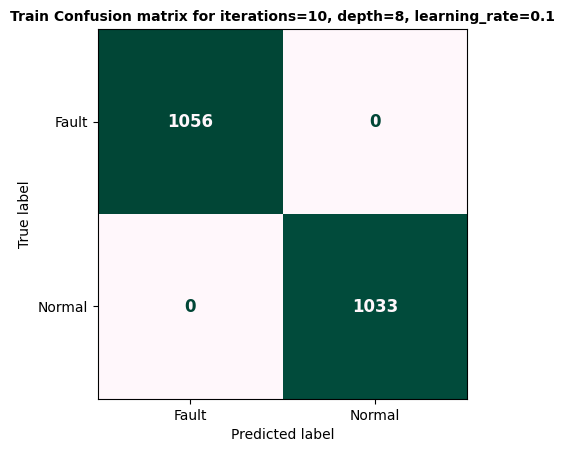

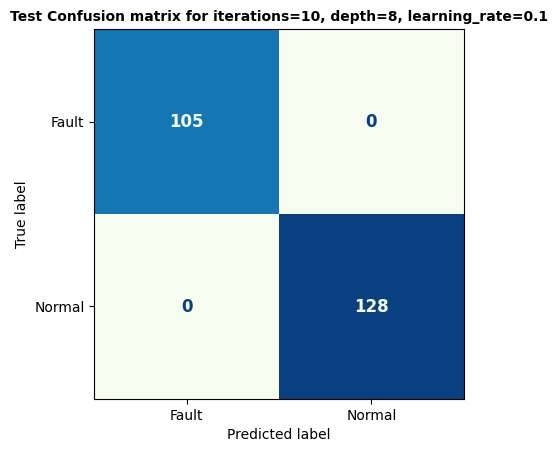

0:	learn: 0.5184608	total: 145ms	remaining: 1.31s
1:	learn: 0.3997201	total: 220ms	remaining: 882ms
2:	learn: 0.3132771	total: 276ms	remaining: 645ms
3:	learn: 0.2486023	total: 325ms	remaining: 487ms
4:	learn: 0.1995835	total: 397ms	remaining: 397ms
5:	learn: 0.1623565	total: 449ms	remaining: 299ms
6:	learn: 0.1326084	total: 535ms	remaining: 229ms
7:	learn: 0.1091831	total: 582ms	remaining: 146ms
8:	learn: 0.0897272	total: 641ms	remaining: 71.2ms
9:	learn: 0.0740897	total: 732ms	remaining: 0us
iterations: 10
depth: 8
learning_rate: 0.2
Test Confusion Matrix:
 [[105   0]
 [  0 128]]
Test Classification Report:
               precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       105
      Normal       1.00      1.00      1.00       128

    accuracy                           1.00       233
   macro avg       1.00      1.00      1.00       233
weighted avg       1.00      1.00      1.00       233

Train Confusion Matrix:
 [[1056    0]
 [   0 1033]]
Tra

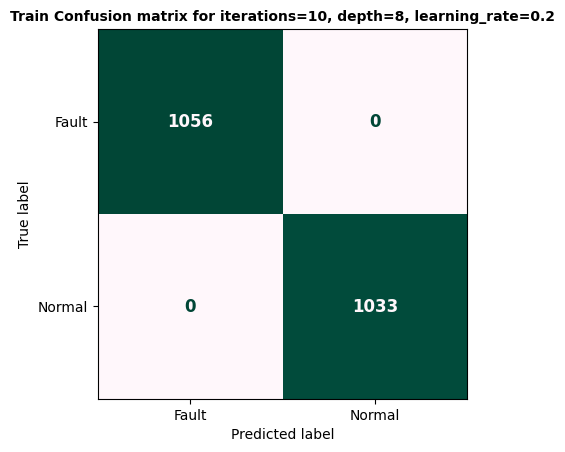

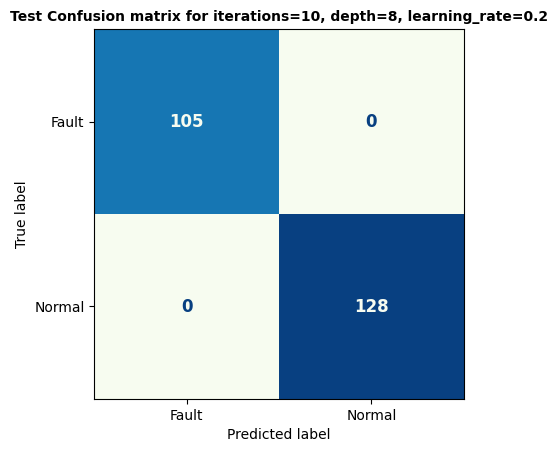

0:	learn: 0.6833675	total: 7.31ms	remaining: 358ms
1:	learn: 0.6737802	total: 9.91ms	remaining: 238ms
2:	learn: 0.6643851	total: 12.5ms	remaining: 195ms
3:	learn: 0.6551575	total: 16ms	remaining: 184ms
4:	learn: 0.6461371	total: 20.5ms	remaining: 184ms
5:	learn: 0.6372666	total: 26.1ms	remaining: 191ms
6:	learn: 0.6286044	total: 35.8ms	remaining: 220ms
7:	learn: 0.6200497	total: 43.8ms	remaining: 230ms
8:	learn: 0.6116837	total: 50.8ms	remaining: 231ms
9:	learn: 0.6034821	total: 57.6ms	remaining: 230ms
10:	learn: 0.5954081	total: 62.5ms	remaining: 222ms
11:	learn: 0.5875278	total: 70.1ms	remaining: 222ms
12:	learn: 0.5797158	total: 76.7ms	remaining: 218ms
13:	learn: 0.5720904	total: 81.5ms	remaining: 209ms
14:	learn: 0.5645487	total: 84.1ms	remaining: 196ms
15:	learn: 0.5572167	total: 86.6ms	remaining: 184ms
16:	learn: 0.5499304	total: 90ms	remaining: 175ms
17:	learn: 0.5428817	total: 94.5ms	remaining: 168ms
18:	learn: 0.5358141	total: 98ms	remaining: 160ms
19:	learn: 0.5288749	total: 

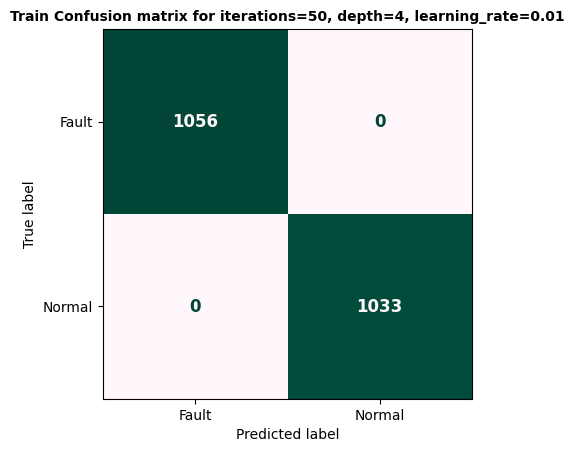

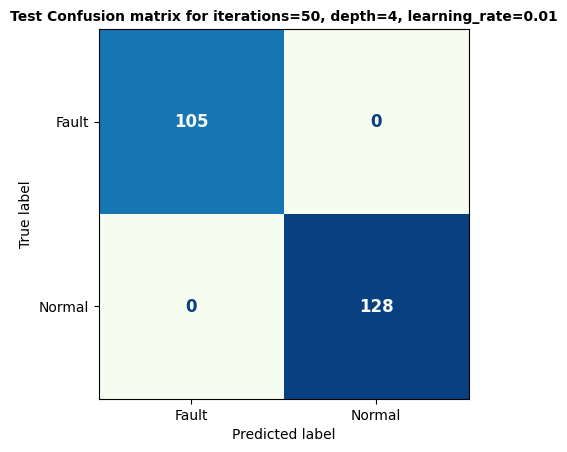

0:	learn: 0.5997107	total: 2.59ms	remaining: 127ms
1:	learn: 0.5229339	total: 10.7ms	remaining: 257ms
2:	learn: 0.4588045	total: 13.7ms	remaining: 215ms
3:	learn: 0.4044132	total: 24.8ms	remaining: 285ms
4:	learn: 0.3580404	total: 33.3ms	remaining: 300ms
5:	learn: 0.3179397	total: 36.3ms	remaining: 266ms
6:	learn: 0.2832900	total: 47.1ms	remaining: 290ms
7:	learn: 0.2527943	total: 52.1ms	remaining: 273ms
8:	learn: 0.2261700	total: 60.2ms	remaining: 274ms
9:	learn: 0.2027865	total: 67.4ms	remaining: 270ms
10:	learn: 0.1820509	total: 74.7ms	remaining: 265ms
11:	learn: 0.1637925	total: 83ms	remaining: 263ms
12:	learn: 0.1473900	total: 90.4ms	remaining: 257ms
13:	learn: 0.1328996	total: 109ms	remaining: 281ms
14:	learn: 0.1198709	total: 117ms	remaining: 273ms
15:	learn: 0.1084586	total: 125ms	remaining: 266ms
16:	learn: 0.0980066	total: 132ms	remaining: 257ms
17:	learn: 0.0886564	total: 139ms	remaining: 248ms
18:	learn: 0.0802302	total: 147ms	remaining: 240ms
19:	learn: 0.0726785	total: 15

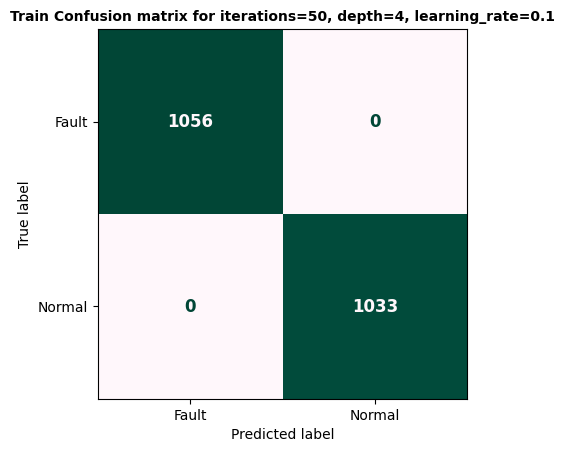

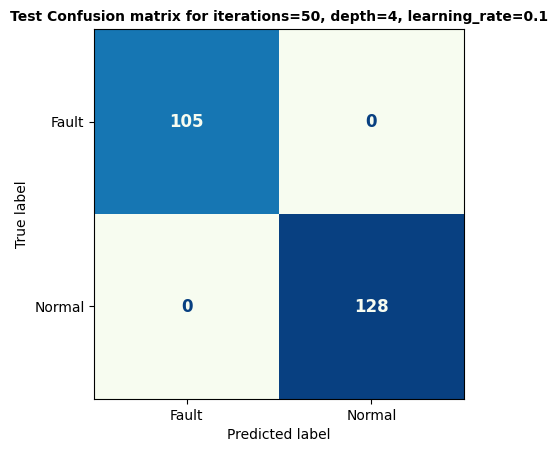

0:	learn: 0.5158718	total: 2.56ms	remaining: 125ms
1:	learn: 0.3959905	total: 5.17ms	remaining: 124ms
2:	learn: 0.3097967	total: 10.7ms	remaining: 167ms
3:	learn: 0.2453878	total: 17.6ms	remaining: 203ms
4:	learn: 0.1963423	total: 25.8ms	remaining: 232ms
5:	learn: 0.1581360	total: 34.2ms	remaining: 251ms
6:	learn: 0.1282157	total: 37.1ms	remaining: 228ms
7:	learn: 0.1042176	total: 48ms	remaining: 252ms
8:	learn: 0.0851661	total: 50.7ms	remaining: 231ms
9:	learn: 0.0699288	total: 57.8ms	remaining: 231ms
10:	learn: 0.0576006	total: 60.6ms	remaining: 215ms
11:	learn: 0.0475670	total: 63.3ms	remaining: 200ms
12:	learn: 0.0393879	total: 67.4ms	remaining: 192ms
13:	learn: 0.0327721	total: 70ms	remaining: 180ms
14:	learn: 0.0272993	total: 80.1ms	remaining: 187ms
15:	learn: 0.0230662	total: 82.7ms	remaining: 176ms
16:	learn: 0.0194035	total: 85.4ms	remaining: 166ms
17:	learn: 0.0162951	total: 88.1ms	remaining: 157ms
18:	learn: 0.0137813	total: 91.8ms	remaining: 150ms
19:	learn: 0.0116955	total

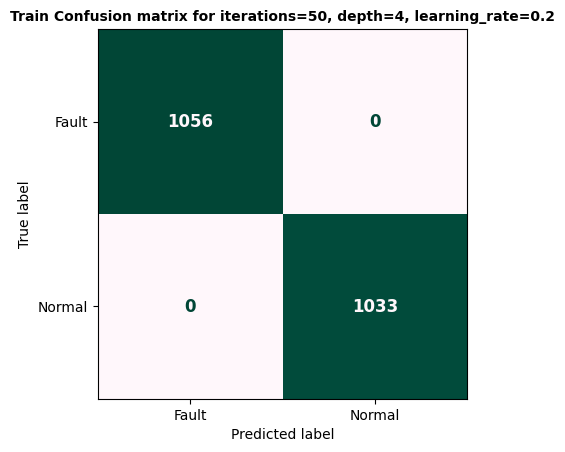

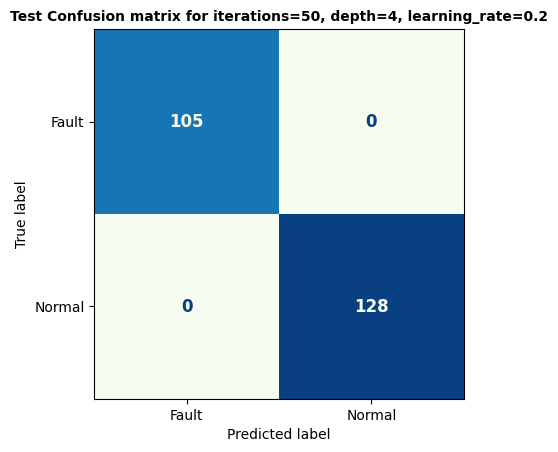

0:	learn: 0.6834208	total: 8ms	remaining: 392ms
1:	learn: 0.6738835	total: 28ms	remaining: 672ms
2:	learn: 0.6645639	total: 50.2ms	remaining: 786ms
3:	learn: 0.6554293	total: 71.5ms	remaining: 822ms
4:	learn: 0.6463962	total: 92.7ms	remaining: 835ms
5:	learn: 0.6375898	total: 105ms	remaining: 767ms
6:	learn: 0.6291094	total: 114ms	remaining: 701ms
7:	learn: 0.6207068	total: 146ms	remaining: 768ms
8:	learn: 0.6123569	total: 166ms	remaining: 757ms
9:	learn: 0.6042482	total: 189ms	remaining: 757ms
10:	learn: 0.5961766	total: 209ms	remaining: 742ms
11:	learn: 0.5882530	total: 238ms	remaining: 753ms
12:	learn: 0.5804989	total: 252ms	remaining: 719ms
13:	learn: 0.5728880	total: 268ms	remaining: 688ms
14:	learn: 0.5653386	total: 280ms	remaining: 653ms
15:	learn: 0.5579507	total: 287ms	remaining: 611ms
16:	learn: 0.5506827	total: 298ms	remaining: 578ms
17:	learn: 0.5436568	total: 311ms	remaining: 552ms
18:	learn: 0.5366451	total: 337ms	remaining: 550ms
19:	learn: 0.5298407	total: 358ms	remaini

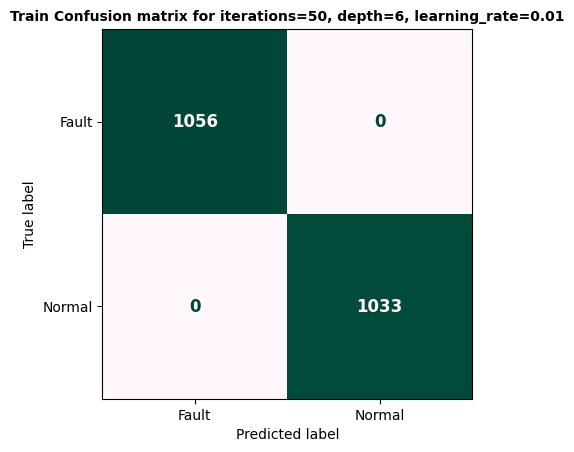

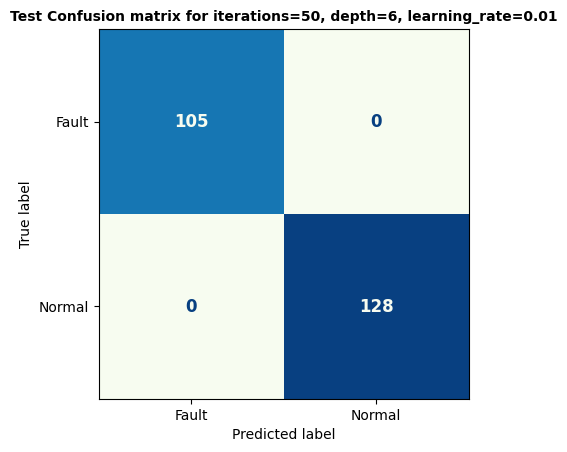

0:	learn: 0.6001971	total: 16.7ms	remaining: 821ms
1:	learn: 0.5237488	total: 44.9ms	remaining: 1.08s
2:	learn: 0.4600111	total: 68.3ms	remaining: 1.07s
3:	learn: 0.4060172	total: 86.3ms	remaining: 993ms
4:	learn: 0.3593982	total: 113ms	remaining: 1.02s
5:	learn: 0.3194753	total: 136ms	remaining: 1000ms
6:	learn: 0.2855193	total: 155ms	remaining: 952ms
7:	learn: 0.2555060	total: 178ms	remaining: 932ms
8:	learn: 0.2287183	total: 202ms	remaining: 918ms
9:	learn: 0.2054801	total: 224ms	remaining: 897ms
10:	learn: 0.1844947	total: 249ms	remaining: 882ms
11:	learn: 0.1659136	total: 331ms	remaining: 1.05s
12:	learn: 0.1495292	total: 383ms	remaining: 1.09s
13:	learn: 0.1349797	total: 426ms	remaining: 1.09s
14:	learn: 0.1217238	total: 477ms	remaining: 1.11s
15:	learn: 0.1099783	total: 541ms	remaining: 1.15s
16:	learn: 0.0994695	total: 573ms	remaining: 1.11s
17:	learn: 0.0902583	total: 608ms	remaining: 1.08s
18:	learn: 0.0818358	total: 633ms	remaining: 1.03s
19:	learn: 0.0744740	total: 673ms	re

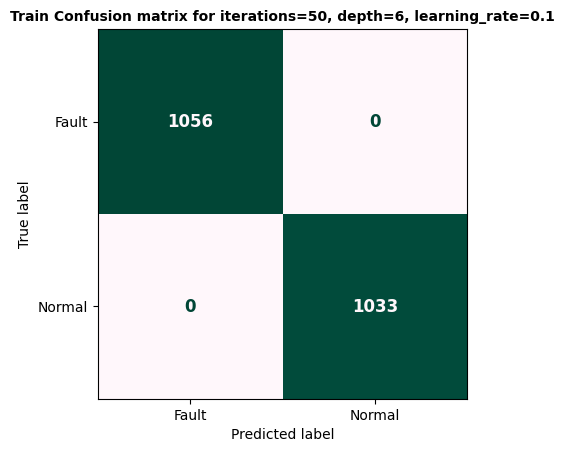

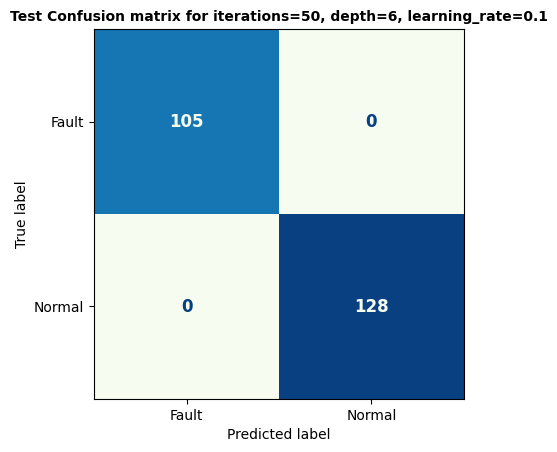

0:	learn: 0.5167424	total: 20.2ms	remaining: 988ms
1:	learn: 0.3972538	total: 46.5ms	remaining: 1.12s
2:	learn: 0.3114650	total: 71.9ms	remaining: 1.13s
3:	learn: 0.2471410	total: 91ms	remaining: 1.05s
4:	learn: 0.1977021	total: 144ms	remaining: 1.29s
5:	learn: 0.1596567	total: 184ms	remaining: 1.34s
6:	learn: 0.1305295	total: 212ms	remaining: 1.3s
7:	learn: 0.1070021	total: 257ms	remaining: 1.35s
8:	learn: 0.0877452	total: 281ms	remaining: 1.28s
9:	learn: 0.0726092	total: 295ms	remaining: 1.18s
10:	learn: 0.0598108	total: 311ms	remaining: 1.1s
11:	learn: 0.0495072	total: 325ms	remaining: 1.03s
12:	learn: 0.0412367	total: 342ms	remaining: 972ms
13:	learn: 0.0345686	total: 365ms	remaining: 938ms
14:	learn: 0.0287755	total: 379ms	remaining: 885ms
15:	learn: 0.0242170	total: 426ms	remaining: 905ms
16:	learn: 0.0204469	total: 440ms	remaining: 855ms
17:	learn: 0.0175450	total: 457ms	remaining: 813ms
18:	learn: 0.0149797	total: 473ms	remaining: 772ms
19:	learn: 0.0129377	total: 490ms	remaini

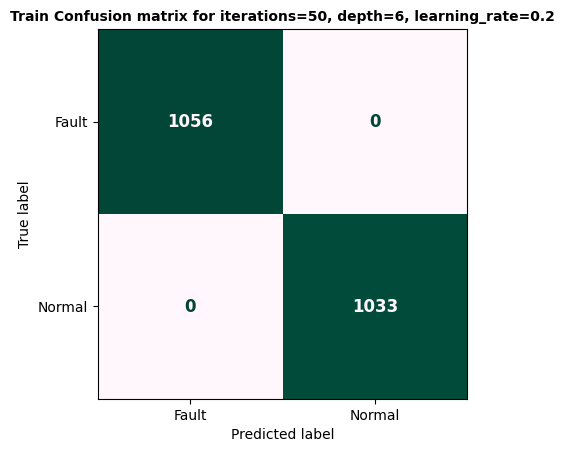

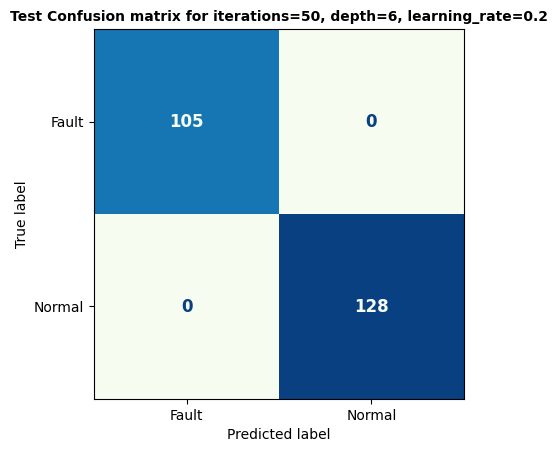

0:	learn: 0.6835262	total: 79.4ms	remaining: 3.89s
1:	learn: 0.6740960	total: 122ms	remaining: 2.92s
2:	learn: 0.6648110	total: 165ms	remaining: 2.58s
3:	learn: 0.6556487	total: 193ms	remaining: 2.22s
4:	learn: 0.6467223	total: 228ms	remaining: 2.05s
5:	learn: 0.6380476	total: 270ms	remaining: 1.98s
6:	learn: 0.6295453	total: 323ms	remaining: 1.98s
7:	learn: 0.6212320	total: 375ms	remaining: 1.97s
8:	learn: 0.6129675	total: 426ms	remaining: 1.94s
9:	learn: 0.6048220	total: 479ms	remaining: 1.91s
10:	learn: 0.5968511	total: 525ms	remaining: 1.86s
11:	learn: 0.5891293	total: 589ms	remaining: 1.86s
12:	learn: 0.5814863	total: 639ms	remaining: 1.82s
13:	learn: 0.5739168	total: 689ms	remaining: 1.77s
14:	learn: 0.5665554	total: 740ms	remaining: 1.73s
15:	learn: 0.5592025	total: 791ms	remaining: 1.68s
16:	learn: 0.5520317	total: 853ms	remaining: 1.66s
17:	learn: 0.5450058	total: 898ms	remaining: 1.6s
18:	learn: 0.5380616	total: 952ms	remaining: 1.55s
19:	learn: 0.5312135	total: 997ms	remaini

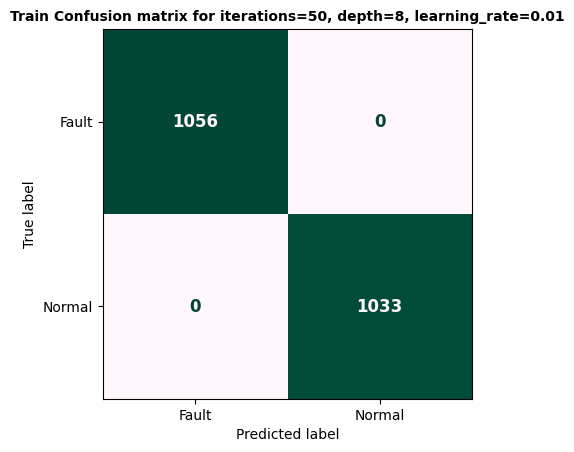

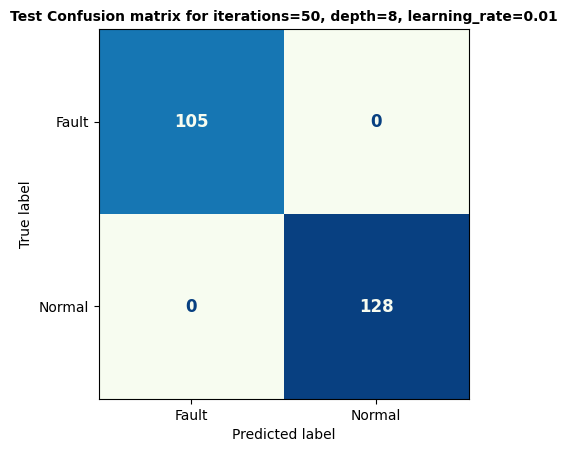

0:	learn: 0.6011575	total: 88.7ms	remaining: 4.34s
1:	learn: 0.5253825	total: 124ms	remaining: 2.98s
2:	learn: 0.4616617	total: 152ms	remaining: 2.38s
3:	learn: 0.4072892	total: 183ms	remaining: 2.1s
4:	learn: 0.3610899	total: 225ms	remaining: 2.03s
5:	learn: 0.3216314	total: 267ms	remaining: 1.95s
6:	learn: 0.2873703	total: 340ms	remaining: 2.09s
7:	learn: 0.2575411	total: 403ms	remaining: 2.11s
8:	learn: 0.2309051	total: 464ms	remaining: 2.11s
9:	learn: 0.2073154	total: 518ms	remaining: 2.07s
10:	learn: 0.1865481	total: 575ms	remaining: 2.04s
11:	learn: 0.1684903	total: 637ms	remaining: 2.02s
12:	learn: 0.1522167	total: 684ms	remaining: 1.95s
13:	learn: 0.1375619	total: 735ms	remaining: 1.89s
14:	learn: 0.1247163	total: 787ms	remaining: 1.84s
15:	learn: 0.1130184	total: 823ms	remaining: 1.75s
16:	learn: 0.1025706	total: 864ms	remaining: 1.68s
17:	learn: 0.0932503	total: 902ms	remaining: 1.6s
18:	learn: 0.0847446	total: 929ms	remaining: 1.51s
19:	learn: 0.0770020	total: 970ms	remainin

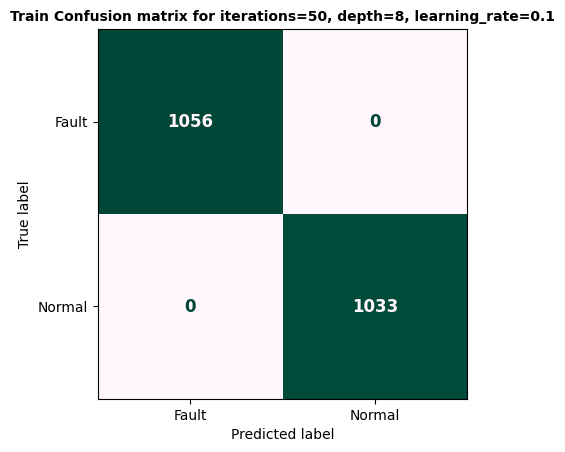

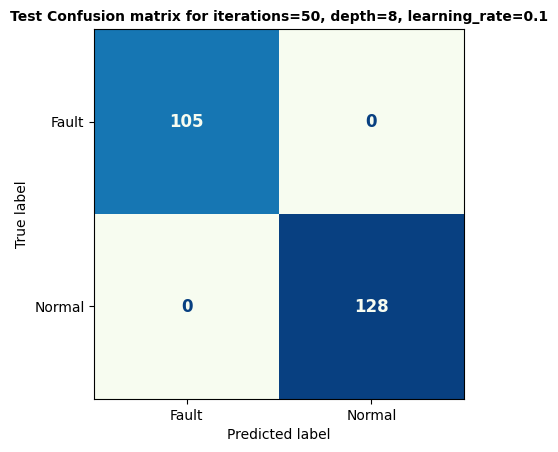

0:	learn: 0.5184608	total: 131ms	remaining: 6.43s
1:	learn: 0.3997201	total: 215ms	remaining: 5.16s
2:	learn: 0.3132771	total: 295ms	remaining: 4.63s
3:	learn: 0.2486023	total: 399ms	remaining: 4.58s
4:	learn: 0.1995835	total: 487ms	remaining: 4.38s
5:	learn: 0.1623565	total: 586ms	remaining: 4.3s
6:	learn: 0.1326084	total: 689ms	remaining: 4.23s
7:	learn: 0.1091831	total: 774ms	remaining: 4.06s
8:	learn: 0.0897272	total: 856ms	remaining: 3.9s
9:	learn: 0.0740897	total: 938ms	remaining: 3.75s
10:	learn: 0.0615034	total: 1.02s	remaining: 3.62s
11:	learn: 0.0516404	total: 1.12s	remaining: 3.53s
12:	learn: 0.0433701	total: 1.2s	remaining: 3.42s
13:	learn: 0.0364926	total: 1.26s	remaining: 3.25s
14:	learn: 0.0310826	total: 1.32s	remaining: 3.09s
15:	learn: 0.0264616	total: 1.39s	remaining: 2.94s
16:	learn: 0.0226553	total: 1.45s	remaining: 2.82s
17:	learn: 0.0195355	total: 1.51s	remaining: 2.69s
18:	learn: 0.0167494	total: 1.59s	remaining: 2.59s
19:	learn: 0.0143319	total: 1.67s	remaining:

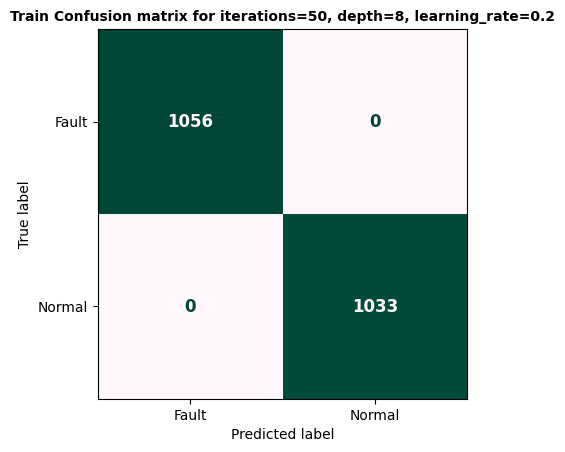

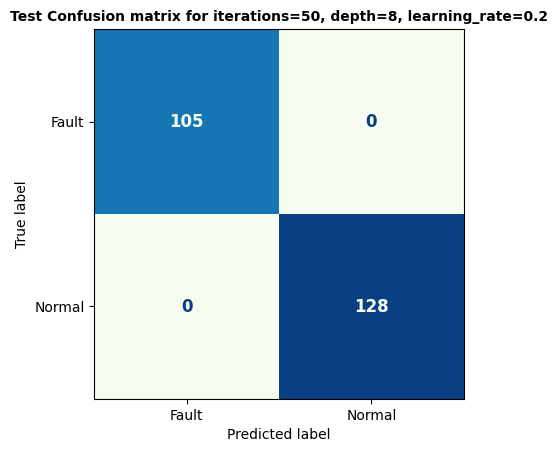

0:	learn: 0.6833675	total: 3.03ms	remaining: 300ms
1:	learn: 0.6737802	total: 7.21ms	remaining: 353ms
2:	learn: 0.6643851	total: 9.99ms	remaining: 323ms
3:	learn: 0.6551575	total: 13.5ms	remaining: 325ms
4:	learn: 0.6461371	total: 16.8ms	remaining: 319ms
5:	learn: 0.6372666	total: 20.1ms	remaining: 314ms
6:	learn: 0.6286044	total: 23.6ms	remaining: 313ms
7:	learn: 0.6200497	total: 26.8ms	remaining: 309ms
8:	learn: 0.6116837	total: 30.9ms	remaining: 313ms
9:	learn: 0.6034821	total: 38ms	remaining: 342ms
10:	learn: 0.5954081	total: 41.4ms	remaining: 335ms
11:	learn: 0.5875278	total: 44.7ms	remaining: 327ms
12:	learn: 0.5797158	total: 48.1ms	remaining: 322ms
13:	learn: 0.5720904	total: 51.5ms	remaining: 316ms
14:	learn: 0.5645487	total: 54.8ms	remaining: 311ms
15:	learn: 0.5572167	total: 58.1ms	remaining: 305ms
16:	learn: 0.5499304	total: 61.3ms	remaining: 299ms
17:	learn: 0.5428817	total: 64.6ms	remaining: 294ms
18:	learn: 0.5358141	total: 67.9ms	remaining: 290ms
19:	learn: 0.5288749	tot

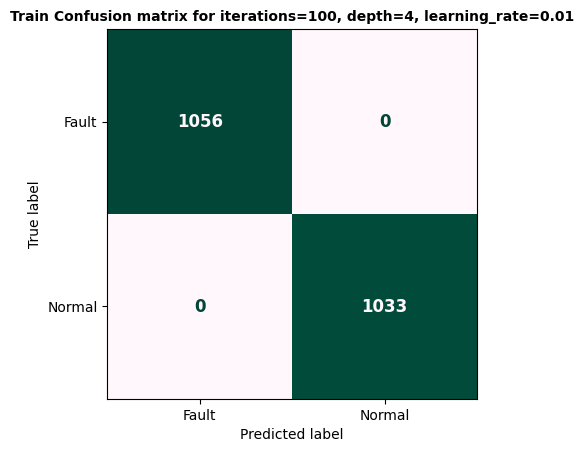

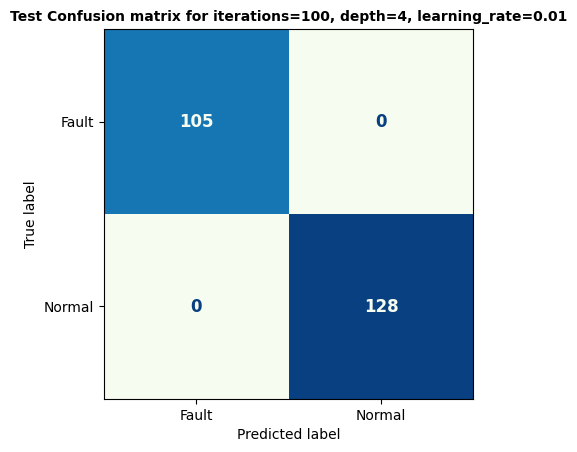

0:	learn: 0.5997107	total: 3.95ms	remaining: 391ms
1:	learn: 0.5229339	total: 7.27ms	remaining: 356ms
2:	learn: 0.4588045	total: 11.9ms	remaining: 386ms
3:	learn: 0.4044132	total: 16.1ms	remaining: 386ms
4:	learn: 0.3580404	total: 19.4ms	remaining: 368ms
5:	learn: 0.3179397	total: 22.1ms	remaining: 347ms
6:	learn: 0.2832900	total: 25ms	remaining: 332ms
7:	learn: 0.2527943	total: 27.8ms	remaining: 319ms
8:	learn: 0.2261700	total: 30.6ms	remaining: 309ms
9:	learn: 0.2027865	total: 33.4ms	remaining: 301ms
10:	learn: 0.1820509	total: 36.2ms	remaining: 293ms
11:	learn: 0.1637925	total: 38.9ms	remaining: 285ms
12:	learn: 0.1473900	total: 41.9ms	remaining: 281ms
13:	learn: 0.1328996	total: 44.7ms	remaining: 275ms
14:	learn: 0.1198709	total: 47.7ms	remaining: 270ms
15:	learn: 0.1084586	total: 50.6ms	remaining: 266ms
16:	learn: 0.0980066	total: 53.5ms	remaining: 261ms
17:	learn: 0.0886564	total: 56.2ms	remaining: 256ms
18:	learn: 0.0802302	total: 59ms	remaining: 252ms
19:	learn: 0.0726785	total

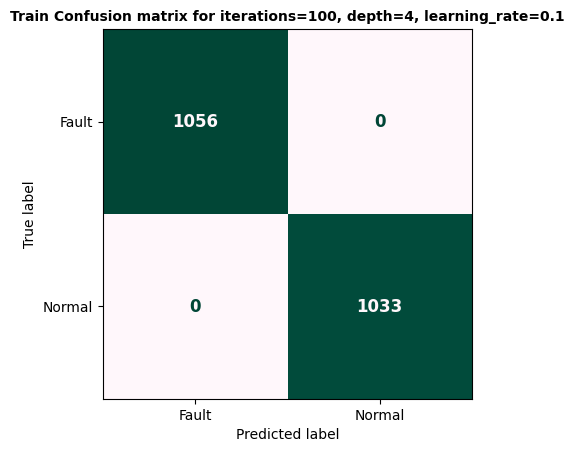

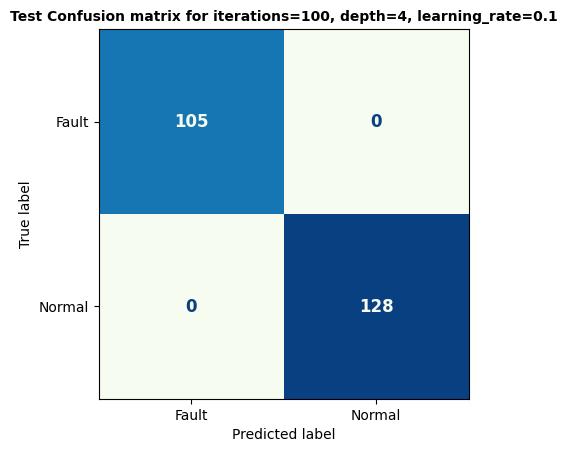

0:	learn: 0.5158718	total: 2.63ms	remaining: 260ms
1:	learn: 0.3959905	total: 5.77ms	remaining: 283ms
2:	learn: 0.3097967	total: 8.44ms	remaining: 273ms
3:	learn: 0.2453878	total: 11.1ms	remaining: 267ms
4:	learn: 0.1963423	total: 13.8ms	remaining: 262ms
5:	learn: 0.1581360	total: 16.5ms	remaining: 259ms
6:	learn: 0.1282157	total: 19.3ms	remaining: 257ms
7:	learn: 0.1042176	total: 22.2ms	remaining: 255ms
8:	learn: 0.0851661	total: 25.8ms	remaining: 261ms
9:	learn: 0.0699288	total: 28.8ms	remaining: 259ms
10:	learn: 0.0576006	total: 31.7ms	remaining: 256ms
11:	learn: 0.0475670	total: 34.5ms	remaining: 253ms
12:	learn: 0.0393879	total: 37.4ms	remaining: 250ms
13:	learn: 0.0327721	total: 40.1ms	remaining: 246ms
14:	learn: 0.0272993	total: 42.7ms	remaining: 242ms
15:	learn: 0.0230662	total: 45.4ms	remaining: 238ms
16:	learn: 0.0194035	total: 48.1ms	remaining: 235ms
17:	learn: 0.0162951	total: 50.9ms	remaining: 232ms
18:	learn: 0.0137813	total: 53.6ms	remaining: 228ms
19:	learn: 0.0116955	t

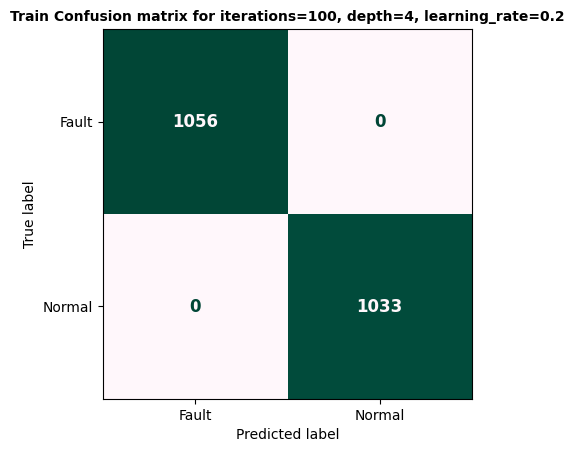

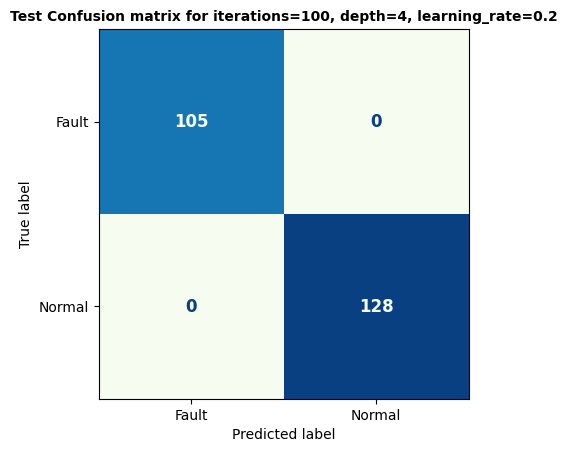

0:	learn: 0.6834208	total: 7.87ms	remaining: 779ms
1:	learn: 0.6738835	total: 14.9ms	remaining: 730ms
2:	learn: 0.6645639	total: 21.5ms	remaining: 694ms
3:	learn: 0.6554293	total: 28.1ms	remaining: 674ms
4:	learn: 0.6463962	total: 34.9ms	remaining: 663ms
5:	learn: 0.6375898	total: 41.4ms	remaining: 648ms
6:	learn: 0.6291094	total: 49.4ms	remaining: 656ms
7:	learn: 0.6207068	total: 56.4ms	remaining: 648ms
8:	learn: 0.6123569	total: 62.7ms	remaining: 634ms
9:	learn: 0.6042482	total: 69.4ms	remaining: 624ms
10:	learn: 0.5961766	total: 76.2ms	remaining: 617ms
11:	learn: 0.5882530	total: 83ms	remaining: 609ms
12:	learn: 0.5804989	total: 89.9ms	remaining: 601ms
13:	learn: 0.5728880	total: 96.6ms	remaining: 593ms
14:	learn: 0.5653386	total: 103ms	remaining: 585ms
15:	learn: 0.5579507	total: 110ms	remaining: 578ms
16:	learn: 0.5506827	total: 117ms	remaining: 570ms
17:	learn: 0.5436568	total: 124ms	remaining: 563ms
18:	learn: 0.5366451	total: 130ms	remaining: 556ms
19:	learn: 0.5298407	total: 1

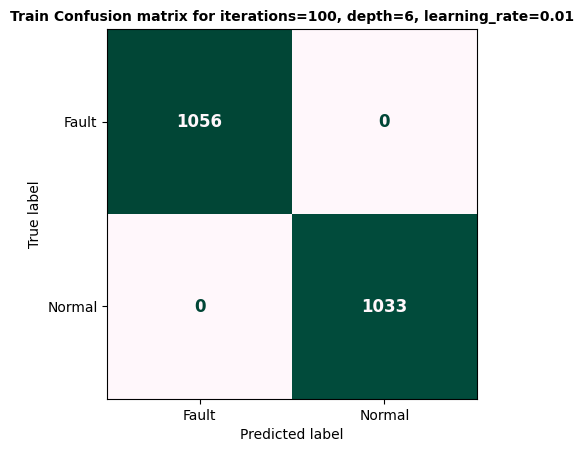

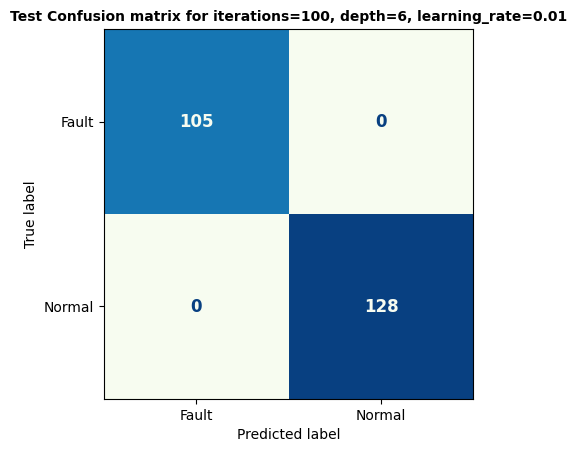

0:	learn: 0.6001971	total: 6.99ms	remaining: 692ms
1:	learn: 0.5237488	total: 14.1ms	remaining: 693ms
2:	learn: 0.4600111	total: 21.2ms	remaining: 685ms
3:	learn: 0.4060172	total: 28ms	remaining: 671ms
4:	learn: 0.3593982	total: 34.8ms	remaining: 661ms
5:	learn: 0.3194753	total: 41.5ms	remaining: 650ms
6:	learn: 0.2855193	total: 48.2ms	remaining: 641ms
7:	learn: 0.2555060	total: 55.6ms	remaining: 640ms
8:	learn: 0.2287183	total: 62.6ms	remaining: 633ms
9:	learn: 0.2054801	total: 74.9ms	remaining: 674ms
10:	learn: 0.1844947	total: 85.5ms	remaining: 692ms
11:	learn: 0.1659136	total: 92.8ms	remaining: 681ms
12:	learn: 0.1495292	total: 100ms	remaining: 670ms
13:	learn: 0.1349797	total: 107ms	remaining: 658ms
14:	learn: 0.1217238	total: 114ms	remaining: 645ms
15:	learn: 0.1099783	total: 121ms	remaining: 633ms
16:	learn: 0.0994695	total: 127ms	remaining: 621ms
17:	learn: 0.0902583	total: 134ms	remaining: 609ms
18:	learn: 0.0818358	total: 140ms	remaining: 599ms
19:	learn: 0.0744740	total: 147

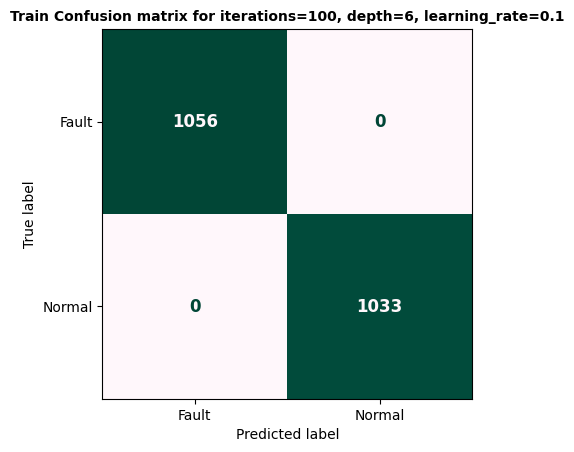

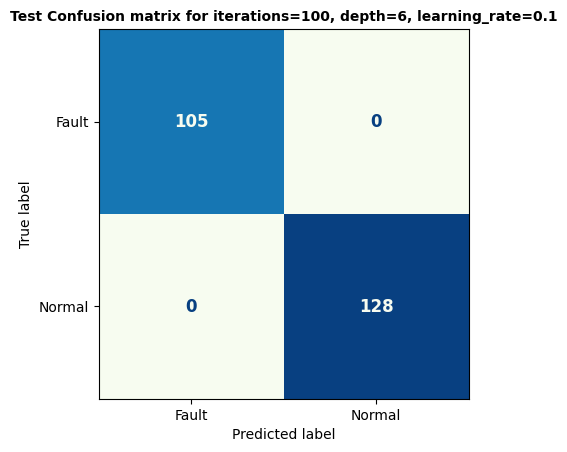

0:	learn: 0.5167424	total: 6.91ms	remaining: 684ms
1:	learn: 0.3972538	total: 14.1ms	remaining: 691ms
2:	learn: 0.3114650	total: 21.1ms	remaining: 683ms
3:	learn: 0.2471410	total: 28.3ms	remaining: 680ms
4:	learn: 0.1977021	total: 36.1ms	remaining: 686ms
5:	learn: 0.1596567	total: 45.1ms	remaining: 706ms
6:	learn: 0.1305295	total: 52.1ms	remaining: 692ms
7:	learn: 0.1070021	total: 58.9ms	remaining: 677ms
8:	learn: 0.0877452	total: 65.4ms	remaining: 661ms
9:	learn: 0.0726092	total: 72.2ms	remaining: 650ms
10:	learn: 0.0598108	total: 79.2ms	remaining: 641ms
11:	learn: 0.0495072	total: 86.4ms	remaining: 634ms
12:	learn: 0.0412367	total: 93.3ms	remaining: 624ms
13:	learn: 0.0345686	total: 99.9ms	remaining: 614ms
14:	learn: 0.0287755	total: 106ms	remaining: 603ms
15:	learn: 0.0242170	total: 114ms	remaining: 599ms
16:	learn: 0.0204469	total: 121ms	remaining: 590ms
17:	learn: 0.0175450	total: 128ms	remaining: 581ms
18:	learn: 0.0149797	total: 135ms	remaining: 576ms
19:	learn: 0.0129377	total:

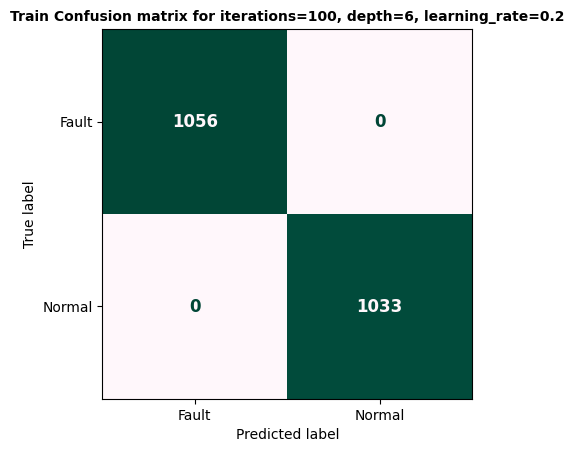

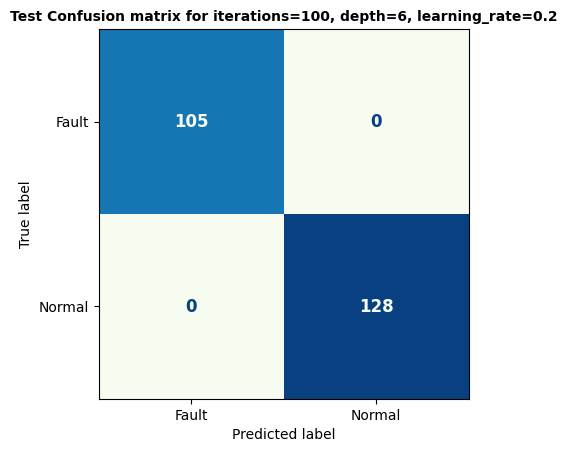

0:	learn: 0.6835262	total: 33ms	remaining: 3.27s
1:	learn: 0.6740960	total: 54.8ms	remaining: 2.69s
2:	learn: 0.6648110	total: 77.1ms	remaining: 2.49s
3:	learn: 0.6556487	total: 99.7ms	remaining: 2.39s
4:	learn: 0.6467223	total: 121ms	remaining: 2.29s
5:	learn: 0.6380476	total: 143ms	remaining: 2.24s
6:	learn: 0.6295453	total: 168ms	remaining: 2.24s
7:	learn: 0.6212320	total: 203ms	remaining: 2.33s
8:	learn: 0.6129675	total: 227ms	remaining: 2.3s
9:	learn: 0.6048220	total: 266ms	remaining: 2.39s
10:	learn: 0.5968511	total: 289ms	remaining: 2.34s
11:	learn: 0.5891293	total: 311ms	remaining: 2.28s
12:	learn: 0.5814863	total: 334ms	remaining: 2.23s
13:	learn: 0.5739168	total: 359ms	remaining: 2.2s
14:	learn: 0.5665554	total: 380ms	remaining: 2.15s
15:	learn: 0.5592025	total: 401ms	remaining: 2.11s
16:	learn: 0.5520317	total: 423ms	remaining: 2.06s
17:	learn: 0.5450058	total: 445ms	remaining: 2.03s
18:	learn: 0.5380616	total: 469ms	remaining: 2s
19:	learn: 0.5312135	total: 499ms	remaining:

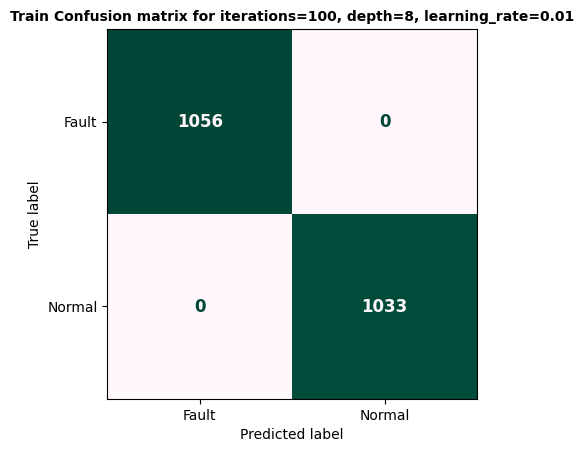

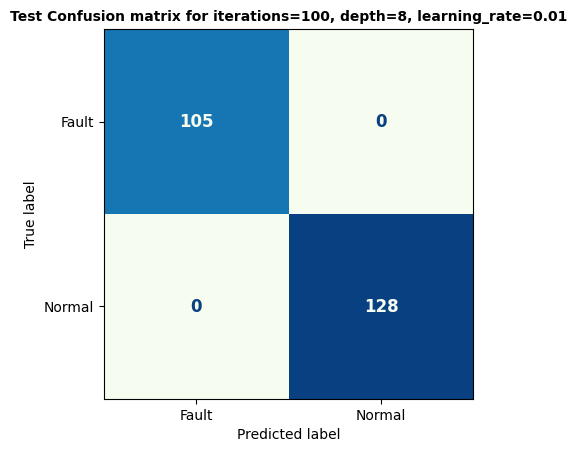

0:	learn: 0.6011575	total: 68.2ms	remaining: 6.76s
1:	learn: 0.5253825	total: 109ms	remaining: 5.34s
2:	learn: 0.4616617	total: 149ms	remaining: 4.82s
3:	learn: 0.4072892	total: 193ms	remaining: 4.63s
4:	learn: 0.3610899	total: 233ms	remaining: 4.43s
5:	learn: 0.3216314	total: 276ms	remaining: 4.32s
6:	learn: 0.2873703	total: 322ms	remaining: 4.27s
7:	learn: 0.2575411	total: 365ms	remaining: 4.2s
8:	learn: 0.2309051	total: 403ms	remaining: 4.07s
9:	learn: 0.2073154	total: 443ms	remaining: 3.99s
10:	learn: 0.1865481	total: 474ms	remaining: 3.83s
11:	learn: 0.1684903	total: 518ms	remaining: 3.8s
12:	learn: 0.1522167	total: 566ms	remaining: 3.78s
13:	learn: 0.1375619	total: 606ms	remaining: 3.73s
14:	learn: 0.1247163	total: 642ms	remaining: 3.64s
15:	learn: 0.1130184	total: 678ms	remaining: 3.56s
16:	learn: 0.1025706	total: 725ms	remaining: 3.54s
17:	learn: 0.0932503	total: 774ms	remaining: 3.52s
18:	learn: 0.0847446	total: 800ms	remaining: 3.41s
19:	learn: 0.0770020	total: 826ms	remainin

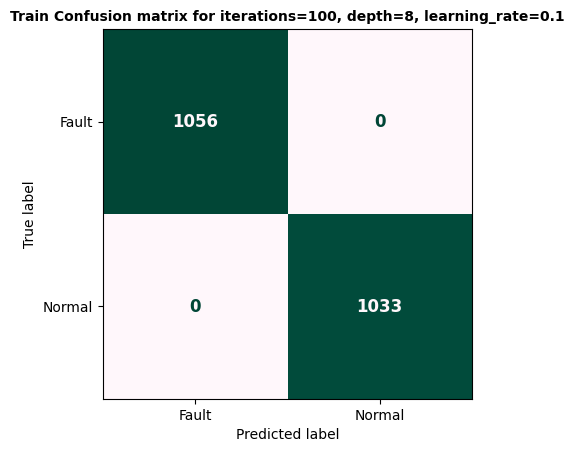

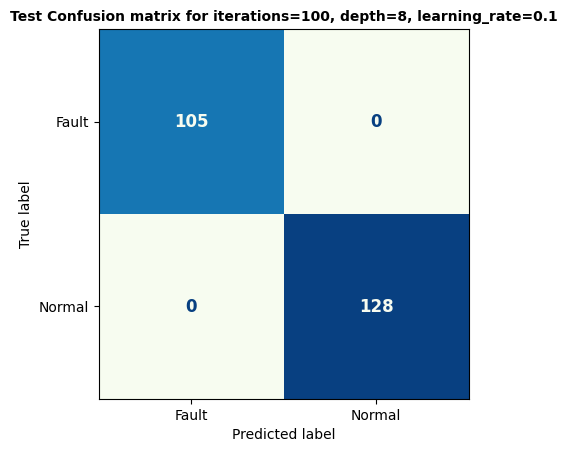

0:	learn: 0.5184608	total: 32.3ms	remaining: 3.2s
1:	learn: 0.3997201	total: 53.8ms	remaining: 2.64s
2:	learn: 0.3132771	total: 75ms	remaining: 2.43s
3:	learn: 0.2486023	total: 98.2ms	remaining: 2.35s
4:	learn: 0.1995835	total: 119ms	remaining: 2.27s
5:	learn: 0.1623565	total: 141ms	remaining: 2.2s
6:	learn: 0.1326084	total: 162ms	remaining: 2.15s
7:	learn: 0.1091831	total: 184ms	remaining: 2.11s
8:	learn: 0.0897272	total: 206ms	remaining: 2.08s
9:	learn: 0.0740897	total: 229ms	remaining: 2.06s
10:	learn: 0.0615034	total: 267ms	remaining: 2.16s
11:	learn: 0.0516404	total: 289ms	remaining: 2.12s
12:	learn: 0.0433701	total: 310ms	remaining: 2.08s
13:	learn: 0.0364926	total: 333ms	remaining: 2.04s
14:	learn: 0.0310826	total: 354ms	remaining: 2s
15:	learn: 0.0264616	total: 375ms	remaining: 1.97s
16:	learn: 0.0226553	total: 397ms	remaining: 1.94s
17:	learn: 0.0195355	total: 419ms	remaining: 1.91s
18:	learn: 0.0167494	total: 444ms	remaining: 1.89s
19:	learn: 0.0143319	total: 472ms	remaining:

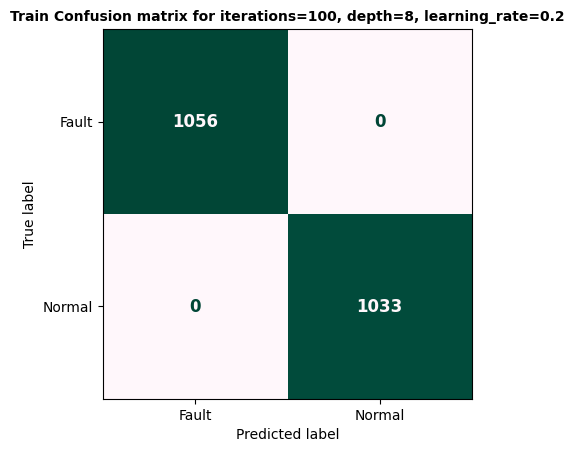

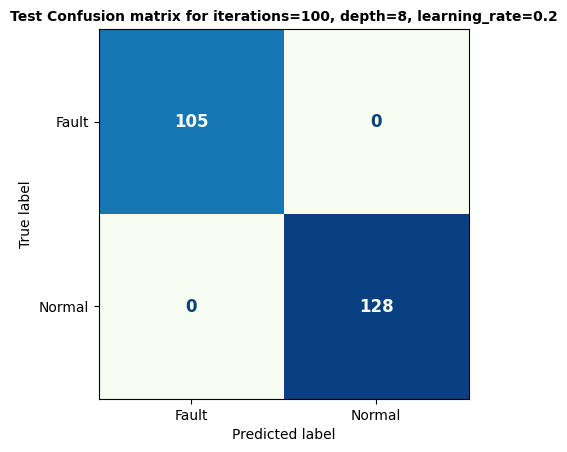

    iterations  depth  learning_rate  train_accuracy  test_accuracy  \
0           10      4           0.01             1.0            1.0   
1           10      4           0.10             1.0            1.0   
2           10      4           0.20             1.0            1.0   
3           10      6           0.01             1.0            1.0   
4           10      6           0.10             1.0            1.0   
5           10      6           0.20             1.0            1.0   
6           10      8           0.01             1.0            1.0   
7           10      8           0.10             1.0            1.0   
8           10      8           0.20             1.0            1.0   
9           50      4           0.01             1.0            1.0   
10          50      4           0.10             1.0            1.0   
11          50      4           0.20             1.0            1.0   
12          50      6           0.01             1.0            1.0   
13    

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from catboost import CatBoostClassifier
import time
import pandas as pd

# Convert the data to C-contiguous order (if necessary)
X_train = np.ascontiguousarray(X_train)
X_test = np.ascontiguousarray(X_test)

# Initialize lists to store the metrics for train and test sets
results = []

# Test different values of num_leaves, max_depth, and learning_rate
iterations_values = [10, 50, 100]
depth_values = [4, 6, 8]
learning_rate_values = [0.01, 0.1, 0.2]

for iterations in iterations_values:
    for depth in depth_values:
        for learning_rate in learning_rate_values:
            # Initialize the CatBoostClassifier
            catboost = CatBoostClassifier(
                iterations=iterations, depth=depth, learning_rate=learning_rate, loss_function='MultiClass'
            )

            # Start the timer
            start = time.time()

            # Fit the model to the training data
            catboost.fit(X_train, y_train)

            # Make predictions on the test data
            y_pred = catboost.predict(X_test)

            # Calculate and print test metrics
            print("iterations:", iterations)
            print("depth:", depth)
            print("learning_rate:", learning_rate)
            print("Test Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
            print("Test Classification Report:\n", classification_report(y_test, y_pred))

            # Calculate and print train metrics
            y_pred_train = catboost.predict(X_train)
            print("Train Confusion Matrix:\n", confusion_matrix(y_train, y_pred_train))
            print("Train Classification Report:\n", classification_report(y_train, y_pred_train))

            # Draw the confusion matrix for train data
            conf_matrix_train = confusion_matrix(y_train, y_pred_train)
            disp_train = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_train, display_labels=np.unique(y_train))
            disp_train.plot(cmap='PuBuGn', values_format='d', colorbar=False)  # Remove colorbar
            plt.title(f'Train Confusion matrix for iterations={iterations}, depth={depth}, learning_rate={learning_rate}', fontsize=10, fontweight='bold')
            for text in disp_train.text_.ravel():
                text.set_fontsize(12)
                text.set_fontweight('bold')
            plt.show()

            # Draw the confusion matrix for test data
            conf_matrix_test = confusion_matrix(y_test, y_pred)
            disp_test = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_test, display_labels=np.unique(y_test))
            disp_test.plot(cmap='GnBu', values_format='d', colorbar=False)  # Remove colorbar
            plt.title(f'Test Confusion matrix for iterations={iterations}, depth={depth}, learning_rate={learning_rate}', fontsize=10, fontweight='bold')
            for text in disp_test.text_.ravel():
                text.set_fontsize(12)
                text.set_fontweight('bold')
            plt.show()

            # Stop the timer
            end = time.time()

            # Append metrics to the results list
            results.append({
                'iterations': iterations,
                'depth': depth,
                'learning_rate': learning_rate,
                'train_accuracy': catboost.score(X_train, y_train),
                'test_accuracy': catboost.score(X_test, y_test),
                'train_precision': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['precision'],
                'test_precision': classification_report(y_test, y_pred, output_dict=True)['macro avg']['precision'],
                'train_recall': classification_report(y_train, y_pred_train, output_dict=True)['macro avg']['recall'],
                'test_recall': classification_report(y_test, y_pred, output_dict=True)['macro avg']['recall'],
                'train_tp': conf_matrix_train[1, 1],
                'test_tp': conf_matrix_test[1, 1],
                'train_tn': conf_matrix_train[0, 0],
                'test_tn': conf_matrix_test[0, 0],
                'train_fp': conf_matrix_train[0, 1],
                'test_fp': conf_matrix_test[0, 1],
                'train_fn': conf_matrix_train[1, 0],
                'test_fn': conf_matrix_test[1, 0],
                'time': end - start
            })

# Create a DataFrame from the results list
comparison_df = pd.DataFrame(results)

# Print the comparison table
print(comparison_df)

# Save results to Excel
excel_filename = '/content/drive/MyDrive/crwu-qauntum/Results_classical/CatBoostClassifier.xlsx'
comparison_df.to_excel(excel_filename, index=False)
print(f'Results saved to {excel_filename}')

# Find the row with the best test accuracy
best_model_row = comparison_df.loc[comparison_df['test_accuracy'].idxmax()]

# Print information about the best model
print("Best Model Results:")
print(f"iterations: {best_model_row['iterations']}")
print(f"depth: {best_model_row['depth']}")
print(f"learning_rate: {best_model_row['learning_rate']}")
print(f"Train Accuracy: {best_model_row['train_accuracy']}")
print(f"Test Accuracy: {best_model_row['test_accuracy']}")
print(f"Train Precision: {best_model_row['train_precision']}")
print(f"Test Precision: {best_model_row['test_precision']}")
print(f"Train Recall: {best_model_row['train_recall']}")
print(f"Test Recall: {best_model_row['test_recall']}")

# Rank all models based on test metrics
comparison_df['F1'] = (2 * comparison_df['test_precision'] * comparison_df['test_recall']) / (comparison_df['test_precision'] + comparison_df['test_recall'])
ranked_models = comparison_df.sort_values(by=['F1', 'test_recall', 'test_precision', 'test_accuracy'], ascending=False)

# Prepare ranking strings
ranking_strings = []
for index, row in ranked_models.iterrows():
    ranking_strings.append(f"Model {index + 1} ({row['test_accuracy'] * 100:.2f}%)")

# Print ranked models
print("Ranked Models:")
print(" > ".join(ranking_strings))

# Save ranked models to Excel
ranked_excel_filename = '//content/drive/MyDrive/crwu-qauntum/Results_classical/CatBoostClassifier_ranked_models.xlsx'
ranked_models.to_excel(ranked_excel_filename, index=False)
print(f'Ranked models saved to {ranked_excel_filename}')

# Print the total number of models trained
total_models_trained = len(comparison_df)
print(f"Total models trained: {total_models_trained}")
